In [1]:
# --------------------------------------------------------------------------
# Part A · 코드
# --------------------------------------------------------------------------
# 아래 셀들은 실행하면 파일을 쓴다. 위에서 아래로 한 번씩 실행하면 된다.
# 각 파일 상단의 주석이 그 모듈이 왜 그렇게 짜였는지를 설명한다.
# --------------------------------------------------------------------------

import os
os.makedirs('/kaggle/working/sam_lab', exist_ok=True)
os.makedirs('/kaggle/working/tests', exist_ok=True)
os.chdir('/kaggle/working')
print("cwd:", os.getcwd())

cwd: /kaggle/working


In [2]:
%%writefile sam_lab/config.py
# --------------------------------------------------------------------------
# A1 · config.py — 실험 하나를 결정하는 단일 Config
# --------------------------------------------------------------------------
# run 하나를 바꿀 수 있는 모든 값이 여기 모여 있고, 통째로 JSON으로 저장된다.
# tag 필드는 스윕이 LR·rho를 바꿀 때 run 폴더가 겹치지 않게 하는 장치다.
# --------------------------------------------------------------------------

"""One config object decides an entire run.

Every knob that can change a result lives here, and the whole object is written
to the run directory as JSON. If a number in the paper cannot be traced back to
one of these files, it did not happen.
"""

from dataclasses import dataclass, asdict, field
import json
import hashlib
from pathlib import Path


@dataclass
class Config:
    # ---- identity -------------------------------------------------------
    exp: str = "pilot"                 # experiment family, e.g. "s0" / "s1"
    seed: int = 0
    notes: str = ""
    tag: str = ""                      # appended to run_id; set it whenever a
                                       # sweep varies something that run_id
                                       # does not otherwise encode (lr, rho...)
                                       # or the runs collide and overwrite

    # ---- data -----------------------------------------------------------
    dataset: str = "cifar100"          # cifar100 | imagenet100
    data_root: str = "./data"
    img_size: int = 32
    num_classes: int = 100
    num_workers: int = 4
    label_noise: float = 0.0           # fraction of randomized train labels
                                       # (memorization probe; 0.0 = off)

    # ---- model ----------------------------------------------------------
    arch: str = "resnet18"             # resnet18 | resnet50 | vit_s

    # ---- base optimizer -------------------------------------------------
    optimizer: str = "adamw"           # adamw | lion | muon
    lr: float = 1e-3                   # peak LR (Muon: the Muon-group LR)
    aux_lr: float = 3e-4               # Muon only: AdamW-group LR
    beta1: float = 0.9
    beta2: float = 0.95
    momentum: float = 0.95             # Muon only
    weight_decay: float = 0.05
    grad_clip: float = 0.0             # 0 = off

    # ---- schedule (warmup - stable - decay) -----------------------------
    epochs: int = 30
    batch_size: int = 256
    warmup_frac: float = 0.05
    decay_frac: float = 0.20
    min_lr_frac: float = 0.0

    # ---- SAM ------------------------------------------------------------
    sam_mode: str = "off"              # off | decay | full
    sam_rho: float = 0.05
    sam_norm: str = "l2"               # l2 | spectral

    # ---- runtime --------------------------------------------------------
    amp: bool = True
    channels_last: bool = True
    out_dir: str = "./runs"
    ckpt_every: int = 1                # epochs
    eval_every: int = 1
    deterministic: bool = False        # True is slower; use for final runs
    max_seconds: float = 0.0           # >0: stop cleanly before a session cap

    # ---------------------------------------------------------------------

    @property
    def run_id(self) -> str:
        base = (f"{self.exp}-{self.dataset}-{self.arch}"
                f"-{self.optimizer}-sam_{self.sam_mode}-s{self.seed}")
        return f"{base}-{self.tag}" if self.tag else base

    @property
    def run_dir(self) -> Path:
        return Path(self.out_dir) / self.run_id

    def fingerprint(self) -> str:
        """Hash of everything except bookkeeping. Two runs sharing this hash
        should be identical experiments."""
        d = asdict(self)
        for k in ("out_dir", "num_workers", "ckpt_every", "eval_every",
                  "notes", "tag", "max_seconds"):
            d.pop(k, None)
        blob = json.dumps(d, sort_keys=True)
        return hashlib.sha1(blob.encode()).hexdigest()[:12]

    def save(self, path=None):
        path = Path(path) if path else self.run_dir / "config.json"
        path.parent.mkdir(parents=True, exist_ok=True)
        payload = asdict(self)
        payload["_fingerprint"] = self.fingerprint()
        payload["_run_id"] = self.run_id
        path.write_text(json.dumps(payload, indent=2))
        return path

    @classmethod
    def load(cls, path):
        d = json.loads(Path(path).read_text())
        d = {k: v for k, v in d.items() if not k.startswith("_")}
        return cls(**d)

    @classmethod
    def from_overrides(cls, **kw):
        valid = set(cls.__dataclass_fields__)
        bad = set(kw) - valid
        if bad:
            raise ValueError(f"unknown config keys: {sorted(bad)}")
        return cls(**kw)


# ---------------------------------------------------------------------------
# presets -- the pilot grid from S0
# ---------------------------------------------------------------------------

CIFAR_BASE = dict(
    exp="s0", dataset="cifar100", img_size=32, num_classes=100,
    arch="resnet18", epochs=30, batch_size=256, num_workers=2,
)

#: per-optimizer peak LRs for the CIFAR-100 pilot. These are starting points,
#: not tuned values -- S0's job is to replace them with swept ones.
LR_GUESS = {
    "adamw": dict(lr=1e-3, weight_decay=0.05),
    "lion":  dict(lr=1e-4, weight_decay=0.5),   # Lion wants ~10x smaller LR
    "muon":  dict(lr=0.02, aux_lr=3e-4, weight_decay=0.05),
}


def pilot_grid(seeds=(0,), sam_modes=("off", "decay"),
               optimizers=("adamw", "lion", "muon")):
    """The S0 pilot: every optimizer x every SAM mode x every seed."""
    for opt in optimizers:
        for mode in sam_modes:
            for seed in seeds:
                yield Config(**{**CIFAR_BASE, **LR_GUESS[opt],
                                "optimizer": opt, "sam_mode": mode, "seed": seed})

Writing sam_lab/config.py


In [3]:
%%writefile sam_lab/schedule.py
# --------------------------------------------------------------------------
# A2 · schedule.py — WSD 스케줄과 SAM 창
# --------------------------------------------------------------------------
# SAM을 켜는 구간을 LR decay 구간과 같은 비율로 정의한다.
# ICLR'25 연구가 "SAM은 마지막 감쇠 구간에만 켜도 충분하다"를 보였기 때문이다.
# --------------------------------------------------------------------------

"""Warmup - Stable - Decay learning rate schedule, and the SAM window.

The SAM window is defined against the *same* decay fraction as the LR schedule,
because the whole premise of the experiment is that SAM belongs in the
annealing phase (Andriushchenko et al., ICLR'25; and the CMU pretraining paper
that applies SAM only during LR decay for ~10% extra cost).
"""

import math


def wsd_multiplier(step: int, total_steps: int, warmup_frac: float,
                   decay_frac: float, min_lr_frac: float = 0.0) -> float:
    """LR multiplier in [min_lr_frac, 1.0] for a warmup-stable-decay schedule."""
    if total_steps <= 0:
        return 1.0
    warmup = int(total_steps * warmup_frac)
    decay = int(total_steps * decay_frac)
    decay_start = max(warmup, total_steps - decay)

    if step < warmup:
        return (step + 1) / max(1, warmup)
    if step < decay_start:
        return 1.0

    t = (step - decay_start) / max(1, total_steps - decay_start)
    t = min(1.0, max(0.0, t))
    cosine = 0.5 * (1.0 + math.cos(math.pi * t))
    return min_lr_frac + (1.0 - min_lr_frac) * cosine


def decay_start_step(total_steps: int, warmup_frac: float, decay_frac: float) -> int:
    warmup = int(total_steps * warmup_frac)
    decay = int(total_steps * decay_frac)
    return max(warmup, total_steps - decay)


def sam_active(step: int, total_steps: int, mode: str,
               warmup_frac: float, decay_frac: float) -> bool:
    """Is SAM switched on at this step?"""
    if mode == "off":
        return False
    if mode == "full":
        return True
    if mode == "decay":
        return step >= decay_start_step(total_steps, warmup_frac, decay_frac)
    raise ValueError(f"unknown sam_mode: {mode}")


def apply_lr(optimizer, multiplier: float):
    """Scale every group's LR from its stored base_lr."""
    for group in optimizer.param_groups:
        if "base_lr" not in group:
            group["base_lr"] = group["lr"]
        group["lr"] = group["base_lr"] * multiplier


def snapshot_base_lrs(optimizer):
    for group in optimizer.param_groups:
        group.setdefault("base_lr", group["lr"])

Writing sam_lab/schedule.py


In [4]:
%%writefile sam_lab/optim.py
# --------------------------------------------------------------------------
# A3 · optim.py — Lion, Muon, SAM Overlay  [핵심 파일]
# --------------------------------------------------------------------------
# 이 프로젝트가 제안하는 옵티마이저가 여기 있다: SAM Overlay.
#
# SAM Overlay
#   perturb -> 두 번째 backward -> restore -> opt.step().
#   기저 옵티마이저의 모멘텀 버퍼를 한 번도 건드리지 않는다.
#   v1 하이브리드의 모멘텀 단절 문제가 여기서 사라진다.
#
#   AMP 충돌 회피: epsilon은 정규화된 방향이라 GradScaler의 스케일 상수가
#   정확히 상쇄된다. unscale_ 호출이 불필요하다.
#
#   restore는 eps를 빼지 않고 원본을 복사한다. float32에서 add_ 후 sub_ 는
#   약 1 ULP를 남기고, 그 누적이 하필 이 연구가 재려는 "미세 교란 민감도"를
#   오염시킨다.
#
# Newton-Schulz
#   완전 직교화가 아니다. 5 step 안에 특이값을 0.68~1.05 대역으로 압축하는
#   근사다. XtX = I 를 기대하고 검증하면 잘못된 실패를 본다.
#
# Muon
#   >=2D 은닉 가중치만. norm·bias·head는 AdamW. 4D conv는 flatten 후 적용.
# --------------------------------------------------------------------------

"""Optimizers and the SAM overlay.

Nothing in this file is a new algorithm. Lion and Muon are reference
implementations ported for this project. The SAM overlay is a *gradient
transformer*: it perturbs weights, lets a second backward pass overwrite the
gradients, restores the weights, and hands the result to whatever base
optimizer is underneath. The base optimizer's momentum state is never touched,
which is what fixes the "momentum discontinuity" of naive optimizer switching.
"""

import torch
from torch.optim import Optimizer


# --------------------------------------------------------------------------
# Newton-Schulz orthogonalization (used by Muon, and by spectral-mode SAM)
# --------------------------------------------------------------------------

@torch.no_grad()
def newton_schulz5(G: torch.Tensor, steps: int = 5, eps: float = 1e-7) -> torch.Tensor:
    """Quintic Newton-Schulz iteration -> approximately orthogonal matrix.

    Coefficients from Jordan's Muon reference implementation. Runs in bf16 on
    CUDA (that is what the reference does and it is stable there); falls back to
    fp32 on CPU where bf16 matmul is slow.
    """
    assert G.ndim >= 2, "newton_schulz5 expects a matrix"
    a, b, c = 3.4445, -4.7750, 2.0315

    X = G.bfloat16() if G.is_cuda else G.float()
    transposed = X.size(-2) > X.size(-1)
    if transposed:
        X = X.mT

    X = X / (X.norm(dim=(-2, -1), keepdim=True) + eps)
    for _ in range(steps):
        A = X @ X.mT
        B = b * A + c * (A @ A)
        X = a * X + B @ X

    if transposed:
        X = X.mT
    return X


# --------------------------------------------------------------------------
# Lion
# --------------------------------------------------------------------------

class Lion(Optimizer):
    """Chen et al., 'Symbolic Discovery of Optimization Algorithms' (2023).

        c_t    = b1 * m_{t-1} + (1 - b1) * g_t
        theta -= lr * (sign(c_t) + wd * theta)
        m_t    = b2 * m_{t-1} + (1 - b2) * g_t

    Note the update direction uses b1 but the state update uses b2. That
    asymmetry is the whole trick; do not "simplify" it.
    """

    def __init__(self, params, lr=1e-4, betas=(0.9, 0.99), weight_decay=0.0):
        if lr <= 0.0:
            raise ValueError(f"lr must be positive, got {lr}")
        super().__init__(params, dict(lr=lr, betas=betas, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = closure() if closure is not None else None
        for group in self.param_groups:
            lr = group["lr"]
            b1, b2 = group["betas"]
            wd = group["weight_decay"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad
                state = self.state[p]
                if "m" not in state:
                    state["m"] = torch.zeros_like(p)
                m = state["m"]

                # update direction: sign(b1 * m + (1 - b1) * g).  `mul` (not
                # `mul_`) so the momentum buffer itself is not clobbered here.
                update = m.mul(b1).add_(g, alpha=1.0 - b1).sign_()

                p.mul_(1.0 - lr * wd)          # decoupled weight decay
                p.add_(update, alpha=-lr)

                m.mul_(b2).add_(g, alpha=1.0 - b2)
        return loss


# --------------------------------------------------------------------------
# Muon (+ AdamW for the parameters Muon should not touch)
# --------------------------------------------------------------------------

class Muon(Optimizer):
    """Muon for >=2D hidden weights, AdamW for everything else.

    A single optimizer object handles both so that AMP's GradScaler has one
    thing to step. Each param group carries a ``use_muon`` flag; build the
    groups with :func:`build_muon_groups`.

    4D conv kernels are flattened to ``(out_channels, in*kh*kw)`` before
    orthogonalization, which is the standard way to apply Muon to CNNs.
    """

    def __init__(self, param_groups):
        groups = []
        for g in param_groups:
            g = dict(g)
            g.setdefault("use_muon", True)
            if g["use_muon"]:
                g.setdefault("lr", 0.02)
                g.setdefault("momentum", 0.95)
                g.setdefault("nesterov", True)
                g.setdefault("ns_steps", 5)
                g.setdefault("weight_decay", 0.0)
            else:
                g.setdefault("lr", 3e-4)
                g.setdefault("betas", (0.9, 0.95))
                g.setdefault("eps", 1e-8)
                g.setdefault("weight_decay", 0.0)
            groups.append(g)
        super().__init__(groups, {})

    @torch.no_grad()
    def step(self, closure=None):
        loss = closure() if closure is not None else None
        for group in self.param_groups:
            if group["use_muon"]:
                self._step_muon(group)
            else:
                self._step_adamw(group)
        return loss

    def _step_muon(self, group):
        lr, mom, wd = group["lr"], group["momentum"], group["weight_decay"]
        for p in group["params"]:
            if p.grad is None:
                continue
            g = p.grad
            state = self.state[p]
            if "buf" not in state:
                state["buf"] = torch.zeros_like(g)
            buf = state["buf"]
            buf.mul_(mom).add_(g)
            d = g.add(buf, alpha=mom) if group["nesterov"] else buf

            flat = d.reshape(d.size(0), -1)
            u = newton_schulz5(flat, group["ns_steps"]).reshape(p.shape).to(p.dtype)

            # aspect-ratio correction so the update norm does not depend on
            # how rectangular the (flattened) weight matrix is
            scale = max(1.0, flat.size(-2) / flat.size(-1)) ** 0.5

            p.mul_(1.0 - lr * wd)
            p.add_(u, alpha=-lr * scale)

    def _step_adamw(self, group):
        lr, (b1, b2) = group["lr"], group["betas"]
        eps, wd = group["eps"], group["weight_decay"]
        for p in group["params"]:
            if p.grad is None:
                continue
            g = p.grad
            state = self.state[p]
            if "step" not in state:
                state["step"] = 0
                state["m"] = torch.zeros_like(p)
                state["v"] = torch.zeros_like(p)
            state["step"] += 1
            t = state["step"]
            m, v = state["m"], state["v"]

            m.mul_(b1).add_(g, alpha=1.0 - b1)
            v.mul_(b2).addcmul_(g, g, value=1.0 - b2)

            m_hat = m / (1.0 - b1 ** t)
            v_hat = v / (1.0 - b2 ** t)

            p.mul_(1.0 - lr * wd)
            p.addcdiv_(m_hat, v_hat.sqrt().add_(eps), value=-lr)


def build_muon_groups(model, muon_lr=0.02, aux_lr=3e-4, weight_decay=0.05,
                      momentum=0.95, aux_betas=(0.9, 0.95)):
    """Split a model into (Muon-handled, AdamW-handled) parameter groups.

    Muon gets >=2D hidden weights. Norms, biases and the classifier head stay
    on AdamW -- putting the head on Muon is a known way to make training
    unstable, and the reference implementation does the same split.
    """
    head_markers = ("fc.", "head.", "classifier.", "embed")
    muon_params, aux_params = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        is_head = any(m in name for m in head_markers)
        if p.ndim >= 2 and not is_head:
            muon_params.append(p)
        else:
            aux_params.append(p)

    groups = []
    if muon_params:
        groups.append(dict(params=muon_params, use_muon=True, lr=muon_lr,
                           momentum=momentum, weight_decay=weight_decay))
    if aux_params:
        groups.append(dict(params=aux_params, use_muon=False, lr=aux_lr,
                           betas=aux_betas, weight_decay=weight_decay))
    return groups


# --------------------------------------------------------------------------
# SAM overlay
# --------------------------------------------------------------------------

class SAMOverlay:
    """Sharpness-Aware Minimization applied as a gradient transformer.

    Usage inside a training step::

        loss.backward()                      # grads at w
        if sam.perturb():                    # w <- w + eps(g)
            opt.zero_grad(set_to_none=True)
            loss2 = criterion(model(x), y)
            loss2.backward()                 # grads at w + eps
            sam.restore()                    # w <- w
        opt.step()                           # base optimizer, state untouched

    AMP note: ``eps`` is a *normalized* direction, so a constant GradScaler
    factor cancels out of it exactly. That means perturb() can read scaled
    fp16 gradients directly and no ``unscale_`` call is needed -- which matters,
    because GradScaler refuses to unscale the same optimizer twice per step.
    Non-finite gradients (fp16 overflow) are detected and the step falls back
    to plain (non-SAM) behaviour for that batch.

    Modes:
      ``l2``        global L2 normalization over all parameters (standard SAM)
      ``spectral``  per-matrix orthogonalized direction for >=2D params,
                    layerwise L2 for the rest. This is the variant that pairs
                    naturally with Muon (cf. arXiv 2607.26001) and is kept as an
                    ablation, not the default.
    """

    def __init__(self, params, rho=0.05, norm="l2", ns_steps=5):
        if norm not in ("l2", "spectral"):
            raise ValueError(f"unknown SAM norm mode: {norm}")
        self.params = [p for p in params if p.requires_grad]
        self.rho = rho
        self.norm = norm
        self.ns_steps = ns_steps
        self._applied = []          # [(param, pre-perturbation values)]
        self.n_skipped = 0          # batches where perturbation was skipped

    @torch.no_grad()
    def perturb(self) -> bool:
        """Add eps to the weights. Returns False if it could not be computed."""
        entries = [(p, p.grad.detach()) for p in self.params if p.grad is not None]
        if not entries:
            return False

        if self.norm == "l2":
            total = torch.norm(torch.stack([g.float().norm() for _, g in entries]))
            if not torch.isfinite(total) or float(total) == 0.0:
                self.n_skipped += 1
                return False
            coeff = self.rho / (float(total) + 1e-12)
            eps_list = [(p, (g.float() * coeff).to(p.dtype)) for p, g in entries]
        else:
            eps_list = []
            for p, g in entries:
                gf = g.float()
                if not torch.isfinite(gf).all():
                    self.n_skipped += 1
                    return False
                if p.ndim >= 2:
                    flat = gf.reshape(gf.size(0), -1)
                    e = newton_schulz5(flat, self.ns_steps).reshape(p.shape)
                    e = (e.float() * self.rho).to(p.dtype)
                else:
                    n = float(gf.norm())
                    e = torch.zeros_like(p) if n == 0.0 else ((gf / n) * self.rho).to(p.dtype)
                eps_list.append((p, e))

        for _, e in eps_list:
            if not torch.isfinite(e).all():
                self.n_skipped += 1
                return False

        # Keep the pre-perturbation values rather than eps itself. Restoring
        # with sub_(eps) is not exact in float32 -- add/sub round-trips leave
        # ~1 ULP behind, which would inject a small unintended perturbation on
        # every SAM step. copy_ back is exact and costs the same memory.
        self._applied = []
        for p, e in eps_list:
            self._applied.append((p, p.detach().clone()))
            p.add_(e)
        return True

    @torch.no_grad()
    def restore(self):
        for p, original in self._applied:
            p.copy_(original)
        self._applied = []


# --------------------------------------------------------------------------
# factory
# --------------------------------------------------------------------------

def build_optimizer(model, cfg):
    """Build the base optimizer named by ``cfg.optimizer``."""
    name = cfg.optimizer.lower()
    if name == "adamw":
        return torch.optim.AdamW(model.parameters(), lr=cfg.lr,
                                 betas=(cfg.beta1, cfg.beta2),
                                 weight_decay=cfg.weight_decay)
    if name == "lion":
        return Lion(model.parameters(), lr=cfg.lr,
                    betas=(cfg.beta1, cfg.beta2),
                    weight_decay=cfg.weight_decay)
    if name == "muon":
        groups = build_muon_groups(model, muon_lr=cfg.lr, aux_lr=cfg.aux_lr,
                                   weight_decay=cfg.weight_decay,
                                   momentum=cfg.momentum)
        return Muon(groups)
    raise ValueError(f"unknown optimizer: {cfg.optimizer}")

Writing sam_lab/optim.py


In [5]:
%%writefile sam_lab/models.py
# --------------------------------------------------------------------------
# A4 · models.py — 모델
# --------------------------------------------------------------------------
# 32x32 입력에 ImageNet의 7x7 stride-2 stem을 쓰면 정보를 너무 버린다.
# img_size <= 64 이면 3x3 stride-1로 교체된다.
# --------------------------------------------------------------------------

"""Models.

ResNet is used with two different stems. The ImageNet stem (7x7 stride-2 conv
plus maxpool) throws away far too much on a 32x32 CIFAR image, so the CIFAR
pilot uses the standard 3x3 stride-1 replacement. Getting this wrong is the
classic way to produce a CIFAR baseline that looks mysteriously bad.
"""

import torch
import torch.nn as nn


def build_model(cfg):
    arch = cfg.arch.lower()

    if arch in ("resnet18", "resnet50"):
        from torchvision.models import resnet18, resnet50
        net = {"resnet18": resnet18, "resnet50": resnet50}[arch](
            weights=None, num_classes=cfg.num_classes)
        if cfg.img_size <= 64:
            net.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1,
                                  padding=1, bias=False)
            net.maxpool = nn.Identity()
        return net

    if arch == "vit_s":
        raise NotImplementedError(
            "ViT-S/16 is an S4 item. Add it only after the ResNet track has a "
            "result table, so the extra axis does not delay the first finding."
        )

    raise ValueError(f"unknown arch: {cfg.arch}")


@torch.no_grad()
def count_params(model):
    total = sum(p.numel() for p in model.parameters() if p.requires_grad)
    matrix = sum(p.numel() for n, p in model.named_parameters()
                 if p.requires_grad and p.ndim >= 2)
    return dict(total=total, matrix=matrix, other=total - matrix)


def swap_head(model, num_classes):
    """Replace the classifier head, returning the old one.

    Used by the forgetting protocol: fine-tune with a fresh head, then put the
    original head back and re-measure the pretraining task.
    """
    if hasattr(model, "fc"):
        old, in_f = model.fc, model.fc.in_features
        model.fc = nn.Linear(in_f, num_classes).to(next(model.parameters()).device)
        return old
    if hasattr(model, "head"):
        old, in_f = model.head, model.head.in_features
        model.head = nn.Linear(in_f, num_classes).to(next(model.parameters()).device)
        return old
    raise AttributeError("model has neither .fc nor .head")


def restore_head(model, head):
    if hasattr(model, "fc"):
        model.fc = head
    elif hasattr(model, "head"):
        model.head = head
    else:
        raise AttributeError("model has neither .fc nor .head")

Writing sam_lab/models.py


In [6]:
%%writefile sam_lab/data.py
# --------------------------------------------------------------------------
# A5 · data.py — 데이터셋
# --------------------------------------------------------------------------
# CIFAR-100(파일럿)과 ImageNet-100(memmap) 로더, 라벨 노이즈 주입.
# --------------------------------------------------------------------------

"""Datasets and loaders.

CIFAR-100 is the S0 pilot set (downloads itself, ~8 min per run).
ImageNet-100 is read from a packed uint8 memmap, never from loose JPEGs --
reading 130k small files per epoch off Drive or a network mount leaves the GPU
idle. See tools/pack_imagenet100.py.
"""

import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

CIFAR_MEAN = (0.5071, 0.4865, 0.4409)
CIFAR_STD = (0.2673, 0.2564, 0.2762)
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


def _corrupt_labels(targets, fraction, num_classes, seed):
    """Randomize a fraction of labels -- the memorization probe.

    How much of this noise a model ends up fitting is the H2 predictor: an
    optimizer that memorizes readily will drive train accuracy on the corrupted
    subset far above chance.
    """
    if fraction <= 0.0:
        return np.asarray(targets), np.zeros(len(targets), dtype=bool)
    rng = np.random.default_rng(seed)
    targets = np.asarray(targets).copy()
    n = len(targets)
    idx = rng.choice(n, size=int(round(fraction * n)), replace=False)
    targets[idx] = rng.integers(0, num_classes, size=len(idx))
    mask = np.zeros(n, dtype=bool)
    mask[idx] = True
    return targets, mask


class MemmapImages(Dataset):
    """ImageNet-100 packed as (N, S, S, 3) uint8 + (N,) int16 labels."""

    def __init__(self, images_path, labels_path, train, img_size,
                 label_noise=0.0, num_classes=100, seed=0):
        self.images = np.load(images_path, mmap_mode="r")
        labels = np.load(labels_path)
        self.labels, self.noise_mask = _corrupt_labels(
            labels, label_noise if train else 0.0, num_classes, seed)
        self.train = train
        self.img_size = img_size

        from torchvision import transforms as T
        norm = T.Normalize(IMAGENET_MEAN, IMAGENET_STD)
        if train:
            self.tf = T.Compose([
                T.RandomResizedCrop(img_size, scale=(0.35, 1.0), antialias=True),
                T.RandomHorizontalFlip(),
                norm,
            ])
        else:
            self.tf = T.Compose([T.CenterCrop(img_size), norm])

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        # np.array (not asarray): the memmap slice is read-only, and torch
        # refuses to share memory with a non-writable buffer
        arr = np.array(self.images[i])              # (S, S, 3) uint8
        x = torch.from_numpy(arr).permute(2, 0, 1).float().div_(255.0)
        return self.tf(x), int(self.labels[i])


class NoisyCIFAR(Dataset):
    """Wraps a torchvision CIFAR set so labels can be corrupted."""

    def __init__(self, base, label_noise, num_classes, seed):
        self.base = base
        self.labels, self.noise_mask = _corrupt_labels(
            base.targets, label_noise, num_classes, seed)

    def __len__(self):
        return len(self.base)

    def __getitem__(self, i):
        x, _ = self.base[i]
        return x, int(self.labels[i])


def build_datasets(cfg):
    if cfg.dataset == "cifar100":
        from torchvision import transforms as T
        from torchvision.datasets import CIFAR100
        norm = T.Normalize(CIFAR_MEAN, CIFAR_STD)
        train_tf = T.Compose([
            T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(),
            T.ToTensor(), norm,
        ])
        test_tf = T.Compose([T.ToTensor(), norm])
        train = CIFAR100(cfg.data_root, train=True, download=True, transform=train_tf)
        test = CIFAR100(cfg.data_root, train=False, download=True, transform=test_tf)
        train = NoisyCIFAR(train, cfg.label_noise, cfg.num_classes, cfg.seed)
        return train, test

    if cfg.dataset == "imagenet100":
        root = cfg.data_root.rstrip("/")
        train = MemmapImages(f"{root}/train_images.npy", f"{root}/train_labels.npy",
                             train=True, img_size=cfg.img_size,
                             label_noise=cfg.label_noise,
                             num_classes=cfg.num_classes, seed=cfg.seed)
        val = MemmapImages(f"{root}/val_images.npy", f"{root}/val_labels.npy",
                           train=False, img_size=cfg.img_size,
                           num_classes=cfg.num_classes, seed=cfg.seed)
        return train, val

    raise ValueError(f"unknown dataset: {cfg.dataset}")


def build_loaders(cfg, train_set, test_set):
    common = dict(num_workers=cfg.num_workers,
                  pin_memory=torch.cuda.is_available(),
                  persistent_workers=cfg.num_workers > 0)
    train_loader = DataLoader(train_set, batch_size=cfg.batch_size, shuffle=True,
                              drop_last=True, **common)
    test_loader = DataLoader(test_set, batch_size=max(256, cfg.batch_size),
                             shuffle=False, drop_last=False, **common)
    return train_loader, test_loader

Writing sam_lab/data.py


In [7]:
%%writefile sam_lab/engine.py
# --------------------------------------------------------------------------
# A6 · engine.py — 학습 루프, 체크포인트, 로깅
# --------------------------------------------------------------------------
# 체크포인트 재개가 필수다. Kaggle이 9시간에 세션을 끊는다.
#
# 체크포인트는 항상 CPU로 로드한다. map_location="cuda"로 로드하면 난수 상태
# 텐서까지 GPU로 끌려가고, torch.set_rng_state가 그걸 거부해서 재개가 죽는다.
# (실제로 한 번 당했다.) 난수 복원은 재현성 편의이지 정확성 요건이 아니므로,
# 실패해도 경고만 내고 학습은 계속한다.
#
# wall-clock은 재개를 넘어 누적된다. 속도 회계를 사후에 답하려면 필요하다.
# --------------------------------------------------------------------------

"""Training / evaluation loops, checkpointing, logging.

Two things here are load-bearing for the project rather than incidental:

1. Checkpoint-resume is not optional. Kaggle cuts sessions at ~9 hours, and a
   run that cannot resume is a run that cannot finish.
2. Wall-clock is accumulated across resumes and logged. H4 (the speed
   accounting) is only answerable if "how long did this actually take" is a
   recorded number rather than a memory.
"""

import csv
import json
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn

from .schedule import wsd_multiplier, sam_active, apply_lr, snapshot_base_lrs
from .optim import SAMOverlay


# --------------------------------------------------------------------------
# reproducibility
# --------------------------------------------------------------------------

def seed_everything(seed, deterministic=False):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    else:
        torch.backends.cudnn.benchmark = True


def _rng_state():
    return dict(
        python=random.getstate(),
        numpy=np.random.get_state(),
        torch=torch.get_rng_state(),
        cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
    )


def _load_rng_state(s):
    """Restore RNG state, best effort.

    Two things matter here. First, RNG states must be CPU uint8 tensors even
    when everything else in the checkpoint lives on the GPU -- torch.load with
    map_location="cuda" would move them and set_rng_state then rejects them, so
    they are coerced back. Second, this is a reproducibility nicety, not a
    correctness requirement: a resume that has already restored the weights and
    optimizer must never die because the RNG could not be restored.
    """
    if not s:
        return
    try:
        random.setstate(s["python"])
        np.random.set_state(s["numpy"])
        torch.set_rng_state(s["torch"].cpu().to(torch.uint8))
        if s.get("cuda") and torch.cuda.is_available():
            cuda_states = [t.cpu().to(torch.uint8) for t in s["cuda"]]
            if len(cuda_states) == torch.cuda.device_count():
                torch.cuda.set_rng_state_all(cuda_states)
    except Exception as e:                      # noqa: BLE001 - never fatal
        print(f"[warn] RNG state not restored ({type(e).__name__}: {e}); "
              f"continuing -- data order will differ from the original run")


# --------------------------------------------------------------------------
# logging
# --------------------------------------------------------------------------

class CSVLogger:
    def __init__(self, path, fieldnames):
        self.path = Path(path)
        self.path.parent.mkdir(parents=True, exist_ok=True)
        self.fieldnames = fieldnames
        if not self.path.exists():
            with self.path.open("w", newline="") as f:
                csv.DictWriter(f, fieldnames=fieldnames).writeheader()

    def log(self, **row):
        clean = {k: row.get(k, "") for k in self.fieldnames}
        with self.path.open("a", newline="") as f:
            csv.DictWriter(f, fieldnames=self.fieldnames).writerow(clean)


EPOCH_FIELDS = [
    "epoch", "global_step", "lr_mult", "sam_on",
    "train_loss", "train_acc", "val_loss", "val_acc",
    "epoch_seconds", "cumulative_seconds", "sam_skipped",
]


# --------------------------------------------------------------------------
# checkpointing
# --------------------------------------------------------------------------

class Checkpointer:
    def __init__(self, run_dir):
        self.dir = Path(run_dir)
        self.dir.mkdir(parents=True, exist_ok=True)
        self.last = self.dir / "last.pt"

    def save(self, model, optimizer, scaler, epoch, global_step,
             cumulative_seconds, extra=None):
        payload = dict(
            model=model.state_dict(),
            optimizer=optimizer.state_dict(),
            scaler=scaler.state_dict() if scaler is not None else None,
            epoch=epoch,
            global_step=global_step,
            cumulative_seconds=cumulative_seconds,
            rng=_rng_state(),
            extra=extra or {},
        )
        tmp = self.last.with_suffix(".tmp")
        torch.save(payload, tmp)
        tmp.replace(self.last)              # atomic: a killed session cannot
                                            # leave a half-written checkpoint

    def load(self, model, optimizer, scaler, map_location="cpu"):
        # Always load to CPU. load_state_dict moves weights onto the model's
        # device and casts optimizer state to each parameter's device, so
        # nothing is lost -- while map_location="cuda" would also drag the RNG
        # states onto the GPU, where torch.set_rng_state refuses them.
        map_location = "cpu"
        if not self.last.exists():
            return None
        ck = torch.load(self.last, map_location=map_location, weights_only=False)
        model.load_state_dict(ck["model"])
        optimizer.load_state_dict(ck["optimizer"])
        if scaler is not None and ck.get("scaler"):
            scaler.load_state_dict(ck["scaler"])
        _load_rng_state(ck.get("rng"))
        return ck

    def save_final(self, model, cfg, metrics):
        torch.save(dict(model=model.state_dict(), config=cfg.__dict__,
                        metrics=metrics), self.dir / "final.pt")
        (self.dir / "metrics.json").write_text(json.dumps(metrics, indent=2))

        # The resume checkpoint carries optimizer state (1-2 extra copies of
        # every parameter) and is dead weight once the run has finished. A
        # sweep is 30+ runs, so keeping them would be several GB of a 20 GB
        # output quota -- and every one of those bytes has to be uploaded when
        # a committed run saves its output.
        if self.last.exists():
            self.last.unlink()


# --------------------------------------------------------------------------
# train / eval
# --------------------------------------------------------------------------

@torch.no_grad()
def evaluate(model, loader, device, amp=True):
    model.eval()
    criterion = nn.CrossEntropyLoss()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        with torch.autocast("cuda", enabled=amp and device.type == "cuda"):
            out = model(x)
            loss = criterion(out, y)
        total_loss += float(loss) * y.size(0)
        correct += int((out.argmax(1) == y).sum())
        n += y.size(0)
    return total_loss / max(1, n), correct / max(1, n)


def train_one_epoch(model, loader, optimizer, sam, cfg, device, scaler,
                    global_step, total_steps):
    """One epoch. Returns (avg_loss, acc, global_step, sam_on_fraction)."""
    model.train()
    criterion = nn.CrossEntropyLoss()
    use_cuda_amp = cfg.amp and device.type == "cuda"

    total_loss, correct, n, sam_steps, steps = 0.0, 0, 0, 0, 0

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        if cfg.channels_last and x.ndim == 4:
            x = x.to(memory_format=torch.channels_last)

        apply_lr(optimizer, wsd_multiplier(
            global_step, total_steps, cfg.warmup_frac, cfg.decay_frac, cfg.min_lr_frac))

        on = sam is not None and sam_active(
            global_step, total_steps, cfg.sam_mode, cfg.warmup_frac, cfg.decay_frac)

        # ---- first pass: gradients at w
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda", enabled=use_cuda_amp):
            out = model(x)
            loss = criterion(out, y)
        scaler.scale(loss).backward()

        # ---- SAM overlay: gradients at w + eps replace them
        if on:
            # eps is scale-invariant, so scaled fp16 grads are fine here and no
            # unscale_ is needed (GradScaler forbids unscaling twice per step)
            if sam.perturb():
                optimizer.zero_grad(set_to_none=True)
                with torch.autocast("cuda", enabled=use_cuda_amp):
                    loss2 = criterion(model(x), y)
                scaler.scale(loss2).backward()
                sam.restore()
                sam_steps += 1

        if cfg.grad_clip > 0:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)

        scaler.step(optimizer)
        scaler.update()

        total_loss += float(loss.detach()) * y.size(0)
        correct += int((out.detach().argmax(1) == y).sum())
        n += y.size(0)
        steps += 1
        global_step += 1

    return (total_loss / max(1, n), correct / max(1, n),
            global_step, sam_steps / max(1, steps))


def fit(cfg, model, train_loader, val_loader, optimizer, device, skip_if_done=True):
    """Full training run with resume, logging and a wall-clock budget.

    If the run already finished, return its recorded metrics without touching
    the GPU. That makes a sweep idempotent: re-running it after a session was
    cut resumes the unfinished run and skips everything already done.
    """
    done = Path(cfg.run_dir) / "metrics.json"
    if skip_if_done and done.exists():
        try:
            prior = json.loads(done.read_text())
            if prior.get("finished"):
                print(f"[skip] {cfg.run_id} already finished "
                      f"(val_acc={prior.get('val_acc')})")
                return prior
        except (json.JSONDecodeError, OSError):
            pass    # unreadable metrics file -> fall through and redo the run

    snapshot_base_lrs(optimizer)
    total_steps = cfg.epochs * len(train_loader)

    sam = None
    if cfg.sam_mode != "off":
        sam = SAMOverlay(model.parameters(), rho=cfg.sam_rho, norm=cfg.sam_norm)

    scaler = torch.amp.GradScaler("cuda", enabled=cfg.amp and device.type == "cuda")
    ckpt = Checkpointer(cfg.run_dir)
    logger = CSVLogger(cfg.run_dir / "epochs.csv", EPOCH_FIELDS)

    start_epoch, global_step, cumulative = 0, 0, 0.0
    resumed = ckpt.load(model, optimizer, scaler, map_location=device)
    if resumed:
        start_epoch = resumed["epoch"] + 1
        global_step = resumed["global_step"]
        cumulative = resumed.get("cumulative_seconds", 0.0)
        print(f"[resume] {cfg.run_id} from epoch {start_epoch} "
              f"({cumulative/60:.1f} min already spent)")

    session_start = time.time()
    best_val = 0.0
    # defined up front: if a resumed checkpoint is already at the last epoch,
    # the loop body never runs and these would otherwise be unbound
    val_loss, val_acc = float("nan"), float("nan")

    for epoch in range(start_epoch, cfg.epochs):
        t0 = time.time()
        tr_loss, tr_acc, global_step, sam_frac = train_one_epoch(
            model, train_loader, optimizer, sam, cfg, device, scaler,
            global_step, total_steps)
        epoch_seconds = time.time() - t0
        cumulative += epoch_seconds

        val_loss, val_acc = (float("nan"), float("nan"))
        if (epoch + 1) % cfg.eval_every == 0 or epoch == cfg.epochs - 1:
            val_loss, val_acc = evaluate(model, val_loader, device, cfg.amp)
            best_val = max(best_val, val_acc)

        logger.log(epoch=epoch, global_step=global_step,
                   lr_mult=round(wsd_multiplier(global_step, total_steps,
                                                cfg.warmup_frac, cfg.decay_frac,
                                                cfg.min_lr_frac), 5),
                   sam_on=round(sam_frac, 3),
                   train_loss=round(tr_loss, 5), train_acc=round(tr_acc, 5),
                   val_loss=round(val_loss, 5), val_acc=round(val_acc, 5),
                   epoch_seconds=round(epoch_seconds, 2),
                   cumulative_seconds=round(cumulative, 2),
                   sam_skipped=(sam.n_skipped if sam else 0))

        print(f"[{cfg.run_id}] ep {epoch+1:3d}/{cfg.epochs} "
              f"train {tr_loss:.3f}/{tr_acc*100:.1f}% "
              f"val {val_loss:.3f}/{val_acc*100:.1f}% "
              f"sam {sam_frac:.2f} {epoch_seconds:.0f}s")

        if (epoch + 1) % cfg.ckpt_every == 0:
            ckpt.save(model, optimizer, scaler, epoch, global_step, cumulative)

        if cfg.max_seconds > 0 and (time.time() - session_start) > cfg.max_seconds:
            ckpt.save(model, optimizer, scaler, epoch, global_step, cumulative)
            print(f"[budget] stopping cleanly at epoch {epoch+1}; rerun to resume")
            return dict(finished=False, epochs_done=epoch + 1,
                        val_acc=val_acc, best_val_acc=best_val,
                        cumulative_seconds=cumulative)

    metrics = dict(finished=True, epochs_done=cfg.epochs,
                   val_acc=val_acc, best_val_acc=best_val,
                   cumulative_seconds=cumulative,
                   sam_skipped=(sam.n_skipped if sam else 0))
    ckpt.save_final(model, cfg, metrics)
    return metrics

Writing sam_lab/engine.py


In [8]:
%%writefile sam_lab/analysis.py
# --------------------------------------------------------------------------
# A7 · analysis.py — 평탄도와 배포 변형 강건성  [핵심 파일]
# --------------------------------------------------------------------------
# 두 종류를 잰다.
#
# 평탄도 (사전학습 시점, 싸다)
#   lambda_max    Hessian 최대 고유값
#   sam_gap       L(w+eps) - L(w). SAM이 실제로 최소화하는 양
#   basin_width   필터 정규화 1D 슬라이스의 계곡 폭
#
# 배포 변형 강건성 (학습 불필요, 추론만)
#   양자화 INT8/INT4, 프루닝 30~90%, 가중치 잡음
#
#   이 셋은 학습 없이 가중치에 Δ를 가하므로 ½ΔᵀHΔ 를 직접 검증한다.
#   파인튜닝 망각과 달리 "덜 배워서 덜 잊은 건지" 하는 혼동이 없다.
#   비전에서 양자화·프루닝은 비유가 아니라 실제 배포 경로다.
#
# 필터 정규화(Li et al., NeurIPS 2018)가 핵심이다. BatchNorm 신경망은 층 가중치
# 스케일에 불변이라, 정규화 없이 방향을 잡으면 곡률이 아니라 가중치 크기를 재게
# 되고 두 모델을 비교할 수 없다. 모든 측정은 eval 모드에서 동일 배치로 한다.
# --------------------------------------------------------------------------

"""Sharpness and loss-landscape measurement.

These are the probes that turn "flat vs sharp" from a claim into a number and a
picture. All of them run on a *fixed, materialized* set of batches so that two
models are never compared on different data.

Everything here runs in eval mode. With BatchNorm in train mode the loss depends
on the batch statistics of whatever happens to be in the batch, so it is not a
clean function of the weights and neither a Hessian nor a landscape slice means
what it claims to.
"""

import contextlib

import numpy as np
import torch
import torch.nn as nn


def take_batches(loader, k, device=None):
    """Materialize k batches once, so every probe sees identical data."""
    out = []
    for i, batch in enumerate(loader):
        if i >= k:
            break
        x, y = batch
        if device is not None:
            x, y = x.to(device), y.to(device)
        out.append((x, y))
    return out


@torch.no_grad()
def eval_on(model, batches):
    model.eval()
    crit = nn.CrossEntropyLoss()
    total, correct, n = 0.0, 0, 0
    for x, y in batches:
        out = model(x)
        total += float(crit(out, y)) * y.size(0)
        correct += int((out.argmax(1) == y).sum())
        n += y.size(0)
    return total / max(1, n), correct / max(1, n)


# --------------------------------------------------------------------------
# loss landscape
# --------------------------------------------------------------------------

def filter_normalized_direction(model, seed=0):
    """A random direction, filter-normalized (Li et al., NeurIPS 2018).

    Each filter of the random direction is rescaled to the norm of the
    corresponding filter of the weights. This is not cosmetic: with BatchNorm
    the network is invariant to rescaling a layer's weights, so an
    unnormalized slice measures weight norm rather than curvature and two
    models cannot be compared at all. Biases and BN parameters get a zero
    direction, as in the paper.
    """
    g = torch.Generator(device="cpu").manual_seed(seed)
    direction = {}
    for name, p in model.named_parameters():
        if p.ndim >= 2:
            r = torch.randn(p.shape, generator=g).to(p.device)
            rf = r.reshape(r.size(0), -1)
            pf = p.detach().reshape(p.size(0), -1)
            rf.mul_(pf.norm(dim=1, keepdim=True) / (rf.norm(dim=1, keepdim=True) + 1e-10))
            direction[name] = rf.reshape(p.shape)
        else:
            direction[name] = torch.zeros_like(p)
    return direction


def loss_1d_slice(model, batches, alphas=None, seed=0):
    """L(w + alpha * d) along a filter-normalized random direction.

    Returns (alphas, losses, accuracies). The width of the basin around
    alpha=0 is the picture of flatness this project is about.
    """
    if alphas is None:
        alphas = np.linspace(-1.0, 1.0, 31)
    base = {n: p.detach().clone() for n, p in model.named_parameters()}
    d = filter_normalized_direction(model, seed)

    losses, accs = [], []
    try:
        for a in alphas:
            with torch.no_grad():
                for n, p in model.named_parameters():
                    p.copy_(base[n] + float(a) * d[n])
            loss, acc = eval_on(model, batches)
            losses.append(loss)
            accs.append(acc)
    finally:
        with torch.no_grad():                      # always put the weights back
            for n, p in model.named_parameters():
                p.copy_(base[n])

    return np.asarray(alphas), np.asarray(losses), np.asarray(accs)


def basin_width(alphas, losses, rise=0.5):
    """Width of the region where loss stays within `rise` of its minimum.

    A single scalar summary of the 1D slice: wider = flatter.
    """
    lo = losses.min()
    inside = np.where(losses <= lo + rise)[0]
    if len(inside) < 2:
        return 0.0
    return float(alphas[inside[-1]] - alphas[inside[0]])


# --------------------------------------------------------------------------
# curvature
# --------------------------------------------------------------------------

def _mean_loss(model, batches):
    crit = nn.CrossEntropyLoss()
    total, n = None, 0
    for x, y in batches:
        loss = crit(model(x), y) * y.size(0)
        total = loss if total is None else total + loss
        n += y.size(0)
    return total / n


def _flat_dot(a, b):
    return float(sum((x * y).sum() for x, y in zip(a, b)))


def _normalize(vs):
    norm = np.sqrt(sum(float((v * v).sum()) for v in vs)) + 1e-12
    return [v / norm for v in vs]


def hvp(model, batches, params, v):
    """Hessian-vector product via double backward."""
    model.eval()
    model.zero_grad(set_to_none=True)
    loss = _mean_loss(model, batches)
    g = torch.autograd.grad(loss, params, create_graph=True)
    gv = sum((gi * vi).sum() for gi, vi in zip(g, v))
    Hv = torch.autograd.grad(gv, params)
    model.zero_grad(set_to_none=True)
    return [h.detach() for h in Hv]


def top_hessian_eigenvalue(model, batches, iters=20, tol=1e-3, seed=0):
    """Largest Hessian eigenvalue by power iteration.

    Memory note: double backward roughly triples activation memory, so pass 1-2
    batches, not the whole loader.
    """
    torch.manual_seed(seed)
    params = [p for p in model.parameters() if p.requires_grad]
    v = _normalize([torch.randn_like(p) for p in params])

    eig, prev = float("nan"), None
    used = 0
    for i in range(iters):
        Hv = hvp(model, batches, params, v)
        eig = _flat_dot(Hv, v)
        v = _normalize(Hv)
        used = i + 1
        if prev is not None and abs(eig - prev) <= tol * (abs(prev) + 1e-12):
            break
        prev = eig
    return eig, used


def directional_sharpness(model, batches, delta):
    """v^T H v for v = delta / ||delta||.

    This is the H3 measurement: `delta` is the parameter displacement caused by
    fine-tuning, so this is curvature *along the direction post-training
    actually moves*, which is what the forgetting ~ 1/2 d^T H d bound cares
    about. Unused until a fine-tuned checkpoint exists (S3).
    """
    params = [p for p in model.parameters() if p.requires_grad]
    v = _normalize([delta[n].to(p.device) for (n, p) in
                    ((n, p) for n, p in model.named_parameters() if p.requires_grad)])
    Hv = hvp(model, batches, params, v)
    return _flat_dot(Hv, v)


def sam_gap(model, batches, rho=0.05, norm="l2"):
    """L(w + eps) - L(w) at SAM's own perturbation.

    Literally the quantity SAM minimizes, so it is the most direct sharpness
    readout available and costs two forward passes plus one backward.
    """
    from .optim import SAMOverlay

    model.eval()
    model.zero_grad(set_to_none=True)
    _mean_loss(model, batches).backward()

    base_loss, _ = eval_on(model, batches)
    sam = SAMOverlay(model.parameters(), rho=rho, norm=norm)
    if not sam.perturb():
        model.zero_grad(set_to_none=True)
        return float("nan")
    pert_loss, _ = eval_on(model, batches)
    sam.restore()
    model.zero_grad(set_to_none=True)
    return pert_loss - base_loss


# --------------------------------------------------------------------------

# --------------------------------------------------------------------------
# deployment-transformation robustness
# --------------------------------------------------------------------------
#
# These are the cheap half of the study. Quantization, pruning and weight noise
# all apply a displacement to the weights *without any training*, so they test
#
#     degradation  ~=  1/2 * delta^T H delta
#
# directly: delta is imposed from outside rather than produced by fine-tuning,
# so there is no "did it forget less or just learn less" confound to untangle.
# All three are inference-only and cost a couple of minutes per model.
#
# (Calling this "post-training" borrows an LLM word. For vision these are the
# actual deployment pipeline -- quantization for mobile, pruning for edge --
# and CIFAR ResNets are the standard benchmark for exactly that literature.)


def _weight_params(model):
    """Matrix-shaped weights only. Norms and biases are left alone, which is
    what quantization and pruning toolchains do in practice."""
    return [p for p in model.parameters() if p.requires_grad and p.ndim >= 2]


@contextlib.contextmanager
def perturbed(model, apply_fn):
    """Apply a weight perturbation, yield, then restore the originals exactly.

    Restores by copying saved values rather than inverting the perturbation --
    quantization and pruning are not invertible, and even for additive noise
    an add/sub round trip leaves float error behind.
    """
    saved = [(p, p.detach().clone()) for p in model.parameters() if p.requires_grad]
    try:
        with torch.no_grad():
            apply_fn(model)
        yield
    finally:
        with torch.no_grad():
            for p, original in saved:
                p.copy_(original)


@torch.no_grad()
def _quantize_(model, bits):
    """Round-to-nearest, per-output-channel symmetric quantization, in place."""
    qmax = 2 ** (bits - 1) - 1
    for p in _weight_params(model):
        flat = p.data.reshape(p.size(0), -1)
        scale = (flat.abs().amax(dim=1) / qmax).clamp_(min=1e-12)
        scale = scale.reshape(-1, *([1] * (p.ndim - 1)))
        p.copy_(torch.round(p.data / scale).clamp_(-qmax - 1, qmax) * scale)


@torch.no_grad()
def _prune_(model, sparsity):
    """Global magnitude pruning, in place. No retraining -- that is the point."""
    params = _weight_params(model)
    if not params or sparsity <= 0:
        return
    magnitudes = torch.cat([p.detach().abs().flatten().float() for p in params])
    k = int(sparsity * magnitudes.numel())
    if k < 1:
        return
    threshold = magnitudes.kthvalue(k).values
    for p in params:
        p.mul_((p.abs() > threshold).to(p.dtype))


@torch.no_grad()
def _noise_(model, sigma):
    """Gaussian weight noise scaled to each layer's own weight std."""
    for p in _weight_params(model):
        p.add_(torch.randn_like(p) * (sigma * p.std()))


def robustness_probe(model, batches, bits=(8, 4), sparsities=(0.3, 0.5, 0.7, 0.9),
                     sigmas=(0.01, 0.02, 0.05, 0.1), seed=0):
    """Accuracy after each deployment transformation, and the drop from clean.

    Every number is a drop in percentage points from the same clean baseline on
    the same batches, so drops are comparable across models.
    """
    _, base_acc = eval_on(model, batches)
    out = {"clean_acc": base_acc}

    for b in bits:
        with perturbed(model, lambda m, b=b: _quantize_(m, b)):
            _, acc = eval_on(model, batches)
        out[f"int{b}_acc"] = acc
        out[f"int{b}_drop"] = base_acc - acc

    for s in sparsities:
        with perturbed(model, lambda m, s=s: _prune_(m, s)):
            _, acc = eval_on(model, batches)
        out[f"prune{int(s*100)}_acc"] = acc
        out[f"prune{int(s*100)}_drop"] = base_acc - acc

    for sg in sigmas:
        torch.manual_seed(seed)                  # same noise draw for every model
        with perturbed(model, lambda m, sg=sg: _noise_(m, sg)):
            _, acc = eval_on(model, batches)
        out[f"noise{sg}_acc"] = acc
        out[f"noise{sg}_drop"] = base_acc - acc

    return out


def probe_model(model, batches, hess_batches=None, rho=0.05, alphas=None,
                seed=0, slice_points=31, slice_span=1.0, hess_iters=20):
    """Run every probe on one checkpoint and return a flat dict.

    Cost knobs: `slice_points` forward passes over `batches` for the landscape,
    plus up to `hess_iters` double-backward passes over `hess_batches`. On a T4
    the defaults are a couple of minutes per model; drop them if you are
    probing many checkpoints.
    """
    hess_batches = hess_batches or batches[:1]
    if alphas is None:
        alphas = np.linspace(-slice_span, slice_span, slice_points)

    loss, acc = eval_on(model, batches)
    a, l, ac = loss_1d_slice(model, batches, alphas=alphas, seed=seed)
    eig, iters = top_hessian_eigenvalue(model, hess_batches, iters=hess_iters,
                                        seed=seed)
    gap = sam_gap(model, batches, rho=rho)

    out = dict(
        probe_loss=loss, probe_acc=acc,
        lambda_max=eig, lambda_iters=iters,
        sam_gap=gap,
        basin_width=basin_width(a, l),
        slice_alphas=a.tolist(), slice_losses=l.tolist(), slice_accs=ac.tolist(),
    )
    out.update(robustness_probe(model, batches, seed=seed))
    return out

Writing sam_lab/analysis.py


In [9]:
%%writefile sam_lab/plots.py
# --------------------------------------------------------------------------
# A8 · plots.py — 그림
# --------------------------------------------------------------------------
# 색 = 옵티마이저, 선 스타일 = SAM. 팔레트는 색각 이상 검증 통과(all-pairs
# CVD dE 9.2). 그림 안 텍스트는 영어 — matplotlib 기본 폰트에 한글이 없다.
#
# F9가 대표 그림이다: 평탄도 대 강건성, 옵티마이저당 궤적 하나.
# 세 궤적이 한 곡선에 겹치면 평탄도가 충분통계량이고, 갈라지면 옵티마이저가
# 평탄도로 안 잡히는 무언가를 남긴다는 뜻이다.
# --------------------------------------------------------------------------

"""Figures.

Encoding rules, applied consistently everywhere so the whole figure set reads
as one system:

  colour  = optimizer   (fixed slot order, never cycled)
  style   = SAM         (solid = off, dashed = decay)

SAM is deliberately *not* a colour. Colour already carries optimizer identity,
and encoding a second variable in colour would make the two impossible to read
apart. Every series is also direct-labelled, so identity never rests on colour
alone -- which is also what the aqua slot needs, since it sits below 3:1
contrast on a white surface.

Palette: slots 1-3 of the validated categorical theme. Checked with the
data-viz validator on the all-pairs list: worst CVD dE 9.2, worst
normal-vision dE 24.0, both clear of the floors.
"""

import json
from pathlib import Path

import numpy as np

try:
    import matplotlib
    import matplotlib.pyplot as plt
except ImportError:                                    # pragma: no cover
    matplotlib = plt = None


# ---- design tokens --------------------------------------------------------

OPT_COLOR = {"adamw": "#2a78d6", "lion": "#eb6834", "muon": "#1baf7a"}
OPT_ORDER = ["adamw", "lion", "muon"]
SAM_STYLE = {"off": "-", "decay": "--", "full": ":"}
SAM_LABEL = {"off": "no SAM", "decay": "decay SAM", "full": "full SAM"}

INK = "#1a1a19"
INK_SOFT = "#52514e"
INK_FAINT = "#8a8a86"
SURFACE = "#ffffff"
GRID = "#e6e6e3"
ACCENT_BAND = "#1baf7a"


def use_house_style():
    """Recessive axes, readable type, explicit white ground."""
    plt.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": INK_FAINT,
        "axes.labelcolor": INK_SOFT,
        "axes.titlecolor": INK,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "xtick.color": INK_SOFT,
        "ytick.color": INK_SOFT,
        "lines.linewidth": 2.0,
        "font.size": 10,
        "axes.titlesize": 11.5,
        "axes.titleweight": "600",
        "legend.frameon": False,
        "figure.dpi": 120,
        # these figures get pasted into slides, so save well above screen dpi
        "savefig.dpi": 200,
        "savefig.bbox": "tight",
    })


def _end_label(ax, x, y, text, color):
    """Direct label at the end of a line -- identity without reading the legend."""
    ax.annotate(text, xy=(x, y), xytext=(4, 0), textcoords="offset points",
                color=color, fontsize=8.5, fontweight="600",
                va="center", ha="left", clip_on=False)


# ---- loading --------------------------------------------------------------

def load_runs(runs_dir, exp=None):
    """Read every run directory into {run_id: {cfg, df}}."""
    import pandas as pd

    runs = {}
    for cfg_path in sorted(Path(runs_dir).glob("*/config.json")):
        cfg = json.loads(cfg_path.read_text())
        if exp and cfg.get("exp") != exp:
            continue
        csv = cfg_path.parent / "epochs.csv"
        if not csv.exists():
            continue
        df = pd.read_csv(csv)
        if df.empty:
            continue
        runs[cfg_path.parent.name] = dict(cfg=cfg, df=df)
    return runs


def _sorted_runs(runs):
    """Fixed optimizer order, SAM-off before SAM-on. Never dict order."""
    def key(item):
        c = item[1]["cfg"]
        opt = c["optimizer"]
        return (OPT_ORDER.index(opt) if opt in OPT_ORDER else 99,
                ["off", "decay", "full"].index(c["sam_mode"]))
    return sorted(runs.items(), key=key)


# ---- F1. schedule design --------------------------------------------------

def fig_schedule(epochs=30, steps_per_epoch=195, warmup_frac=0.05,
                 decay_frac=0.20, path=None):
    """The training schedule and where SAM is switched on.

    Drawn before any training: this is the experiment's design, not a result.
    """
    from .schedule import wsd_multiplier, decay_start_step

    use_house_style()
    total = epochs * steps_per_epoch
    xs = np.arange(total)
    ys = np.array([wsd_multiplier(s, total, warmup_frac, decay_frac) for s in xs])
    start = decay_start_step(total, warmup_frac, decay_frac)

    fig, ax = plt.subplots(figsize=(7.2, 3.0))
    ax.axvspan(start / steps_per_epoch, epochs, color=ACCENT_BAND, alpha=0.13, lw=0)
    ax.plot(xs / steps_per_epoch, ys, color=INK, lw=2.0)

    ax.annotate("SAM ON\n(decay phase)", xy=((start / steps_per_epoch + epochs) / 2, 0.62),
                ha="center", va="center", fontsize=9, fontweight="600",
                color="#0f6b4d")
    ax.annotate("warmup", xy=(warmup_frac * epochs, 0.5), xytext=(1.8, 0.42),
                fontsize=8.5, color=INK_SOFT)

    ax.set_xlabel("epoch")
    ax.set_ylabel("LR multiplier")
    ax.set_title("F1 - LR schedule and the SAM window (WSD)")
    ax.set_xlim(0, epochs)
    ax.set_ylim(0, 1.08)
    fig.tight_layout()
    if path:
        fig.savefig(path, bbox_inches="tight")
    return fig


# ---- F2. learning curves --------------------------------------------------

def fig_curves(runs, path=None):
    use_house_style()
    fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.0))

    for run_id, r in _sorted_runs(runs):
        c, df = r["cfg"], r["df"]
        color = OPT_COLOR.get(c["optimizer"], INK_SOFT)
        style = SAM_STYLE.get(c["sam_mode"], "-")
        label = f"{c['optimizer']} · {SAM_LABEL.get(c['sam_mode'], '')}"

        axes[0].plot(df.epoch + 1, df.train_loss, color=color, ls=style, label=label)
        v = df.dropna(subset=["val_acc"])
        axes[1].plot(v.epoch + 1, v.val_acc * 100, color=color, ls=style, label=label)
        if len(v):
            _end_label(axes[1], v.epoch.iloc[-1] + 1, v.val_acc.iloc[-1] * 100,
                       c["optimizer"][:2].upper() +
                       ("*" if c["sam_mode"] != "off" else ""), color)

    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("train loss")
    axes[0].set_title("F2a - Training loss")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation accuracy (%)")
    axes[1].set_title("F2b - Validation accuracy")
    axes[1].legend(loc="lower right", fontsize=8.5, ncol=1)
    fig.suptitle("colour = optimizer    solid = no SAM / dashed = decay SAM    (* on end label = SAM)",
                 fontsize=9, color=INK_SOFT, y=1.02)
    fig.tight_layout()
    if path:
        fig.savefig(path, bbox_inches="tight")
    return fig


# ---- F3. generalization gap ----------------------------------------------

def fig_gen_gap(runs, path=None):
    """train acc - val acc. The classic overfitting readout."""
    use_house_style()
    fig, ax = plt.subplots(figsize=(7.2, 4.0))

    for run_id, r in _sorted_runs(runs):
        c, df = r["cfg"], r["df"]
        v = df.dropna(subset=["val_acc"])
        if not len(v):
            continue
        gap = (v.train_acc - v.val_acc) * 100
        ax.plot(v.epoch + 1, gap, color=OPT_COLOR.get(c["optimizer"], INK_SOFT),
                ls=SAM_STYLE.get(c["sam_mode"], "-"),
                label=f"{c['optimizer']} · {SAM_LABEL.get(c['sam_mode'],'')}")
        _end_label(ax, v.epoch.iloc[-1] + 1, gap.iloc[-1],
                   c["optimizer"][:2].upper() + ("*" if c["sam_mode"] != "off" else ""),
                   OPT_COLOR.get(c["optimizer"], INK_SOFT))

    ax.set_xlabel("epoch"); ax.set_ylabel("train - val accuracy (%p)")
    ax.set_title("F3 - Generalization gap")
    ax.legend(fontsize=8.5, loc="upper left")
    fig.tight_layout()
    if path:
        fig.savefig(path, bbox_inches="tight")
    return fig


# ---- F4. time accounting --------------------------------------------------

def epoch_time_decomposition(runs):
    """Split epoch time into forward+backward (F) and optimizer step (M).

    A SAM epoch runs one extra forward+backward, so
        sam_epoch - plain_epoch = F,  and  M = plain_epoch - F.
    F should come out nearly identical across optimizers -- that equality is
    the evidence the SAM overlay really is doing a second pass.
    """
    by_opt = {}
    for run_id, r in runs.items():
        c, df = r["cfg"], r["df"]
        by_opt.setdefault(c["optimizer"], {})[c["sam_mode"]] = df

    out = {}
    for opt, modes in by_opt.items():
        if "off" not in modes or "decay" not in modes:
            continue
        plain = modes["off"].epoch_seconds.mean()
        sam_df = modes["decay"]
        sam_ep = sam_df[sam_df.sam_on > 0].epoch_seconds.mean()
        if not np.isfinite(sam_ep):
            continue
        F = sam_ep - plain
        out[opt] = dict(plain=plain, sam=sam_ep, F=F, M=plain - F,
                        ratio=sam_ep / plain)
    return out


def fig_time(runs, path=None):
    use_house_style()
    dec = epoch_time_decomposition(runs)
    opts = [o for o in OPT_ORDER if o in dec]
    if not opts:
        return None

    fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.0))
    x = np.arange(len(opts))

    F = [dec[o]["F"] for o in opts]
    M = [dec[o]["M"] for o in opts]
    axes[0].bar(x, F, width=0.55, color=INK_SOFT, label="forward+backward (F)")
    axes[0].bar(x, M, width=0.55, bottom=np.array(F) + 0.3,   # 2px-ish surface gap
                color=[OPT_COLOR[o] for o in opts], label="optimizer step (M)")
    for i, o in enumerate(opts):
        axes[0].annotate(f"M/F={dec[o]['M']/dec[o]['F']:.2f}",
                         xy=(i, F[i] + M[i] + 1.2), ha="center",
                         fontsize=8.5, fontweight="600", color=INK)
    axes[0].set_xticks(x); axes[0].set_xticklabels(opts)
    axes[0].set_ylabel("seconds per epoch")
    axes[0].set_title("F4a - Epoch time decomposition")
    axes[0].legend(fontsize=8.5, loc="upper left")

    ratio = [dec[o]["ratio"] for o in opts]
    axes[1].axhline(2.0, color=INK_FAINT, lw=1.2, ls=":")
    axes[1].annotate("ideal 2.0 (two backward passes)", xy=(len(opts) - 0.4, 2.02),
                     ha="right", fontsize=8.5, color=INK_SOFT)
    axes[1].bar(x, ratio, width=0.55, color=[OPT_COLOR[o] for o in opts])
    for i, v in enumerate(ratio):
        axes[1].annotate(f"{v:.2f}", xy=(i, v + 0.03), ha="center",
                         fontsize=9, fontweight="600", color=INK)
    axes[1].set_xticks(x); axes[1].set_xticklabels(opts)
    axes[1].set_ylabel("SAM epoch / plain epoch")
    axes[1].set_ylim(0, 2.4)
    axes[1].set_title("F4b - SAM overhead ratio")
    fig.tight_layout()
    if path:
        fig.savefig(path, bbox_inches="tight")
    return fig


# ---- F5. loss landscape ---------------------------------------------------

def fig_landscape(probes, path=None, log_y=True):
    """1D filter-normalized slices, one panel per optimizer, SAM off vs on.

    This is the picture the whole project is about: same depth at the centre,
    different width. A narrower valley is a sharper minimum.
    """
    use_house_style()
    opts = [o for o in OPT_ORDER if any(p["optimizer"] == o for p in probes.values())]
    if not opts:
        return None

    fig, axes = plt.subplots(1, len(opts), figsize=(3.9 * len(opts), 3.9),
                             sharey=True, squeeze=False)
    axes = axes[0]

    for ax, opt in zip(axes, opts):
        color = OPT_COLOR[opt]
        for run_id, p in sorted(probes.items(),
                                key=lambda kv: kv[1]["sam_mode"] != "off"):
            if p["optimizer"] != opt:
                continue
            a = np.asarray(p["slice_alphas"]); l = np.asarray(p["slice_losses"])
            ax.plot(a, l, color=color, ls=SAM_STYLE.get(p["sam_mode"], "-"),
                    label=f"{SAM_LABEL.get(p['sam_mode'],'')}  "
                          f"(width {p['basin_width']:.2f})")
        ax.set_title(opt)
        ax.set_xlabel("alpha  (filter-normalized direction)")
        ax.legend(fontsize=8, loc="upper center")
        if log_y:
            ax.set_yscale("log")

    axes[0].set_ylabel("loss (log scale)" if log_y else "loss")
    fig.suptitle("F5 - 1D loss-landscape slice:  narrower = sharper,  wider = flatter",
                 fontsize=11.5, fontweight="600", color=INK)
    fig.tight_layout()
    if path:
        fig.savefig(path, bbox_inches="tight")
    return fig


# ---- F6. sharpness scalars ------------------------------------------------

def fig_sharpness(probes, path=None):
    use_house_style()
    items = sorted(probes.items(),
                   key=lambda kv: (OPT_ORDER.index(kv[1]["optimizer"])
                                   if kv[1]["optimizer"] in OPT_ORDER else 99,
                                   kv[1]["sam_mode"] != "off"))
    if not items:
        return None

    labels = [f"{p['optimizer']}\n{SAM_LABEL.get(p['sam_mode'],'')}" for _, p in items]
    colors = [OPT_COLOR.get(p["optimizer"], INK_SOFT) for _, p in items]
    hatch = ["" if p["sam_mode"] == "off" else "///" for _, p in items]
    x = np.arange(len(items))

    metrics = [
        ("lambda_max", "Top Hessian eigenvalue  $\\lambda_{max}$", "lower = flatter", True),
        ("sam_gap", "SAM gap   L(w+e) - L(w)", "lower = flatter", False),
        ("basin_width", "Basin width (loss within +0.5)", "higher = flatter", False),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(12.6, 4.2))

    for ax, (key, title, note, logy) in zip(axes, metrics):
        vals = [p.get(key, np.nan) for _, p in items]
        bars = ax.bar(x, vals, width=0.6, color=colors, edgecolor=SURFACE,
                      linewidth=1.5)
        for b, h in zip(bars, hatch):
            b.set_hatch(h)
        for i, v in enumerate(vals):
            if np.isfinite(v):
                ax.annotate(f"{v:.3g}", xy=(i, v), xytext=(0, 3),
                            textcoords="offset points", ha="center",
                            fontsize=8.5, fontweight="600", color=INK)
        ax.set_xticks(x)
        ax.set_xticklabels(labels, fontsize=8)
        ax.set_title(title)
        ax.annotate(note, xy=(0.02, 0.94), xycoords="axes fraction",
                    fontsize=8.5, color=INK_SOFT)
        if logy and all(v > 0 for v in vals if np.isfinite(v)):
            ax.set_yscale("log")

    fig.suptitle("F6 - Three flatness measures    (hatched = decay SAM)",
                 fontsize=11.5, fontweight="600", color=INK)
    fig.tight_layout()
    if path:
        fig.savefig(path, bbox_inches="tight")
    return fig


# ---- F8. rho sweep: the three quantities side by side ---------------------

def _by_optimizer(probes):
    """{optimizer: [(rho, probe), ...]} sorted by rho, SAM-off first at rho=0."""
    groups = {}
    for p in probes.values():
        rho = 0.0 if p.get("sam_mode") == "off" else float(p.get("rho", 0.0))
        groups.setdefault(p["optimizer"], []).append((rho, p))
    for opt in groups:
        groups[opt].sort(key=lambda t: t[0])
    return {o: groups[o] for o in OPT_ORDER if o in groups}


def fig_rho_sweep(probes, robustness_key="int4_drop", flatness_key="sam_gap",
                  path=None):
    """What turning the SAM dial actually buys, across three quantities.

    Read left to right: as rho rises, accuracy does (or does not) fall, the
    minimum gets flatter, and the model gets more (or less) robust to being
    quantized. The exchange rate between panel 1 and panel 3 is the finding.
    """
    use_house_style()
    groups = _by_optimizer(probes)
    if not groups:
        return None

    panels = [
        ("clean_acc", "Clean accuracy (%)", "F8a - What it costs", 100.0),
        (flatness_key, "SAM gap  L(w+e) - L(w)", "F8b - What it buys: flatness", 1.0),
        (robustness_key, "INT4 accuracy drop (%p)", "F8c - What it buys: robustness", 100.0),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(12.6, 4.0))

    for ax, (key, ylabel, title, mult) in zip(axes, panels):
        for opt, items in groups.items():
            xs = [r for r, _ in items]
            ys = [p.get(key, np.nan) * mult for _, p in items]
            color = OPT_COLOR[opt]
            ax.plot(xs, ys, color=color, marker="o", markersize=6)
            _end_label(ax, xs[-1], ys[-1], opt, color)
        ax.set_xlabel("SAM radius  rho")
        ax.set_ylabel(ylabel)
        ax.set_title(title)

    axes[1].annotate("lower = flatter", xy=(0.03, 0.93), xycoords="axes fraction",
                     fontsize=8.5, color=INK_SOFT)
    axes[2].annotate("lower = more robust", xy=(0.03, 0.93), xycoords="axes fraction",
                     fontsize=8.5, color=INK_SOFT)

    fig.suptitle("F8 - Turning the SAM dial: cost on the left, payoff on the right",
                 fontsize=11.5, fontweight="600", color=INK)
    fig.tight_layout()
    if path:
        fig.savefig(path, bbox_inches="tight")
    return fig


# ---- F9. the exchange curve ----------------------------------------------

def fig_tradeoff(probes, robustness_key="int4_drop", flatness_key="sam_gap",
                 path=None):
    """Flatness against robustness, one trajectory per optimizer.

    The headline figure. Every point is one trained model; moving along a
    trajectory means turning rho up. If the three trajectories lie on one
    curve, flatness alone determines robustness and the optimizer does not
    matter. If they separate, the optimizer leaves behind something that
    flatness does not capture.
    """
    use_house_style()
    groups = _by_optimizer(probes)
    if not groups:
        return None

    fig, ax = plt.subplots(figsize=(7.6, 5.4))

    for opt, items in groups.items():
        color = OPT_COLOR[opt]
        xs = [p.get(flatness_key, np.nan) for _, p in items]
        ys = [p.get(robustness_key, np.nan) * 100 for _, p in items]
        # A legend rather than end labels here: the trajectories run right to
        # left (flatter = smaller gap), so a label pinned to the last point
        # lands on top of the line.
        ax.plot(xs, ys, color=color, marker="o", markersize=7, alpha=0.9,
                label=opt)
        for (rho, _), x, y in zip(items, xs, ys):
            ax.annotate(f"{rho:g}", xy=(x, y), xytext=(0, 9),
                        textcoords="offset points", ha="center",
                        fontsize=7.5, color=color)
    ax.legend(loc="lower right", fontsize=10)

    ax.set_xlabel(f"{flatness_key}   (lower = flatter minimum)")
    ax.set_ylabel("INT4 accuracy drop (%p)   (lower = more robust)")
    ax.set_title("F9 - The depth-flatness exchange curve\n"
                 "point labels are rho;  bottom-left is the good corner")
    ax.annotate("one shared curve  ->  flatness is sufficient\n"
                "three separate curves  ->  the optimizer matters beyond flatness",
                xy=(0.03, 0.90), xycoords="axes fraction", fontsize=8.5,
                color=INK_SOFT, va="top")
    fig.tight_layout()
    if path:
        fig.savefig(path, bbox_inches="tight")
    return fig


# ---- F10. degradation curves ---------------------------------------------

def fig_degradation(probes, path=None):
    """Accuracy as the imposed perturbation grows: pruning and weight noise."""
    use_house_style()
    groups = _by_optimizer(probes)
    if not groups:
        return None

    sparsities = [0.3, 0.5, 0.7, 0.9]
    sigmas = [0.01, 0.02, 0.05, 0.1]
    fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.2))

    for opt, items in groups.items():
        color = OPT_COLOR[opt]
        for rho, p in items:
            style = "-" if rho == 0 else "--"
            alpha = 1.0 if rho == 0 else 0.55 + 0.45 * min(rho / 0.1, 1.0)
            ys = [p.get(f"prune{int(s*100)}_acc", np.nan) * 100 for s in sparsities]
            axes[0].plot([s * 100 for s in sparsities], ys, color=color,
                         ls=style, alpha=alpha, marker="o", markersize=5)
            ys = [p.get(f"noise{sg}_acc", np.nan) * 100 for sg in sigmas]
            axes[1].plot(sigmas, ys, color=color, ls=style, alpha=alpha,
                         marker="o", markersize=5)

    axes[0].set_xlabel("pruned weights (%)")
    axes[0].set_ylabel("accuracy (%)")
    axes[0].set_title("F10a - Magnitude pruning, no retraining")
    axes[1].set_xlabel("weight noise  sigma (x layer std)")
    axes[1].set_ylabel("accuracy (%)")
    axes[1].set_title("F10b - Gaussian weight noise")
    axes[1].set_xscale("log")

    fig.suptitle("colour = optimizer,  solid = no SAM / dashed = SAM (darker = larger rho)",
                 fontsize=9, color=INK_SOFT, y=1.02)
    fig.tight_layout()
    if path:
        fig.savefig(path, bbox_inches="tight")
    return fig


# ---- F7. LR sweep ---------------------------------------------------------

def fig_lr_sweep(best_lr_json, path=None):
    """Accuracy vs LR per optimizer -- the fairness evidence.

    Without this figure, an optimizer ranking is just a claim that each
    optimizer was tuned equally hard.
    """
    use_house_style()
    data = json.loads(Path(best_lr_json).read_text())
    grid, best = data["grid_results"], data["best_lr"]

    fig, ax = plt.subplots(figsize=(7.2, 4.2))
    for opt in OPT_ORDER:
        if opt not in grid:
            continue
        lrs = sorted(float(k) for k in grid[opt])
        accs = [grid[opt][str(lr) if str(lr) in grid[opt] else repr(lr)] * 100
                for lr in lrs]
        color = OPT_COLOR[opt]
        ax.plot(lrs, accs, color=color, marker="o", markersize=6)
        b = float(best[opt])
        bi = lrs.index(b)
        ax.plot([b], [accs[bi]], marker="o", markersize=12, color=color,
                markerfacecolor="none", markeredgewidth=2)
        _end_label(ax, lrs[-1], accs[-1], opt, color)

    ax.set_xscale("log")
    ax.set_xlabel("peak learning rate (log)")
    ax.set_ylabel("best validation accuracy (%)")
    ax.set_title("F7 - Per-optimizer LR sweep: the fairness evidence\n"
                 "(hollow ring = selected LR)")
    fig.tight_layout()
    if path:
        fig.savefig(path, bbox_inches="tight")
    return fig

Writing sam_lab/plots.py


In [10]:
%%writefile sam_lab/__init__.py
# --------------------------------------------------------------------------
# A9 · __init__.py
# --------------------------------------------------------------------------
# 패키지 공개 API.
# --------------------------------------------------------------------------

from .config import Config, pilot_grid, LR_GUESS, CIFAR_BASE
from .optim import Lion, Muon, SAMOverlay, build_optimizer, build_muon_groups
from .models import build_model, count_params, swap_head, restore_head
from .data import build_datasets, build_loaders
from .engine import fit, evaluate, seed_everything, Checkpointer

__all__ = [
    "Config", "pilot_grid", "LR_GUESS", "CIFAR_BASE",
    "Lion", "Muon", "SAMOverlay", "build_optimizer", "build_muon_groups",
    "build_model", "count_params", "swap_head", "restore_head",
    "build_datasets", "build_loaders",
    "fit", "evaluate", "seed_everything", "Checkpointer",
]

Writing sam_lab/__init__.py


In [11]:
%%writefile train.py
# --------------------------------------------------------------------------
# A10 · train.py — 단일 run 실행기
# --------------------------------------------------------------------------
# 같은 명령을 다시 실행하면 체크포인트에서 이어서 돈다.
# --------------------------------------------------------------------------

#!/usr/bin/env python3
"""Entry point for a single run, or for the S0 pilot grid.

    # one run
    python train.py --optimizer muon --sam_mode decay --seed 0

    # the whole S0 pilot (3 optimizers x 2 SAM modes x 1 seed)
    python train.py --grid

    # resume anything: just run the same command again
    python train.py --optimizer muon --sam_mode decay --seed 0

On Kaggle, pass --max_seconds 30000 so the run parks itself on a checkpoint
before the session is killed, then start the notebook again to continue.
"""

import argparse
import dataclasses
import json
import sys
from pathlib import Path

import torch

from sam_lab.config import Config, pilot_grid
from sam_lab.data import build_datasets, build_loaders
from sam_lab.engine import fit, seed_everything
from sam_lab.models import build_model, count_params
from sam_lab.optim import build_optimizer


def build_argparser():
    p = argparse.ArgumentParser(description=__doc__,
                                formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--grid", action="store_true",
                   help="run the S0 pilot grid instead of a single config")
    p.add_argument("--config", type=str, default=None,
                   help="load a saved config.json as the base")
    for f in dataclasses.fields(Config):
        if f.type is bool:
            p.add_argument(f"--{f.name}", type=lambda s: s.lower() in ("1", "true", "yes"),
                           default=None)
        else:
            p.add_argument(f"--{f.name}", type=type(f.default), default=None)
    return p


def config_from_args(args) -> Config:
    base = Config.load(args.config) if args.config else Config()
    overrides = {f.name: getattr(args, f.name)
                 for f in dataclasses.fields(Config)
                 if getattr(args, f.name, None) is not None}
    return dataclasses.replace(base, **overrides)


def run_one(cfg: Config) -> dict:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    seed_everything(cfg.seed, cfg.deterministic)

    cfg.run_dir.mkdir(parents=True, exist_ok=True)
    cfg.save()

    train_set, val_set = build_datasets(cfg)
    train_loader, val_loader = build_loaders(cfg, train_set, val_set)

    model = build_model(cfg).to(device)
    if cfg.channels_last:
        model = model.to(memory_format=torch.channels_last)

    optimizer = build_optimizer(model, cfg)

    counts = count_params(model)
    print(f"\n=== {cfg.run_id}  [{cfg.fingerprint()}] ===")
    print(f"    device={device}  params={counts['total']/1e6:.2f}M "
          f"(matrix {counts['matrix']/1e6:.2f}M)")
    print(f"    optimizer={cfg.optimizer} lr={cfg.lr} sam={cfg.sam_mode}"
          f"{f'(rho={cfg.sam_rho},{cfg.sam_norm})' if cfg.sam_mode != 'off' else ''}")
    print(f"    steps/epoch={len(train_loader)} epochs={cfg.epochs}")

    metrics = fit(cfg, model, train_loader, val_loader, optimizer, device)
    print(f"    -> {json.dumps(metrics)}")
    return metrics


def main(argv=None):
    args = build_argparser().parse_args(argv)

    if args.grid:
        results = {}
        for cfg in pilot_grid():
            overrides = {f.name: getattr(args, f.name)
                         for f in dataclasses.fields(Config)
                         if getattr(args, f.name, None) is not None
                         and f.name not in ("optimizer", "sam_mode", "seed")}
            cfg = dataclasses.replace(cfg, **overrides)
            results[cfg.run_id] = run_one(cfg)
        out = Path(cfg.out_dir) / "grid_summary.json"
        out.write_text(json.dumps(results, indent=2))
        print(f"\nwrote {out}")
        return 0

    run_one(config_from_args(args))
    return 0


if __name__ == "__main__":
    sys.exit(main())

Writing train.py


In [12]:
%%writefile sweep.py
# --------------------------------------------------------------------------
# A11 · sweep.py — 학습률·rho 스윕
# --------------------------------------------------------------------------
# rho는 버릴 하이퍼파라미터가 아니라 교환 곡선을 만드는 축이다. 그래서
# RHO_GRID를 0.4까지 넓게 잡았다. 큰 rho는 정확도를 깎을 텐데, 그 비용 쪽이
# 교환의 절반이므로 일부러 포함한다.
#
# best_lr.json이 없으면 이전 스윕에서 나온 값(adamw 0.01 / lion 3e-4 /
# muon 0.02)을 쓴다. 새 세션에서 스윕을 다시 돌릴 필요가 없다.
# --------------------------------------------------------------------------

#!/usr/bin/env python3
"""S0 hyperparameter sweeps: learning rate first, then SAM's rho.

Why this exists: the pilot's optimizer ranking is not trustworthy until every
optimizer has had its own LR tuned. "Fantastic Pretraining Optimizers"
(arXiv 2509.02046) showed that most claimed optimizer speedups shrink or vanish
under fair per-optimizer tuning. This project's headline claim is about a
*ranking*, so an unfair ranking would sink it at step one.

    python sweep.py --phase lr  --out_dir /kaggle/working/runs
    python sweep.py --phase rho --out_dir /kaggle/working/runs

Both phases are idempotent -- finished runs are skipped, so re-running after a
session was cut picks up where it stopped.
"""

import argparse
import dataclasses
import json
from pathlib import Path

from sam_lab.config import Config, CIFAR_BASE
from train import run_one


# --------------------------------------------------------------------------
# grids
# --------------------------------------------------------------------------

#: Per-optimizer LR grids. They differ in range because the update rules do:
#: Lion's sign() update has unit magnitude regardless of gradient scale, and
#: Muon's orthogonalized update is normalized too, so neither lives anywhere
#: near AdamW's range.
LR_GRID = {
    "adamw": [3e-4, 1e-3, 3e-3, 1e-2],
    "lion":  [1e-4, 3e-4, 1e-3, 3e-3],
    "muon":  [5e-3, 1e-2, 2e-2, 5e-2],
}

#: Lion's paper couples LR and weight decay: when you raise the LR you lower
#: the decay so the effective decay per step (lr * wd) stays put. Sweeping LR
#: without this just sweeps two things at once.
LION_LR_WD_PRODUCT = 1e-4 * 0.5

WD = {"adamw": 0.05, "muon": 0.05}

#: Wide on purpose. rho is not a nuisance knob to tune away -- it is the axis
#: that generates the depth-flatness exchange curve, and a curve needs spread.
#: The large values are expected to cost accuracy; that is the point of having
#: them, since the cost side of the exchange is half the finding.
RHO_GRID = [0.02, 0.05, 0.10, 0.20, 0.40]

#: Learning rates already selected by the S0 sweep. Used when best_lr.json is
#: absent so the rho phase can run on a fresh session without redoing the sweep.
KNOWN_BEST_LR = {"adamw": 0.01, "lion": 0.0003, "muon": 0.02}

SWEEP_EPOCHS = 15     # half budget: cheap, and enough to rank LRs
FINAL_EPOCHS = 30     # the budget the pilot and S1 actually use


def _cfg(optimizer, lr, *, epochs, sam_mode, rho=0.05, exp, seed=0, tag=None, **over):
    kw = dict(CIFAR_BASE)
    # `tag` keeps the sweep axis in run_id. Without it every LR in a grid maps
    # to the same run directory, they overwrite each other, and the skip-if-done
    # logic silently drops all but the first.
    if tag is None:
        tag = f"lr{lr:g}" if sam_mode == "off" else f"lr{lr:g}_rho{rho:g}"
    kw.update(exp=exp, optimizer=optimizer, lr=lr, epochs=epochs,
              sam_mode=sam_mode, sam_rho=rho, seed=seed, tag=tag)
    if optimizer == "lion":
        kw["weight_decay"] = LION_LR_WD_PRODUCT / lr
    else:
        kw["weight_decay"] = WD[optimizer]
    if optimizer == "muon":
        kw["aux_lr"] = 3e-4
    kw.update(over)
    return Config(**kw)


# --------------------------------------------------------------------------
# phases
# --------------------------------------------------------------------------

def phase_lr(args, overrides):
    """Sweep LR per optimizer with SAM off, then confirm winners at full budget."""
    results = {}
    for opt, grid in LR_GRID.items():
        for lr in grid:
            cfg = _cfg(opt, lr, epochs=SWEEP_EPOCHS, sam_mode="off",
                       exp=f"sweeplr", **overrides)
            cfg = dataclasses.replace(cfg, notes=f"lr sweep {opt} lr={lr}")
            m = run_one(cfg)
            results.setdefault(opt, {})[lr] = m.get("best_val_acc", 0.0)

    best = {opt: max(d, key=d.get) for opt, d in results.items()}

    print("\n" + "=" * 64)
    print("LR SWEEP  (best val acc at %d epochs, SAM off)" % SWEEP_EPOCHS)
    print("=" * 64)
    for opt, d in results.items():
        line = "  ".join(f"{lr:g}:{acc*100:5.2f}" for lr, acc in sorted(d.items()))
        star = best[opt]
        print(f"{opt:6} {line}    -> best lr={star:g} ({d[star]*100:.2f}%)")

    for opt, lr in best.items():
        edge = (lr == min(LR_GRID[opt]), lr == max(LR_GRID[opt]))
        if any(edge):
            side = "bottom" if edge[0] else "top"
            print(f"  !! {opt}: best LR sits at the {side} of the grid -- "
                  f"extend LR_GRID['{opt}'] and rerun, the optimum is outside")

    out = Path(args.out_dir) / "best_lr.json"
    out.parent.mkdir(parents=True, exist_ok=True)
    out.write_text(json.dumps(
        {"best_lr": best,
         "grid_results": {o: {str(k): v for k, v in d.items()} for o, d in results.items()},
         "sweep_epochs": SWEEP_EPOCHS}, indent=2))
    print(f"\nwrote {out}")

    if args.confirm:
        print("\nconfirming winners at full budget...")
        for opt, lr in best.items():
            run_one(_cfg(opt, lr, epochs=FINAL_EPOCHS, sam_mode="off",
                         exp="lrconfirm", **overrides))
    return best


def phase_rho(args, overrides):
    """With LR fixed, sweep SAM's rho at full budget (SAM only acts in decay)."""
    lr_path = Path(args.out_dir) / "best_lr.json"
    if lr_path.exists():
        best_lr = {k: float(v) for k, v in
                   json.loads(lr_path.read_text())["best_lr"].items()}
        print(f"using swept LRs: {best_lr}")
    else:
        best_lr = dict(KNOWN_BEST_LR)
        print(f"best_lr.json not found -- using previously swept values: {best_lr}")

    results = {}
    for opt, lr in best_lr.items():
        # SAM-off reference at the same LR, so the delta is apples to apples
        base = run_one(_cfg(opt, lr, epochs=FINAL_EPOCHS, sam_mode="off",
                            exp="rho", **overrides))
        results.setdefault(opt, {})["off"] = base.get("best_val_acc", 0.0)
        for rho in RHO_GRID:
            m = run_one(_cfg(opt, lr, epochs=FINAL_EPOCHS, sam_mode="decay",
                             rho=rho, exp="rho", **overrides))
            results[opt][rho] = m.get("best_val_acc", 0.0)

    print("\n" + "=" * 64)
    print("RHO SWEEP  (best val acc at %d epochs, SAM in decay window)" % FINAL_EPOCHS)
    print("=" * 64)
    best = {}
    for opt, d in results.items():
        off = d["off"]
        cells = "  ".join(f"rho={r:g}:{d[r]*100:5.2f}({(d[r]-off)*100:+.2f})"
                          for r in RHO_GRID)
        star = max(RHO_GRID, key=lambda r: d[r])
        best[opt] = star
        print(f"{opt:6} off:{off*100:5.2f}   {cells}   -> rho={star:g}")

    print("\nNote: accuracy is NOT the metric this project selects on. Pick the")
    print("rho that is stable and does not *hurt* accuracy; the payoff is")
    print("measured after fine-tuning, in S1.")

    out = Path(args.out_dir) / "best_rho.json"
    out.write_text(json.dumps(
        {"best_rho": best,
         "grid_results": {o: {str(k): v for k, v in d.items()} for o, d in results.items()}},
        indent=2))
    print(f"wrote {out}")
    return best


# --------------------------------------------------------------------------

def main(argv=None):
    p = argparse.ArgumentParser(description=__doc__,
                                formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--phase", choices=["lr", "rho"], required=True)
    p.add_argument("--out_dir", default="./runs")
    p.add_argument("--data_root", default="./data")
    p.add_argument("--num_workers", type=int, default=2)
    p.add_argument("--max_seconds", type=float, default=0.0)
    p.add_argument("--confirm", action="store_true",
                   help="lr phase: also rerun the winning LRs at full budget")
    p.add_argument("--dry_run", action="store_true",
                   help="print the planned runs and exit")
    args = p.parse_args(argv)

    overrides = dict(out_dir=args.out_dir, data_root=args.data_root,
                     num_workers=args.num_workers, max_seconds=args.max_seconds)

    if args.dry_run:
        plan = []
        if args.phase == "lr":
            for opt, grid in LR_GRID.items():
                for lr in grid:
                    c = _cfg(opt, lr, epochs=SWEEP_EPOCHS, sam_mode="off",
                             exp="sweeplr", **overrides)
                    plan.append((c.run_id, f"lr={lr:g}", f"wd={c.weight_decay:g}",
                                 f"{c.epochs}ep"))
        else:
            lr_path = Path(args.out_dir) / "best_lr.json"
            lrs = ({k: float(v) for k, v in
                    json.loads(lr_path.read_text())["best_lr"].items()}
                   if lr_path.exists() else dict(KNOWN_BEST_LR))
            for opt in LR_GRID:
                for rho in ["off"] + RHO_GRID:
                    mode = "off" if rho == "off" else "decay"
                    c = _cfg(opt, lrs[opt], epochs=FINAL_EPOCHS,
                             sam_mode=mode, rho=0.05 if rho == "off" else rho,
                             exp="rho", **overrides)
                    plan.append((c.run_id, f"rho={rho}", f"wd={c.weight_decay:g}",
                                 f"{c.epochs}ep"))
        print(f"{len(plan)} runs planned for phase '{args.phase}':")
        for row in plan:
            print("   ", "  ".join(str(x) for x in row))
        return 0

    if args.phase == "lr":
        phase_lr(args, overrides)
    else:
        phase_rho(args, overrides)
    return 0


if __name__ == "__main__":
    raise SystemExit(main())

Writing sweep.py


In [13]:
%%writefile analyze.py
# --------------------------------------------------------------------------
# A12 · analyze.py — 측정 + 그림 생성
# --------------------------------------------------------------------------
# 끝난 체크포인트만 읽으므로 언제든 실행 가능. probes.json에 캐시된다.
# 느리면 --slice_points 15 --hess_iters 10 으로 비용을 줄인다.
# --------------------------------------------------------------------------

#!/usr/bin/env python3
"""Probe every finished run and write the figure set.

    python analyze.py --runs_dir /kaggle/working/runs --exp s0 --fig_dir figures

Reads only finished checkpoints, so it can be run at any time and re-run after
more runs land. Probe results are cached in probes.json -- delete that file to
force recomputation.
"""

import argparse
import json
from pathlib import Path

import torch

from sam_lab.analysis import probe_model, take_batches
from sam_lab.config import Config
from sam_lab.data import build_datasets, build_loaders
from sam_lab.models import build_model
from sam_lab import plots


def probe_all(runs_dir, exp, probe_batches=8, hess_batches=1, force=False,
              slice_points=31, hess_iters=20):
    runs_dir = Path(runs_dir)
    cache = runs_dir / "probes.json"
    probes = {} if force or not cache.exists() else json.loads(cache.read_text())

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    batches = None

    for final in sorted(runs_dir.glob("*/final.pt")):
        run_id = final.parent.name
        cfg_dict = json.loads((final.parent / "config.json").read_text())
        cfg_dict = {k: v for k, v in cfg_dict.items() if not k.startswith("_")}
        cfg = Config(**cfg_dict)
        if exp and cfg.exp != exp:
            continue
        if run_id in probes:
            print(f"[cached] {run_id}")
            continue

        if batches is None:                       # one fixed probe set for all
            _, val_set = build_datasets(cfg)
            _, val_loader = build_loaders(cfg, val_set, val_set)
            batches = take_batches(val_loader, probe_batches, device)
            print(f"probe set: {len(batches)} batches "
                  f"({sum(y.numel() for _, y in batches)} images)")

        model = build_model(cfg).to(device)
        model.load_state_dict(torch.load(final, map_location=device,
                                         weights_only=False)["model"])
        print(f"[probe] {run_id} ...", end="", flush=True)
        out = probe_model(model, batches, hess_batches=batches[:hess_batches],
                          rho=cfg.sam_rho, slice_points=slice_points,
                          hess_iters=hess_iters)
        out.update(optimizer=cfg.optimizer, sam_mode=cfg.sam_mode,
                   seed=cfg.seed, lr=cfg.lr, rho=cfg.sam_rho)
        probes[run_id] = out
        print(f" lambda_max={out['lambda_max']:.4g}  sam_gap={out['sam_gap']:.4g}"
              f"  basin={out['basin_width']:.3f}")
        del model
        if device.type == "cuda":
            torch.cuda.empty_cache()

    cache.write_text(json.dumps(probes, indent=2))
    return probes


def summary_table(runs, probes):
    import pandas as pd
    rows = []
    for run_id, r in runs.items():
        c, df = r["cfg"], r["df"]
        v = df.dropna(subset=["val_acc"])
        p = probes.get(run_id, {})
        g = lambda k, nd=4: round(p[k], nd) if k in p else None
        rows.append(dict(
            optimizer=c["optimizer"], sam=c["sam_mode"],
            rho=(0.0 if c["sam_mode"] == "off" else c["sam_rho"]),
            acc=round(v.val_acc.max() * 100, 2) if len(v) else None,
            gap=round((v.train_acc.iloc[-1] - v.val_acc.iloc[-1]) * 100, 2)
            if len(v) else None,
            # flatness (cheap, pretraining-time)
            sam_gap=g("sam_gap"), lam_max=g("lambda_max"), basin=g("basin_width", 3),
            # deployment-transformation robustness (all drops in %p)
            int8=round(p["int8_drop"] * 100, 2) if "int8_drop" in p else None,
            int4=round(p["int4_drop"] * 100, 2) if "int4_drop" in p else None,
            pr50=round(p["prune50_drop"] * 100, 2) if "prune50_drop" in p else None,
            pr70=round(p["prune70_drop"] * 100, 2) if "prune70_drop" in p else None,
            nz05=round(p["noise0.05_drop"] * 100, 2) if "noise0.05_drop" in p else None,
            min=round(df.cumulative_seconds.iloc[-1] / 60, 1),
        ))
    df = pd.DataFrame(rows)
    order = {o: i for i, o in enumerate(plots.OPT_ORDER)}
    df["_o"] = df.optimizer.map(order).fillna(99)
    df["_s"] = (df.sam != "off").astype(int)
    return df.sort_values(["_o", "_s"]).drop(columns=["_o", "_s"])


def main(argv=None):
    p = argparse.ArgumentParser(description=__doc__,
                                formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--runs_dir", default="./runs")
    p.add_argument("--exp", default="s0")
    p.add_argument("--fig_dir", default="./figures")
    p.add_argument("--probe_batches", type=int, default=8)
    p.add_argument("--hess_batches", type=int, default=1)
    p.add_argument("--slice_points", type=int, default=31,
                   help="points in the 1D landscape slice (cost is linear)")
    p.add_argument("--hess_iters", type=int, default=20,
                   help="power-iteration steps for lambda_max")
    p.add_argument("--force", action="store_true")
    p.add_argument("--skip_probes", action="store_true",
                   help="only the CSV-based figures (fast, no GPU needed)")
    args = p.parse_args(argv)

    fig_dir = Path(args.fig_dir)
    fig_dir.mkdir(parents=True, exist_ok=True)

    runs = plots.load_runs(args.runs_dir, exp=args.exp)
    print(f"{len(runs)} runs found for exp={args.exp}")
    if not runs:
        raise SystemExit("no runs -- check --runs_dir and --exp")

    any_cfg = next(iter(runs.values()))["cfg"]
    plots.fig_schedule(epochs=any_cfg["epochs"],
                       warmup_frac=any_cfg["warmup_frac"],
                       decay_frac=any_cfg["decay_frac"],
                       path=fig_dir / "F1_schedule.png")
    plots.fig_curves(runs, path=fig_dir / "F2_curves.png")
    plots.fig_gen_gap(runs, path=fig_dir / "F3_gen_gap.png")
    plots.fig_time(runs, path=fig_dir / "F4_time.png")

    lr_json = Path(args.runs_dir) / "best_lr.json"
    if lr_json.exists():
        plots.fig_lr_sweep(lr_json, path=fig_dir / "F7_lr_sweep.png")

    probes = {}
    if not args.skip_probes:
        probes = probe_all(args.runs_dir, args.exp, args.probe_batches,
                           args.hess_batches, args.force,
                           slice_points=args.slice_points,
                           hess_iters=args.hess_iters)
        probes = {k: v for k, v in probes.items() if k in runs}
        if probes:
            plots.fig_landscape(probes, path=fig_dir / "F5_landscape.png")
            plots.fig_sharpness(probes, path=fig_dir / "F6_sharpness.png")
            plots.fig_rho_sweep(probes, path=fig_dir / "F8_rho_sweep.png")
            plots.fig_tradeoff(probes, path=fig_dir / "F9_tradeoff.png")
            plots.fig_degradation(probes, path=fig_dir / "F10_degradation.png")

    table = summary_table(runs, probes)
    table.to_csv(Path(args.runs_dir) / f"summary_{args.exp}.csv", index=False)
    print("\n" + table.to_string(index=False))
    print(f"\nfigures -> {fig_dir}")
    return 0


if __name__ == "__main__":
    raise SystemExit(main())

Writing analyze.py


In [14]:
%%writefile tests/smoke_test.py
# --------------------------------------------------------------------------
# A13 · tests/smoke_test.py — 정확성 검증
# --------------------------------------------------------------------------
# 조용히 잘못된 결과를 만드는 것들을 잡는다: SAM이 가중치를 정확히 되돌리는가,
# ||eps||가 정확히 rho인가, Muon이 head를 안 건드리는가, 양자화·프루닝·잡음이
# 정확히 복원되는가, 재개가 난수 상태 때문에 죽지 않는가.
# --------------------------------------------------------------------------

#!/usr/bin/env python3
"""Smoke tests for the S0 scaffold. No downloads, runs on CPU in ~30s.

    python tests/smoke_test.py

These check the things that silently produce wrong science if they are broken:
the SAM overlay must restore weights exactly, Muon must not touch the head,
the schedule must switch SAM on exactly at the decay boundary, and resume must
land on the same weights.
"""

import sys
import tempfile
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))

import torch
import torch.nn as nn

from sam_lab.config import Config
from sam_lab.optim import Lion, Muon, SAMOverlay, build_muon_groups, newton_schulz5
from sam_lab.schedule import wsd_multiplier, sam_active, decay_start_step

PASS, FAIL = "  ok  ", " FAIL "
_failures = []


def check(name, cond, detail=""):
    print(f"[{PASS if cond else FAIL}] {name}" + (f"  -- {detail}" if detail else ""))
    if not cond:
        _failures.append(name)


class TinyNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
        )
        self.fc = nn.Linear(32, num_classes)

    def forward(self, x):
        return self.fc(self.body(x))


def synthetic(n=128, classes=10):
    torch.manual_seed(0)
    x = torch.randn(n, 3, 16, 16)
    y = torch.randint(0, classes, (n,))
    return x, y


# ---------------------------------------------------------------- 1. schedule

def test_schedule():
    total, wf, df = 1000, 0.05, 0.20
    check("warmup rises from ~0", wsd_multiplier(0, total, wf, df) < 0.05)
    check("stable phase is 1.0", wsd_multiplier(400, total, wf, df) == 1.0)
    check("decay ends near 0", wsd_multiplier(total - 1, total, wf, df) < 0.01)

    start = decay_start_step(total, wf, df)
    check("SAM off before decay", not sam_active(start - 1, total, "decay", wf, df))
    check("SAM on at decay start", sam_active(start, total, "decay", wf, df))
    check("SAM decay window is 20%", abs((total - start) / total - df) < 0.01,
          f"start={start}")
    check("sam_mode=off never fires", not sam_active(total - 1, total, "off", wf, df))
    check("sam_mode=full always fires", sam_active(0, total, "full", wf, df))


# ------------------------------------------------------- 2. newton-schulz

def test_newton_schulz():
    torch.manual_seed(0)
    G = torch.randn(64, 32)
    X = newton_schulz5(G).float()

    # The quintic iteration deliberately does NOT converge to an exactly
    # orthogonal matrix -- its coefficients are tuned to squash the singular
    # value spectrum into a narrow band around 1 in five steps. So the correct
    # check is spectral *compression*, not X^T X == I.
    sv_in = torch.linalg.svdvals(G)
    sv_out = torch.linalg.svdvals(X)
    spread_in = (sv_in.max() / sv_in.min()).item()
    spread_out = (sv_out.max() / sv_out.min()).item()

    check("newton_schulz5 compresses the spectrum", spread_out < spread_in / 2,
          f"spread {spread_in:.2f} -> {spread_out:.2f}")
    check("newton_schulz5 singular values land near 1",
          0.5 < sv_out.min().item() and sv_out.max().item() < 1.5,
          f"sv in [{sv_out.min():.3f}, {sv_out.max():.3f}]")

    Gw = torch.randn(32, 64)          # wide matrix takes the transpose path
    Xw = newton_schulz5(Gw).float()
    check("newton_schulz5 keeps shape (wide)", Xw.shape == Gw.shape)
    check("newton_schulz5 output is finite", torch.isfinite(X).all())


# -------------------------------------------------------- 3. SAM overlay

def test_sam_restores_exactly():
    model = TinyNet()
    x, y = synthetic()
    before = [p.detach().clone() for p in model.parameters()]

    nn.CrossEntropyLoss()(model(x), y).backward()
    sam = SAMOverlay(model.parameters(), rho=0.05, norm="l2")

    ok = sam.perturb()
    check("perturb() succeeds", ok)
    moved = max((p.detach() - b).abs().max().item()
                for p, b in zip(model.parameters(), before))
    check("perturb actually moves weights", moved > 0, f"max move {moved:.2e}")

    sam.restore()
    resid = max((p.detach() - b).abs().max().item()
                for p, b in zip(model.parameters(), before))
    check("restore() is exact", resid == 0.0, f"residual {resid:.2e}")


def test_sam_rho_scales():
    model = TinyNet()
    x, y = synthetic()
    nn.CrossEntropyLoss()(model(x), y).backward()
    base = [p.detach().clone() for p in model.parameters()]

    moves = {}
    for rho in (0.01, 0.10):
        sam = SAMOverlay(model.parameters(), rho=rho, norm="l2")
        sam.perturb()
        moves[rho] = torch.norm(torch.stack(
            [(p.detach() - b).norm() for p, b in zip(model.parameters(), base)])).item()
        sam.restore()
    ratio = moves[0.10] / max(moves[0.01], 1e-12)
    check("||eps|| == rho (L2 mode)", abs(ratio - 10.0) < 0.01, f"ratio {ratio:.4f}")
    check("||eps|| equals rho exactly", abs(moves[0.10] - 0.10) < 1e-5,
          f"got {moves[0.10]:.6f}")


def test_sam_handles_nonfinite():
    model = TinyNet()
    x, y = synthetic()
    nn.CrossEntropyLoss()(model(x), y).backward()
    for p in model.parameters():
        p.grad[0] = float("inf")
    sam = SAMOverlay(model.parameters(), rho=0.05, norm="l2")
    before = [p.detach().clone() for p in model.parameters()]
    ok = sam.perturb()
    unchanged = all(torch.equal(p.detach(), b)
                    for p, b in zip(model.parameters(), before))
    check("non-finite grads -> perturb refuses", (not ok) and unchanged)
    check("skip counter increments", sam.n_skipped == 1)


def test_sam_spectral_mode():
    model = TinyNet()
    x, y = synthetic()
    nn.CrossEntropyLoss()(model(x), y).backward()
    before = [p.detach().clone() for p in model.parameters()]
    sam = SAMOverlay(model.parameters(), rho=0.05, norm="spectral")
    ok = sam.perturb()
    sam.restore()
    resid = max((p.detach() - b).abs().max().item()
                for p, b in zip(model.parameters(), before))
    check("spectral mode perturbs and restores", ok and resid == 0.0)


# --------------------------------------------------------- 4. optimizers

def _train_a_bit(make_opt, steps=60, sam_rho=None):
    torch.manual_seed(0)
    model = TinyNet()
    x, y = synthetic()
    opt = make_opt(model)
    sam = SAMOverlay(model.parameters(), rho=sam_rho) if sam_rho else None
    crit = nn.CrossEntropyLoss()
    first = last = None
    for i in range(steps):
        opt.zero_grad(set_to_none=True)
        loss = crit(model(x), y)
        loss.backward()
        if sam and sam.perturb():
            opt.zero_grad(set_to_none=True)
            crit(model(x), y).backward()
            sam.restore()
        opt.step()
        if i == 0:
            first = loss.item()
        last = loss.item()
    return first, last


def test_optimizers_descend():
    # Per-optimizer LRs, not a shared one: Lion's sign update has unit
    # magnitude regardless of gradient scale, so it needs its own range. These
    # are smoke-test values only -- S0's sweep sets the real ones.
    cases = {
        "AdamW": lambda m: torch.optim.AdamW(m.parameters(), lr=3e-3),
        "Lion": lambda m: Lion(m.parameters(), lr=1e-2, weight_decay=0.0),
        "Muon": lambda m: Muon(build_muon_groups(m, muon_lr=0.02, aux_lr=3e-3,
                                                 weight_decay=0.0)),
    }
    for name, make in cases.items():
        f, l = _train_a_bit(make)
        check(f"{name} reduces loss", l < f * 0.9, f"{f:.3f} -> {l:.3f}")


def test_optimizers_descend_under_sam():
    cases = {
        "AdamW+SAM": lambda m: torch.optim.AdamW(m.parameters(), lr=3e-3),
        "Lion+SAM": lambda m: Lion(m.parameters(), lr=1e-2, weight_decay=0.0),
        "Muon+SAM": lambda m: Muon(build_muon_groups(m, muon_lr=0.02, aux_lr=3e-3,
                                                     weight_decay=0.0)),
    }
    for name, make in cases.items():
        f, l = _train_a_bit(make, sam_rho=0.05)
        check(f"{name} reduces loss", l < f * 0.9, f"{f:.3f} -> {l:.3f}")


def test_muon_param_split():
    model = TinyNet()
    groups = build_muon_groups(model)
    muon_g = [g for g in groups if g["use_muon"]][0]
    aux_g = [g for g in groups if not g["use_muon"]][0]

    muon_ids = {id(p) for p in muon_g["params"]}
    head_on_muon = id(model.fc.weight) in muon_ids
    check("head is NOT on Muon", not head_on_muon)

    conv_on_muon = id(model.body[0].weight) in muon_ids
    check("conv weights ARE on Muon", conv_on_muon)

    all_1d_on_aux = all(p.ndim == 1 or id(p) == id(model.fc.weight)
                        for p in aux_g["params"])
    check("aux group holds norms/biases/head", all_1d_on_aux)

    n_total = sum(1 for p in model.parameters() if p.requires_grad)
    n_split = len(muon_g["params"]) + len(aux_g["params"])
    check("every parameter is assigned exactly once", n_total == n_split,
          f"{n_total} vs {n_split}")


def test_muon_handles_4d_conv():
    model = TinyNet()
    x, y = synthetic()
    opt = Muon(build_muon_groups(model, muon_lr=0.02, aux_lr=1e-3))
    w0 = model.body[0].weight.detach().clone()
    nn.CrossEntropyLoss()(model(x), y).backward()
    opt.step()
    moved = (model.body[0].weight.detach() - w0).abs().max().item()
    check("Muon updates 4D conv kernels", moved > 0 and
          torch.isfinite(model.body[0].weight).all(), f"max move {moved:.2e}")


# ------------------------------------------------------- 5. checkpointing

def test_checkpoint_resume():
    from sam_lab.engine import Checkpointer
    with tempfile.TemporaryDirectory() as td:
        torch.manual_seed(0)
        model = TinyNet()
        opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
        x, y = synthetic()
        for _ in range(5):
            opt.zero_grad(set_to_none=True)
            nn.CrossEntropyLoss()(model(x), y).backward()
            opt.step()

        ck = Checkpointer(td)
        ck.save(model, opt, None, epoch=3, global_step=5, cumulative_seconds=12.5)
        saved = [p.detach().clone() for p in model.parameters()]

        for _ in range(5):                      # drift away from the checkpoint
            opt.zero_grad(set_to_none=True)
            nn.CrossEntropyLoss()(model(x), y).backward()
            opt.step()
        drifted = max((p.detach() - s).abs().max().item()
                      for p, s in zip(model.parameters(), saved))

        loaded = ck.load(model, opt, None)
        resid = max((p.detach() - s).abs().max().item()
                    for p, s in zip(model.parameters(), saved))
        check("checkpoint round-trips weights exactly", drifted > 0 and resid == 0.0)
        check("checkpoint restores bookkeeping",
              loaded["epoch"] == 3 and loaded["global_step"] == 5
              and loaded["cumulative_seconds"] == 12.5)
        check("optimizer state survives", len(opt.state_dict()["state"]) > 0)


def test_rng_state_restore():
    """Regression: a GPU resume used to die restoring the RNG.

    torch.load(map_location="cuda") moves *every* tensor in the checkpoint to
    the GPU, RNG states included, and torch.set_rng_state then raises
    "RNG state must be a torch.ByteTensor". Restoring RNG is a reproducibility
    nicety, so it must never take a resume down with it.
    """
    from sam_lab.engine import _rng_state, _load_rng_state

    torch.manual_seed(1234)
    saved = _rng_state()
    before = torch.randn(5)

    torch.manual_seed(999)                          # move the RNG elsewhere
    _load_rng_state(saved)
    after = torch.randn(5)
    check("RNG state round-trips", torch.equal(before, after))

    # a state whose torch entry is the wrong dtype (what map_location did)
    bad = dict(saved)
    bad["torch"] = saved["torch"].float()
    try:
        _load_rng_state(bad)
        check("wrong-dtype RNG state is coerced, not fatal", True)
    except Exception as e:
        check("wrong-dtype RNG state is coerced, not fatal", False, repr(e))

    # a thoroughly broken state must warn and continue, never raise
    try:
        _load_rng_state({"python": None, "numpy": None, "torch": "junk"})
        check("corrupt RNG state does not abort the resume", True)
    except Exception as e:
        check("corrupt RNG state does not abort the resume", False, repr(e))


# ------------------------------------------------------------- 6. config

def test_robustness_probes():
    """The deployment transformations: must perturb, then restore exactly."""
    from sam_lab.analysis import (perturbed, _quantize_, _prune_, _noise_,
                                  _weight_params, robustness_probe, eval_on)

    torch.manual_seed(0)
    model = TinyNet()
    x, y = synthetic()
    batches = [(x, y)]
    before = [p.detach().clone() for p in model.parameters()]

    def unchanged():
        return all(torch.equal(p.detach(), b)
                   for p, b in zip(model.parameters(), before))

    # --- quantization
    with perturbed(model, lambda m: _quantize_(m, 4)):
        w = _weight_params(model)[0].detach()
        n_levels = len(torch.unique(w[0]))
        moved = (w - before[0]).abs().max().item()
    check("INT4 quantization restores exactly", unchanged())
    check("INT4 quantization actually changes weights", moved > 0, f"max {moved:.2e}")
    check("INT4 leaves <=16 levels per channel", n_levels <= 16, f"{n_levels} levels")

    # --- pruning
    with perturbed(model, lambda m: _prune_(m, 0.5)):
        params = _weight_params(model)
        zeros = sum(int((p == 0).sum()) for p in params)
        total = sum(p.numel() for p in params)
        frac = zeros / total
    check("pruning restores exactly", unchanged())
    check("50% pruning zeroes ~half the weights", abs(frac - 0.5) < 0.02,
          f"{frac*100:.1f}% zeroed")

    # --- noise scales with sigma
    mags = {}
    for sg in (0.01, 0.1):
        torch.manual_seed(7)
        with perturbed(model, lambda m, sg=sg: _noise_(m, sg)):
            mags[sg] = max((p.detach() - b).abs().max().item()
                           for p, b in zip(model.parameters(), before))
    ratio = mags[0.1] / max(mags[0.01], 1e-12)
    check("noise restores exactly", unchanged())
    check("noise magnitude scales with sigma", abs(ratio - 10.0) < 1.0,
          f"ratio {ratio:.2f}")

    # --- the full probe
    out = robustness_probe(model, batches, bits=(8, 4), sparsities=(0.5,),
                           sigmas=(0.05,))
    check("probe restores the model", unchanged())
    keys = {"clean_acc", "int8_drop", "int4_drop", "prune50_drop", "noise0.05_drop"}
    check("probe returns every metric", keys <= set(out), sorted(set(out)))
    check("INT8 degrades no more than INT4", out["int8_drop"] <= out["int4_drop"] + 1e-9,
          f"int8 {out['int8_drop']:.4f} vs int4 {out['int4_drop']:.4f}")


def test_config():
    a = Config(optimizer="muon", sam_mode="decay", seed=1)
    b = Config(optimizer="muon", sam_mode="decay", seed=1)
    c = Config(optimizer="muon", sam_mode="decay", seed=2)
    check("fingerprint is stable", a.fingerprint() == b.fingerprint())
    check("fingerprint tracks seed", a.fingerprint() != c.fingerprint())
    check("run_id is descriptive", "muon" in a.run_id and "sam_decay" in a.run_id,
          a.run_id)

    with tempfile.TemporaryDirectory() as td:
        p = Path(td) / "config.json"
        a.save(p)
        check("config round-trips", Config.load(p).fingerprint() == a.fingerprint())


def test_model_builder():
    cfg = Config(dataset="cifar100", img_size=32, arch="resnet18", num_classes=100)
    from sam_lab.models import build_model, count_params
    m = build_model(cfg)
    check("CIFAR stem is patched to 3x3", m.conv1.kernel_size == (3, 3))
    check("CIFAR maxpool removed", isinstance(m.maxpool, nn.Identity))
    n = count_params(m)
    check("resnet18 param count sane", 10e6 < n["total"] < 13e6,
          f"{n['total']/1e6:.2f}M")

    cfg_big = Config(dataset="imagenet100", img_size=128, arch="resnet18")
    m2 = build_model(cfg_big)
    check("ImageNet stem kept at 7x7", m2.conv1.kernel_size == (7, 7))


# --------------------------------------------------------------------------

def main():
    for fn in [test_schedule, test_newton_schulz,
               test_sam_restores_exactly, test_sam_rho_scales,
               test_sam_handles_nonfinite, test_sam_spectral_mode,
               test_optimizers_descend, test_optimizers_descend_under_sam,
               test_muon_param_split, test_muon_handles_4d_conv,
               test_checkpoint_resume, test_rng_state_restore,
               test_robustness_probes,
               test_config, test_model_builder]:
        print(f"\n--- {fn.__name__}")
        fn()

    print("\n" + "=" * 58)
    if _failures:
        print(f"{len(_failures)} FAILED: {_failures}")
        return 1
    print("all smoke tests passed")
    return 0


if __name__ == "__main__":
    sys.exit(main())

Writing tests/smoke_test.py


In [15]:
# --------------------------------------------------------------------------
# Part B · 실행
# --------------------------------------------------------------------------
# 여기서부터가 실험이다.
# --------------------------------------------------------------------------

# 0. 환경 확인
#   Settings: Accelerator = GPU / Internet = On / Persistence = Files only

import torch, torchvision, sys, os
print("torch", torch.__version__, "| tv", torchvision.__version__)
assert torch.cuda.is_available(), "GPU가 꺼져 있습니다 -> Settings > Accelerator"
print("GPU  ", torch.cuda.get_device_name(0))

RUNS='/kaggle/working/runs'; FIGS='/kaggle/working/figures'; DATA='/kaggle/working/data'
for d in (RUNS,FIGS,DATA): os.makedirs(d, exist_ok=True)
os.chdir('/kaggle/working')
print("\n파일:", sorted(f for f in os.listdir('.') if f.endswith('.py')))

torch 2.10.0+cu128 | tv 0.25.0+cu128
GPU   Tesla T4

파일: ['analyze.py', 'sweep.py', 'train.py']


In [16]:
# --------------------------------------------------------------------------
# 1. 정확성 검증
# --------------------------------------------------------------------------
# 결과를 만들기 전에 구현이 옳은지 먼저 증명한다.
# 이게 통과하지 않으면 그 아래 모든 숫자는 의미가 없다.
# --------------------------------------------------------------------------

!python tests/smoke_test.py


--- test_schedule
[  ok  ] warmup rises from ~0
[  ok  ] stable phase is 1.0
[  ok  ] decay ends near 0
[  ok  ] SAM off before decay
[  ok  ] SAM on at decay start
[  ok  ] SAM decay window is 20%  -- start=800
[  ok  ] sam_mode=off never fires
[  ok  ] sam_mode=full always fires

--- test_newton_schulz
[  ok  ] newton_schulz5 compresses the spectrum  -- spread 4.92 -> 1.53
[  ok  ] newton_schulz5 singular values land near 1  -- sv in [0.682, 1.042]
[  ok  ] newton_schulz5 keeps shape (wide)
[  ok  ] newton_schulz5 output is finite

--- test_sam_restores_exactly
[  ok  ] perturb() succeeds
[  ok  ] perturb actually moves weights  -- max move 1.47e-02
[  ok  ] restore() is exact  -- residual 0.00e+00

--- test_sam_rho_scales
[  ok  ] ||eps|| == rho (L2 mode)  -- ratio 10.0000
[  ok  ] ||eps|| equals rho exactly  -- got 0.100000

--- test_sam_handles_nonfinite
[  ok  ] non-finite grads -> perturb refuses
[  ok  ] skip counter increments

--- test_sam_spectral_mode
[  ok  ] spectral mod

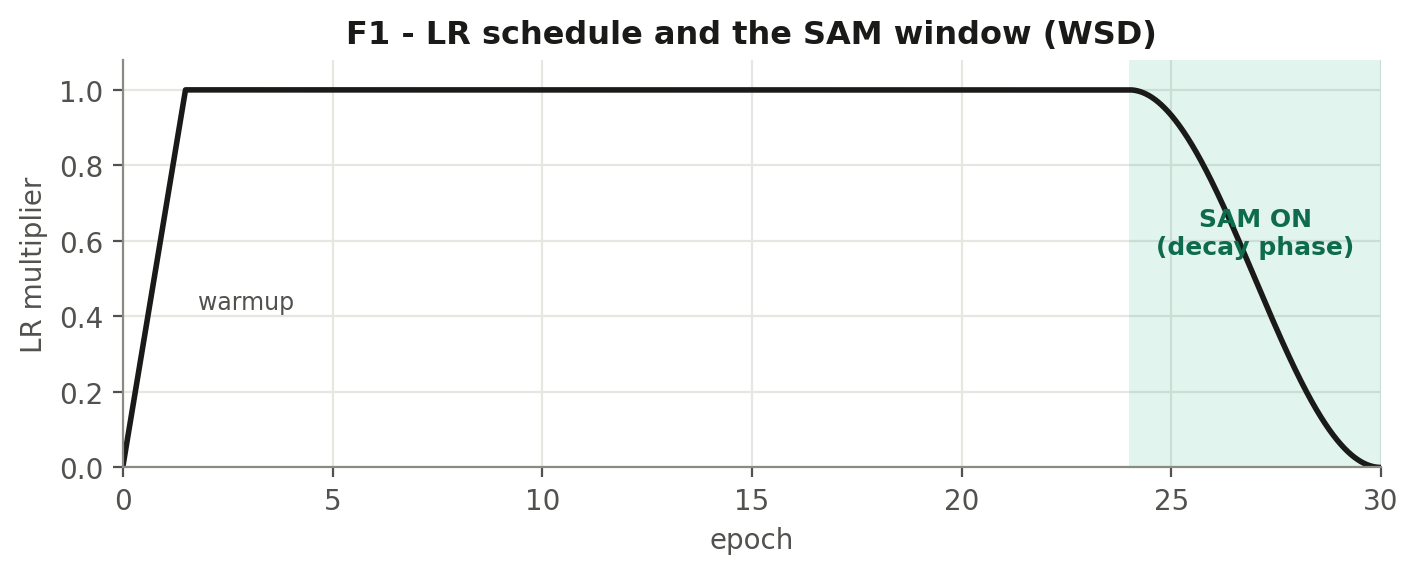

In [17]:
# --------------------------------------------------------------------------
# 2. 실험 설계 확인
# --------------------------------------------------------------------------
# 학습 전에 스케줄을 그림으로 확인한다. SAM을 언제 켜는지가 핵심 조작이므로
# 의도한 구간에 정확히 들어가 있는지 눈으로 보고 시작한다.  -> F1
# --------------------------------------------------------------------------

import matplotlib; matplotlib.use("Agg")
from IPython.display import Image, display
from sam_lab import plots
plots.fig_schedule(epochs=30, warmup_frac=0.05, decay_frac=0.20, path=f"{FIGS}/F1_schedule.png")
display(Image(f"{FIGS}/F1_schedule.png"))

In [18]:
# --------------------------------------------------------------------------
# 3. 데이터 준비
# --------------------------------------------------------------------------
# CIFAR-100 약 170MB. Internet 설정이 필요하다 (휴대폰 인증 필요).
# 꺼져 있으면 여기서 바로 멈춘다 — 3시간 돌리고 실패하는 것보다 낫다.
# --------------------------------------------------------------------------

from torchvision.datasets import CIFAR100
try:
    tr = CIFAR100(DATA, train=True, download=True); te = CIFAR100(DATA, train=False, download=True)
except Exception as e:
    raise SystemExit(f"다운로드 실패: {type(e).__name__}: {e}\n-> Settings > Internet 확인")
print(f"train {len(tr)} / test {len(te)} / 클래스 {len(tr.classes)}")

100%|██████████| 169M/169M [38:47<00:00, 72.6kB/s]


train 50000 / test 10000 / 클래스 100


In [19]:
# --------------------------------------------------------------------------
# 4. 예비 확인 — Muon 안정성 관문
# --------------------------------------------------------------------------
# 3 epoch만. 정확도가 아니라 배선이 맞는지가 목표다.
#
#   - Muon이 ResNet에서 발산하지 않는가
#   - SAM이 마지막 구간에서만 켜지는가 (sam 열이 마지막 epoch에만 0.6 근처)
#   - sam_skipped가 0인가
#
# 여기까지 통과하면 그 뒤는 같은 코드의 반복이라 위험 구간이 거의 없다.
# --------------------------------------------------------------------------

!python train.py --optimizer muon --sam_mode decay --epochs 3 --exp sanity \
    --out_dir /kaggle/working/runs --data_root /kaggle/working/data --num_workers 2


=== sanity-cifar100-resnet18-muon-sam_decay-s0  [51c51625943e] ===
    device=cuda  params=11.22M (matrix 11.21M)
    optimizer=muon lr=0.001 sam=decay(rho=0.05,l2)
    steps/epoch=195 epochs=3
[sanity-cifar100-resnet18-muon-sam_decay-s0] ep   1/3 train 4.205/7.9% val 3.704/14.3% sam 0.00 28s
[sanity-cifar100-resnet18-muon-sam_decay-s0] ep   2/3 train 3.432/18.9% val 3.162/23.5% sam 0.00 23s
[sanity-cifar100-resnet18-muon-sam_decay-s0] ep   3/3 train 2.975/26.9% val 2.824/29.8% sam 0.60 31s
    -> {"finished": true, "epochs_done": 3, "val_acc": 0.298, "best_val_acc": 0.298, "cumulative_seconds": 82.42852592468262, "sam_skipped": 0}


In [20]:
# --------------------------------------------------------------------------
# 5. 학습률 스윕  [선택]
# --------------------------------------------------------------------------
# 공정 비교의 근거. 각 옵티마이저를 자기 최적 LR에서 비교해야 순위를 주장할 수 있다.
#
# 이미 한 번 돌려서 값이 나와 있다 (adamw 0.01 / lion 3e-4 / muon 0.02).
# sweep.py가 best_lr.json이 없으면 그 값을 자동으로 쓰므로, 이 셀은 건너뛰어도
# 6단계가 정상 동작한다. 재현성 확보나 F7 그림이 필요하면 돌린다. 약 50분.
# --------------------------------------------------------------------------

!python sweep.py --phase lr --out_dir /kaggle/working/runs \
    --data_root /kaggle/working/data --num_workers 2


=== sweeplr-cifar100-resnet18-adamw-sam_off-s0-lr0.0003  [9563e681e25f] ===
    device=cuda  params=11.22M (matrix 11.21M)
    optimizer=adamw lr=0.0003 sam=off
    steps/epoch=195 epochs=15
[sweeplr-cifar100-resnet18-adamw-sam_off-s0-lr0.0003] ep   1/15 train 3.959/10.3% val 3.426/17.5% sam 0.00 18s
[sweeplr-cifar100-resnet18-adamw-sam_off-s0-lr0.0003] ep   2/15 train 3.076/23.9% val 2.951/27.2% sam 0.00 13s
[sweeplr-cifar100-resnet18-adamw-sam_off-s0-lr0.0003] ep   3/15 train 2.600/33.0% val 2.535/34.5% sam 0.00 14s
[sweeplr-cifar100-resnet18-adamw-sam_off-s0-lr0.0003] ep   4/15 train 2.282/39.8% val 2.283/40.0% sam 0.00 14s
[sweeplr-cifar100-resnet18-adamw-sam_off-s0-lr0.0003] ep   5/15 train 2.029/45.4% val 2.162/43.6% sam 0.00 14s
[sweeplr-cifar100-resnet18-adamw-sam_off-s0-lr0.0003] ep   6/15 train 1.840/49.5% val 1.916/48.5% sam 0.00 13s
[sweeplr-cifar100-resnet18-adamw-sam_off-s0-lr0.0003] ep   7/15 train 1.680/53.5% val 2.044/46.8% sam 0.00 13s
[sweeplr-cifar100-resnet18-adam

In [21]:
!cd /kaggle/working && zip -qr results.zip runs -x "*.pt"
from IPython.display import FileLink
FileLink('results.zip')

/kaggle/working/results.zip

In [22]:
# --------------------------------------------------------------------------
# 6. 본 실험 — 18 run, 약 3시간
# --------------------------------------------------------------------------
# 3 옵티마이저 x rho 6값(0, 0.02, 0.05, 0.1, 0.2, 0.4).
#
# rho를 넓게 잡은 이유: 이건 골라서 버릴 하이퍼파라미터가 아니라 교환 곡선을
# 만드는 축이다. 곡선을 그리려면 x의 분산이 필요하고, 큰 rho에서 정확도가
# 떨어지기 시작하는 구간이 곡선에서 가장 흥미로운 부분이다.
#
# Save Version > Save & Run All 로 돌릴 것. 중간에 끊겨도 다시 실행하면
# 끝난 run은 [skip]으로 건너뛴다.
# --------------------------------------------------------------------------

!python sweep.py --phase rho --out_dir /kaggle/working/runs \
    --data_root /kaggle/working/data --num_workers 2

using swept LRs: {'adamw': 0.003, 'lion': 0.0003, 'muon': 0.02}

=== rho-cifar100-resnet18-adamw-sam_off-s0-lr0.003  [2e6c0620ec7f] ===
    device=cuda  params=11.22M (matrix 11.21M)
    optimizer=adamw lr=0.003 sam=off
    steps/epoch=195 epochs=30
[rho-cifar100-resnet18-adamw-sam_off-s0-lr0.003] ep   1/30 train 3.786/12.1% val 3.968/15.8% sam 0.00 18s
[rho-cifar100-resnet18-adamw-sam_off-s0-lr0.003] ep   2/30 train 3.020/24.1% val 2.866/29.1% sam 0.00 14s
[rho-cifar100-resnet18-adamw-sam_off-s0-lr0.003] ep   3/30 train 2.403/36.6% val 2.417/38.2% sam 0.00 14s
[rho-cifar100-resnet18-adamw-sam_off-s0-lr0.003] ep   4/30 train 2.002/44.9% val 2.157/43.1% sam 0.00 14s
[rho-cifar100-resnet18-adamw-sam_off-s0-lr0.003] ep   5/30 train 1.736/51.5% val 1.925/48.6% sam 0.00 13s
[rho-cifar100-resnet18-adamw-sam_off-s0-lr0.003] ep   6/30 train 1.543/56.0% val 1.809/51.0% sam 0.00 13s
[rho-cifar100-resnet18-adamw-sam_off-s0-lr0.003] ep   7/30 train 1.382/60.0% val 1.578/56.3% sam 0.00 14s
[rho-cif

In [23]:
!cd /kaggle/working && zip -qr results.zip runs -x "*.pt"
from IPython.display import FileLink
FileLink('results.zip')

/kaggle/working/results.zip

In [24]:
# --------------------------------------------------------------------------
# 7. 측정 — 약 55분
# --------------------------------------------------------------------------
# 체크포인트마다 두 종류를 잰다. 둘 다 학습 불필요, 추론만.
#
# 평탄도        lambda_max, sam_gap, 계곡 폭
# 배포 변형     INT8/INT4 양자화, 프루닝 30~90%, 가중치 잡음
#
# 느리면 --slice_points 15 --hess_iters 10 을 붙인다.
# --------------------------------------------------------------------------

!python analyze.py --runs_dir /kaggle/working/runs --exp rho \
    --fig_dir /kaggle/working/figures --probe_batches 8 --hess_batches 1

18 runs found for exp=rho
probe set: 8 batches (2048 images)
[probe] rho-cifar100-resnet18-adamw-sam_decay-s0-lr0.003_rho0.02 ... lambda_max=29.87  sam_gap=0.02747  basin=0.667
[probe] rho-cifar100-resnet18-adamw-sam_decay-s0-lr0.003_rho0.05 ... lambda_max=26.67  sam_gap=0.06703  basin=0.800
[probe] rho-cifar100-resnet18-adamw-sam_decay-s0-lr0.003_rho0.1 ... lambda_max=22  sam_gap=0.1447  basin=0.800
[probe] rho-cifar100-resnet18-adamw-sam_decay-s0-lr0.003_rho0.2 ... lambda_max=21.65  sam_gap=0.3553  basin=0.800
[probe] rho-cifar100-resnet18-adamw-sam_decay-s0-lr0.003_rho0.4 ... lambda_max=16.1  sam_gap=0.6606  basin=0.933
[probe] rho-cifar100-resnet18-adamw-sam_off-s0-lr0.003 ... lambda_max=38.69  sam_gap=0.08267  basin=0.667
[probe] rho-cifar100-resnet18-lion-sam_decay-s0-lr0.0003_rho0.02 ... lambda_max=102.1  sam_gap=0.03773  basin=0.600
[probe] rho-cifar100-resnet18-lion-sam_decay-s0-lr0.0003_rho0.05 ... lambda_max=63.61  sam_gap=0.1044  basin=0.600
[probe] rho-cifar100-resnet18-li

18개 모델 로드

F12_dashboard


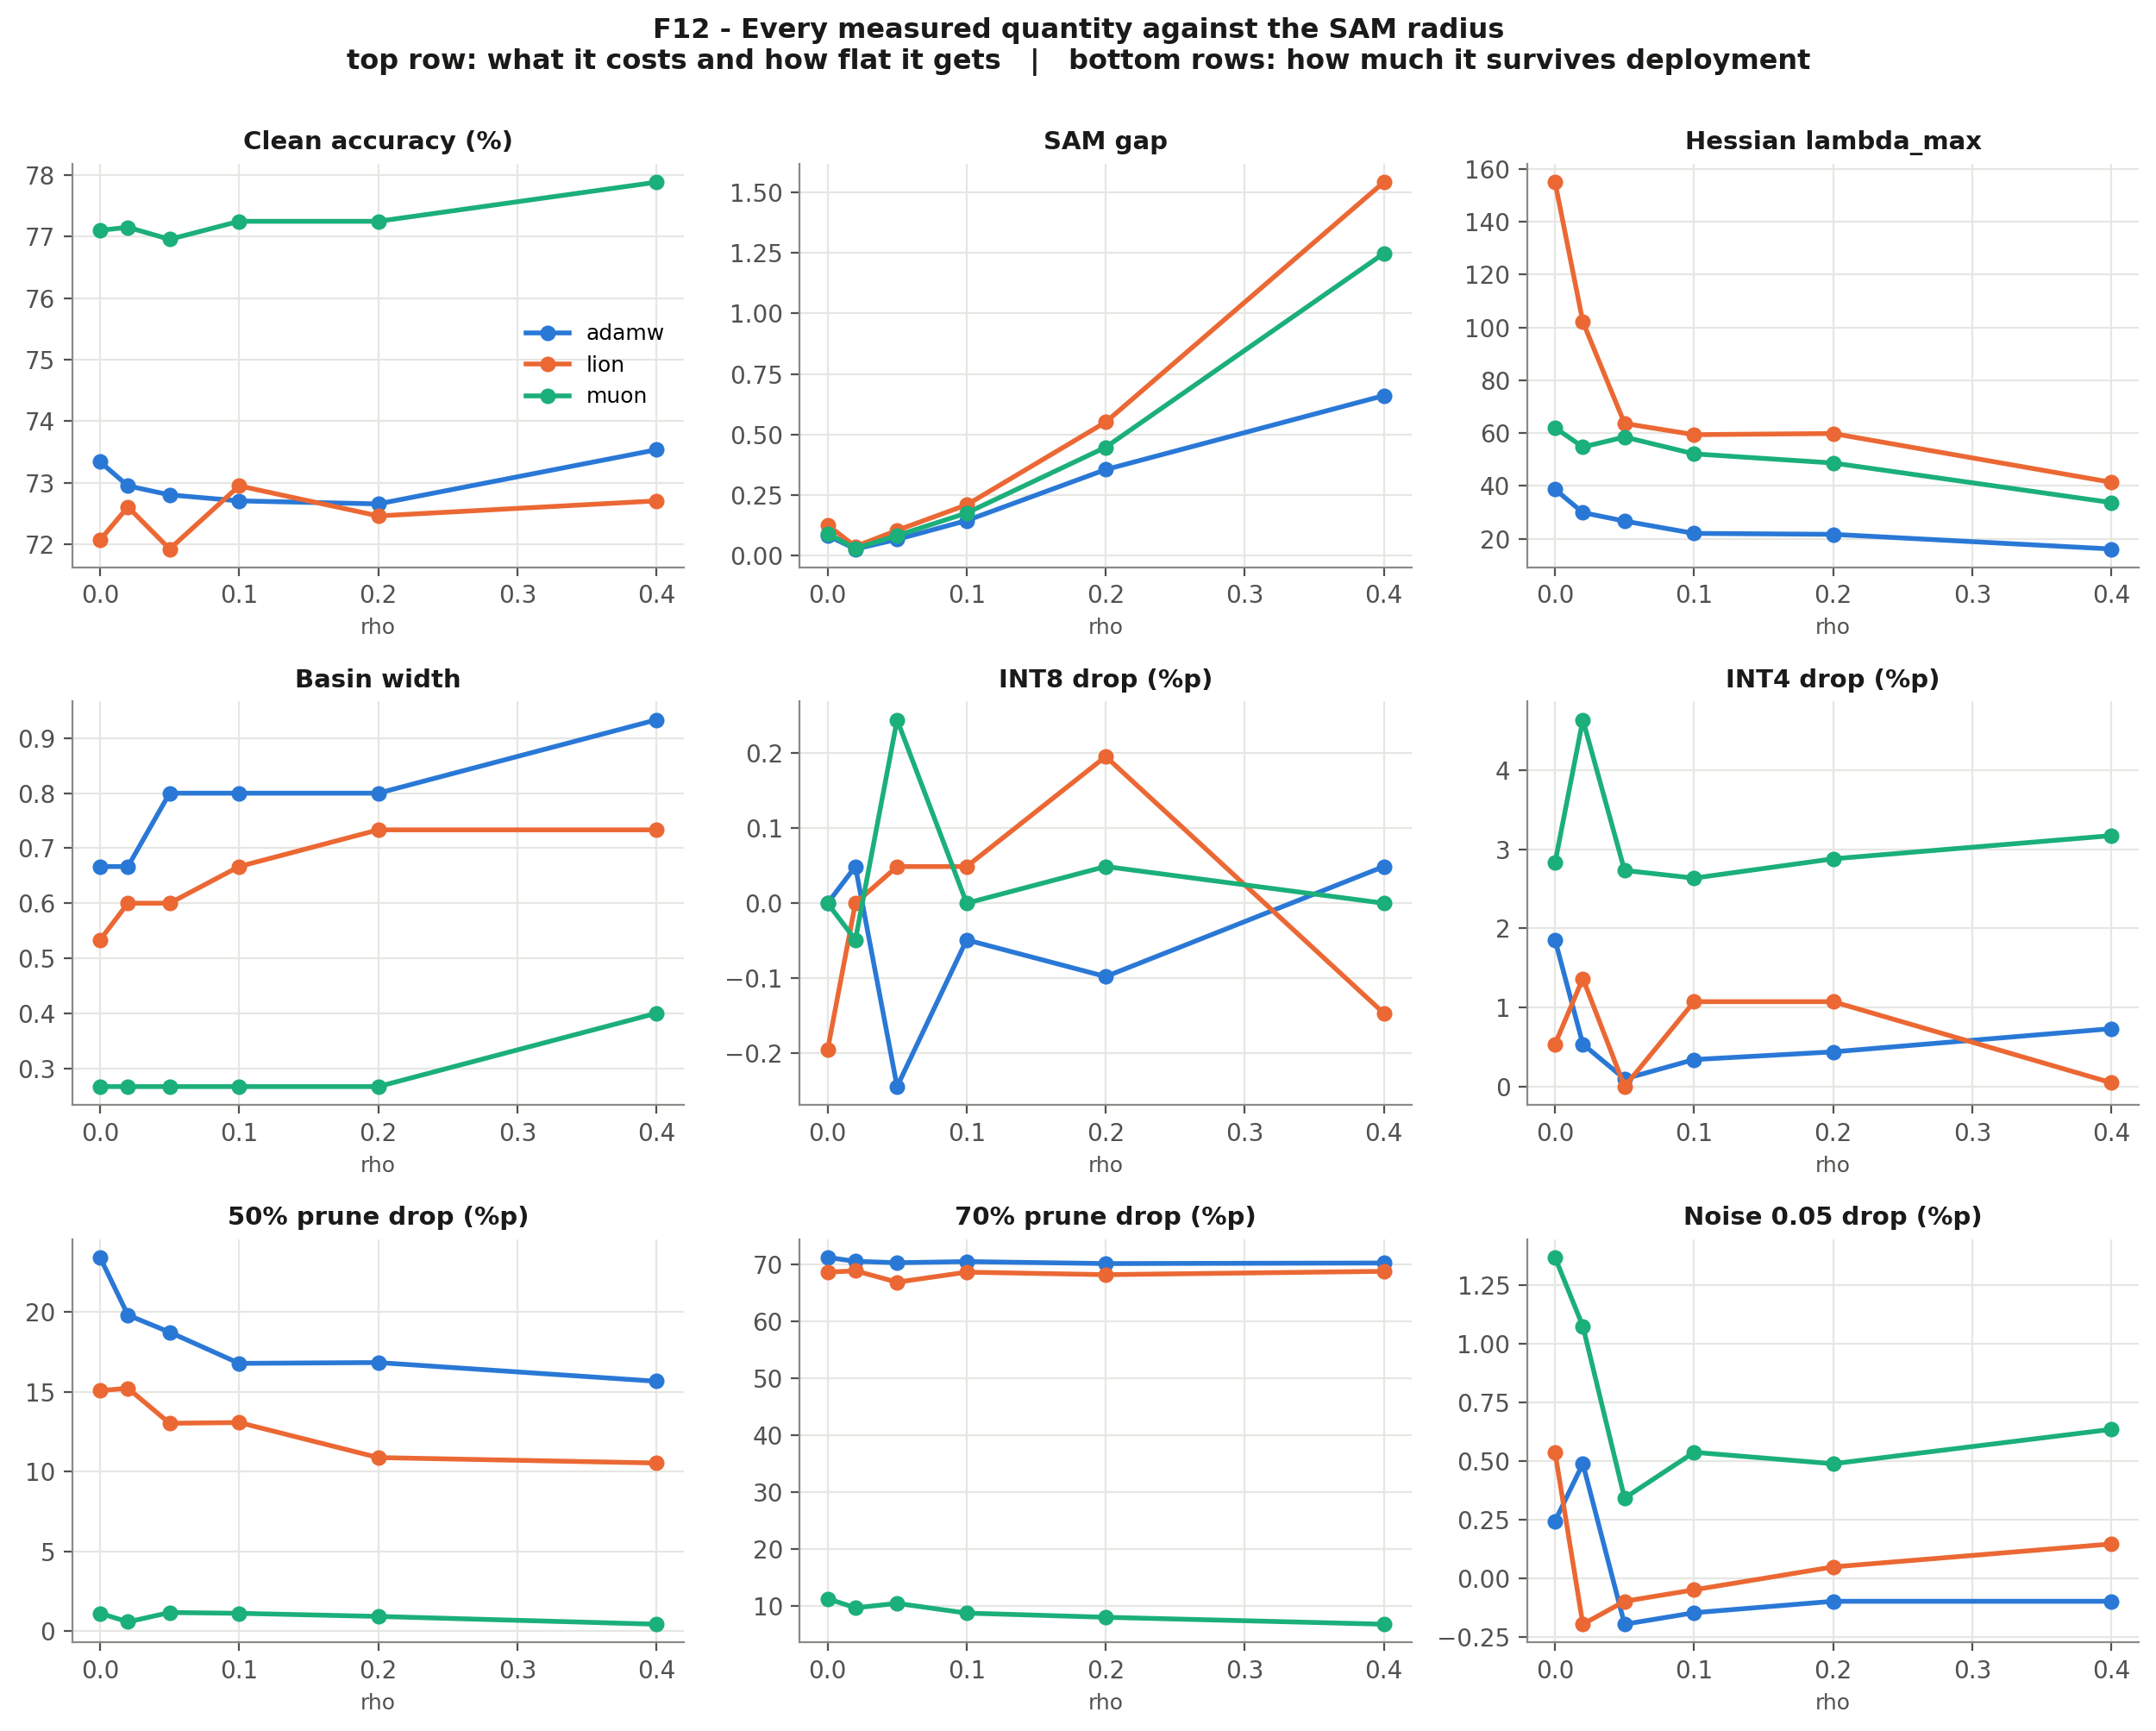


F9_tradeoff


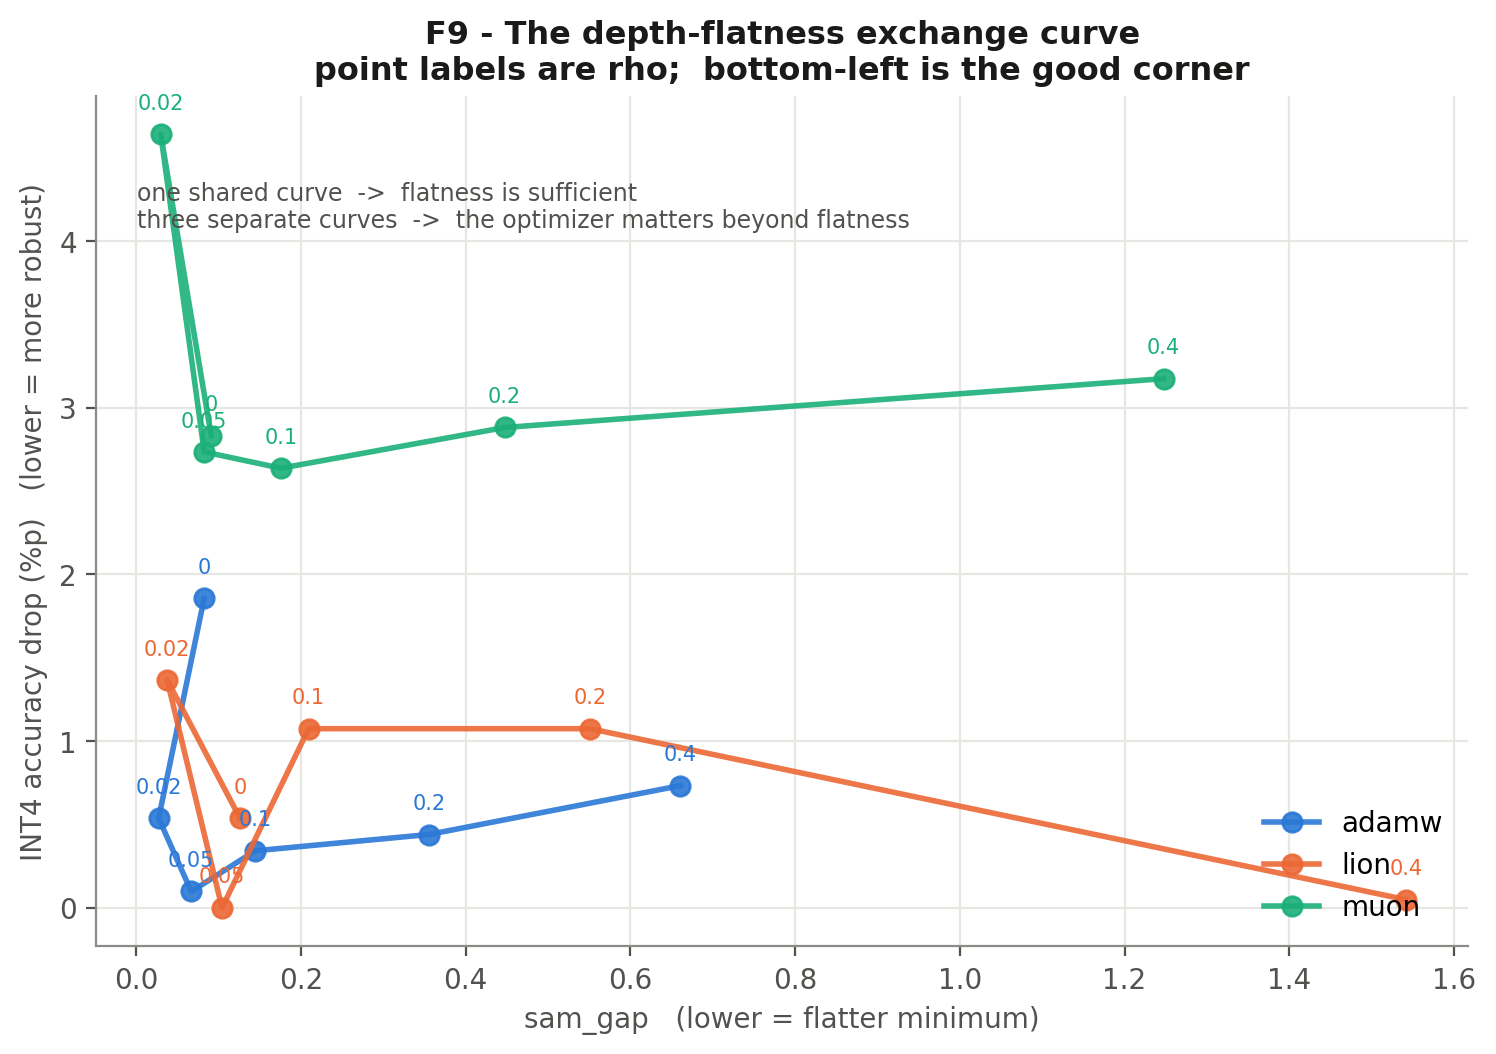


F11_predictive_power


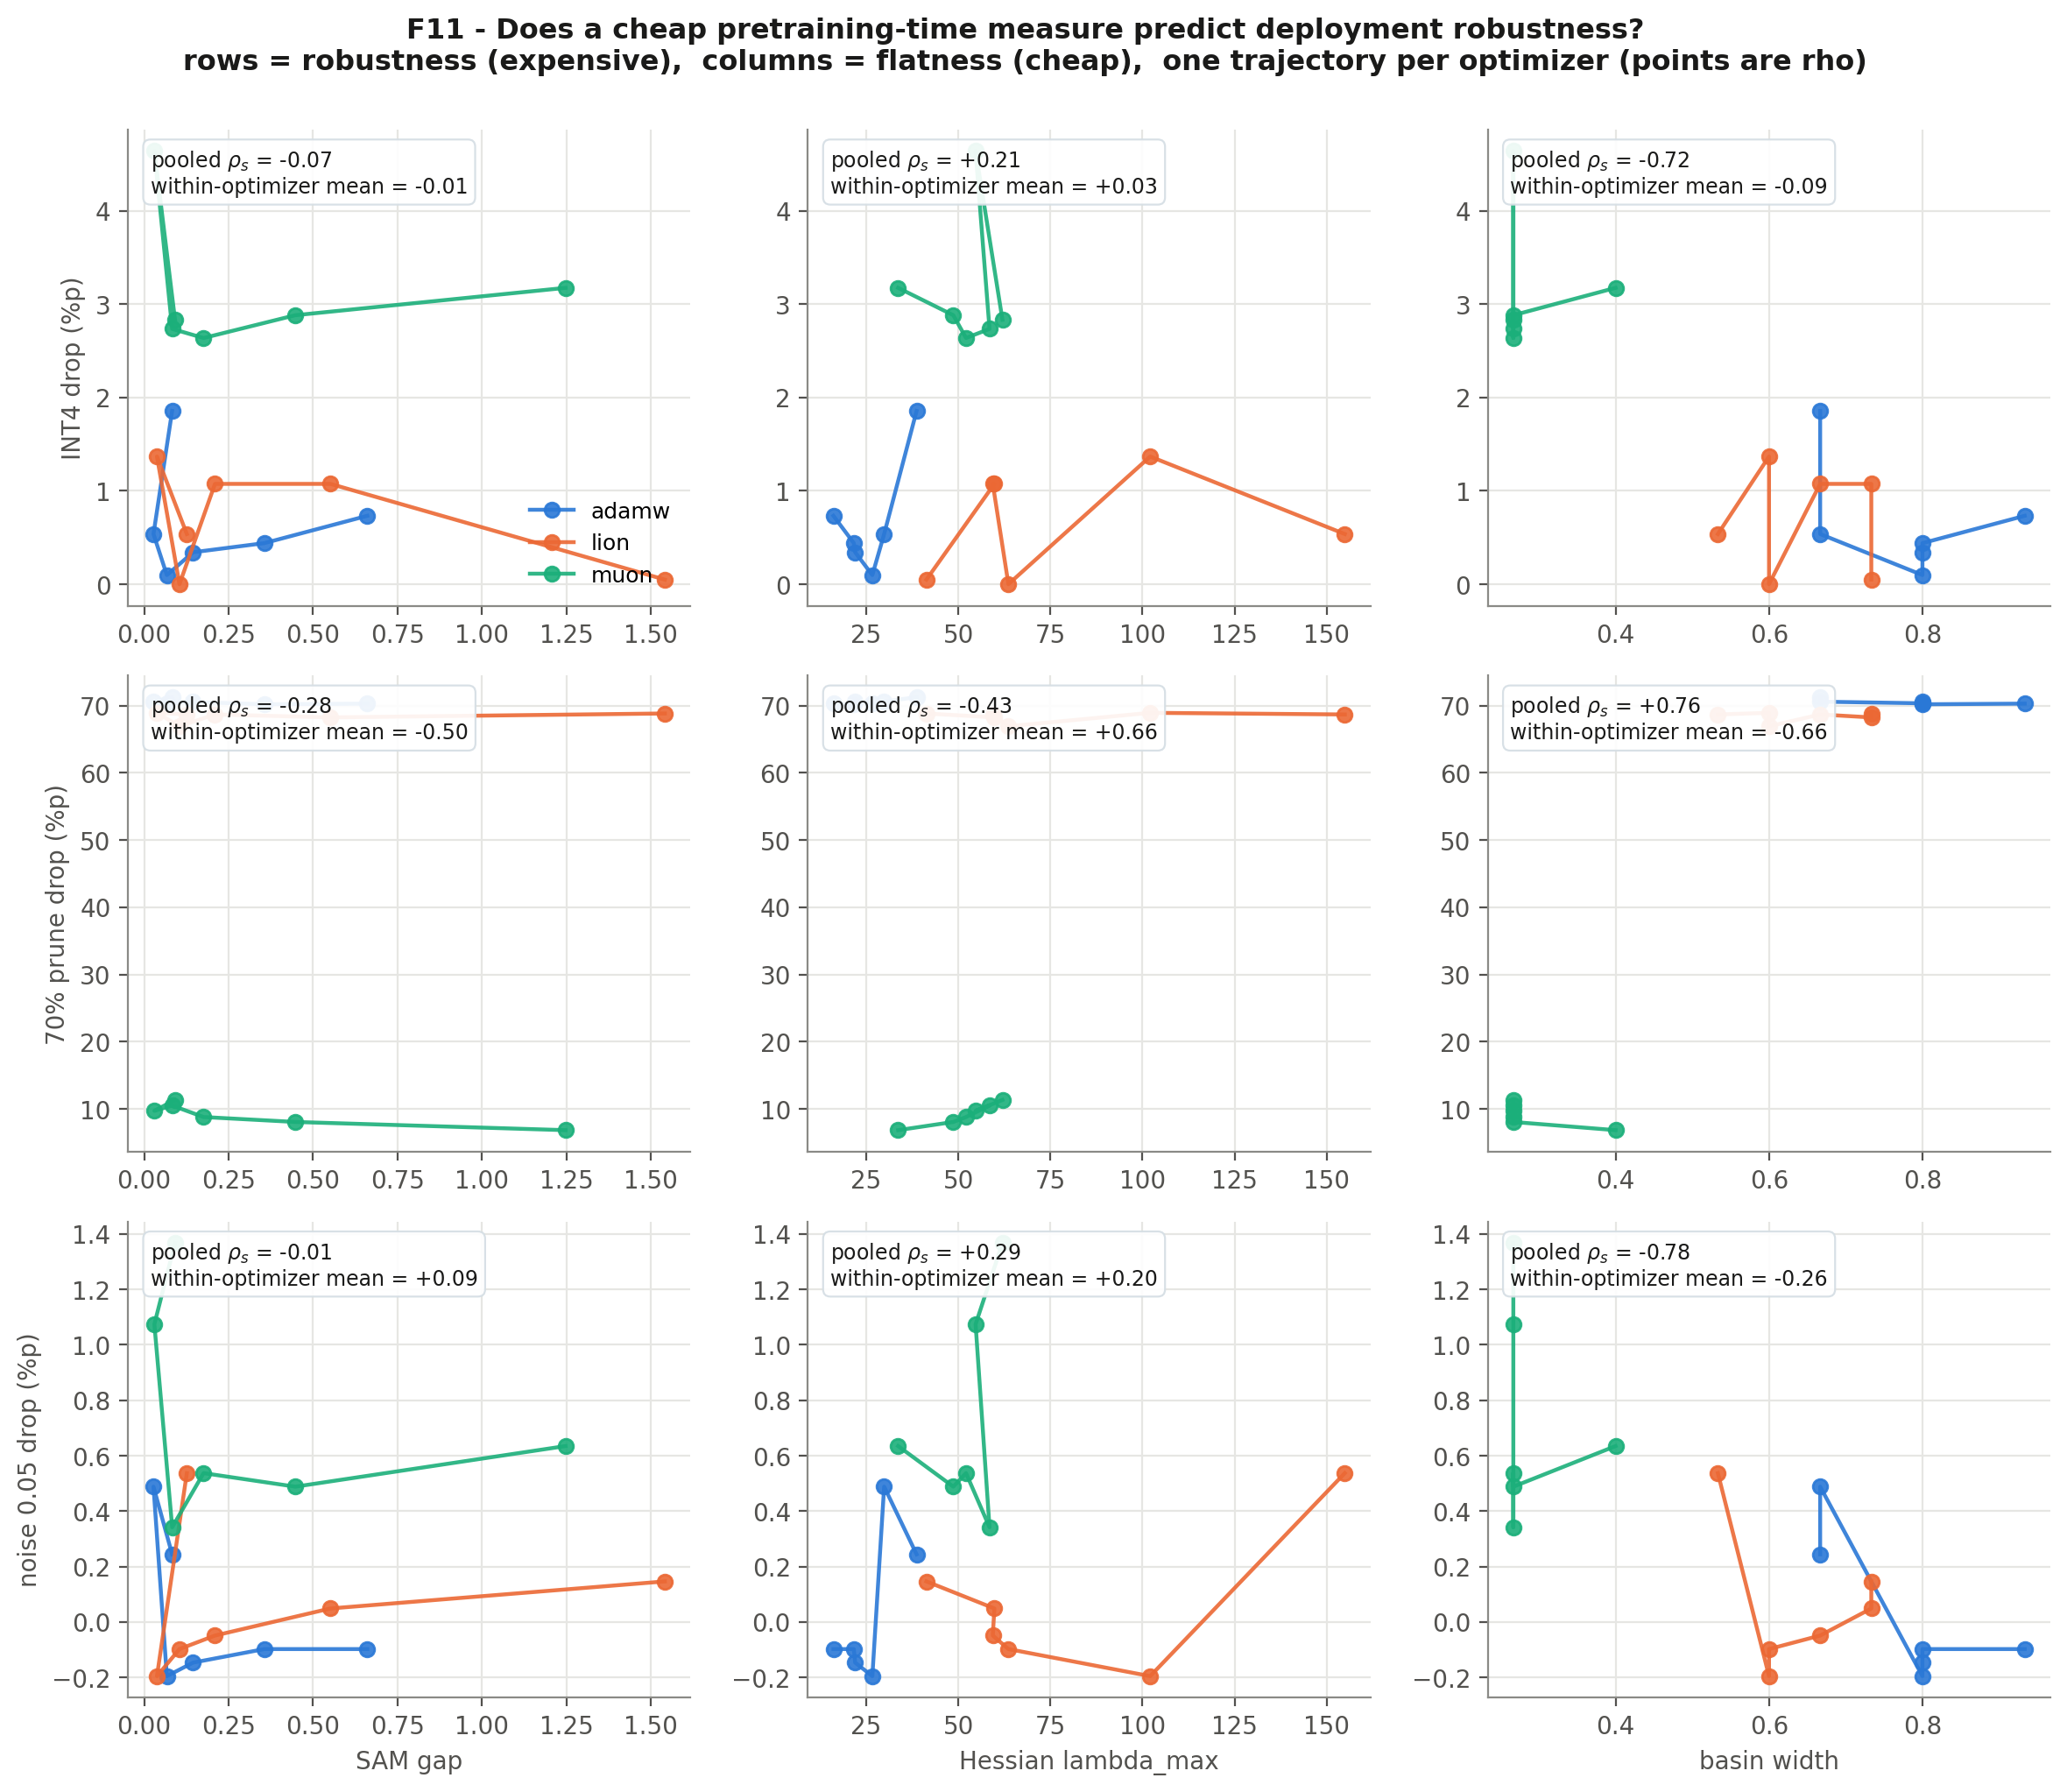


F8_rho_sweep


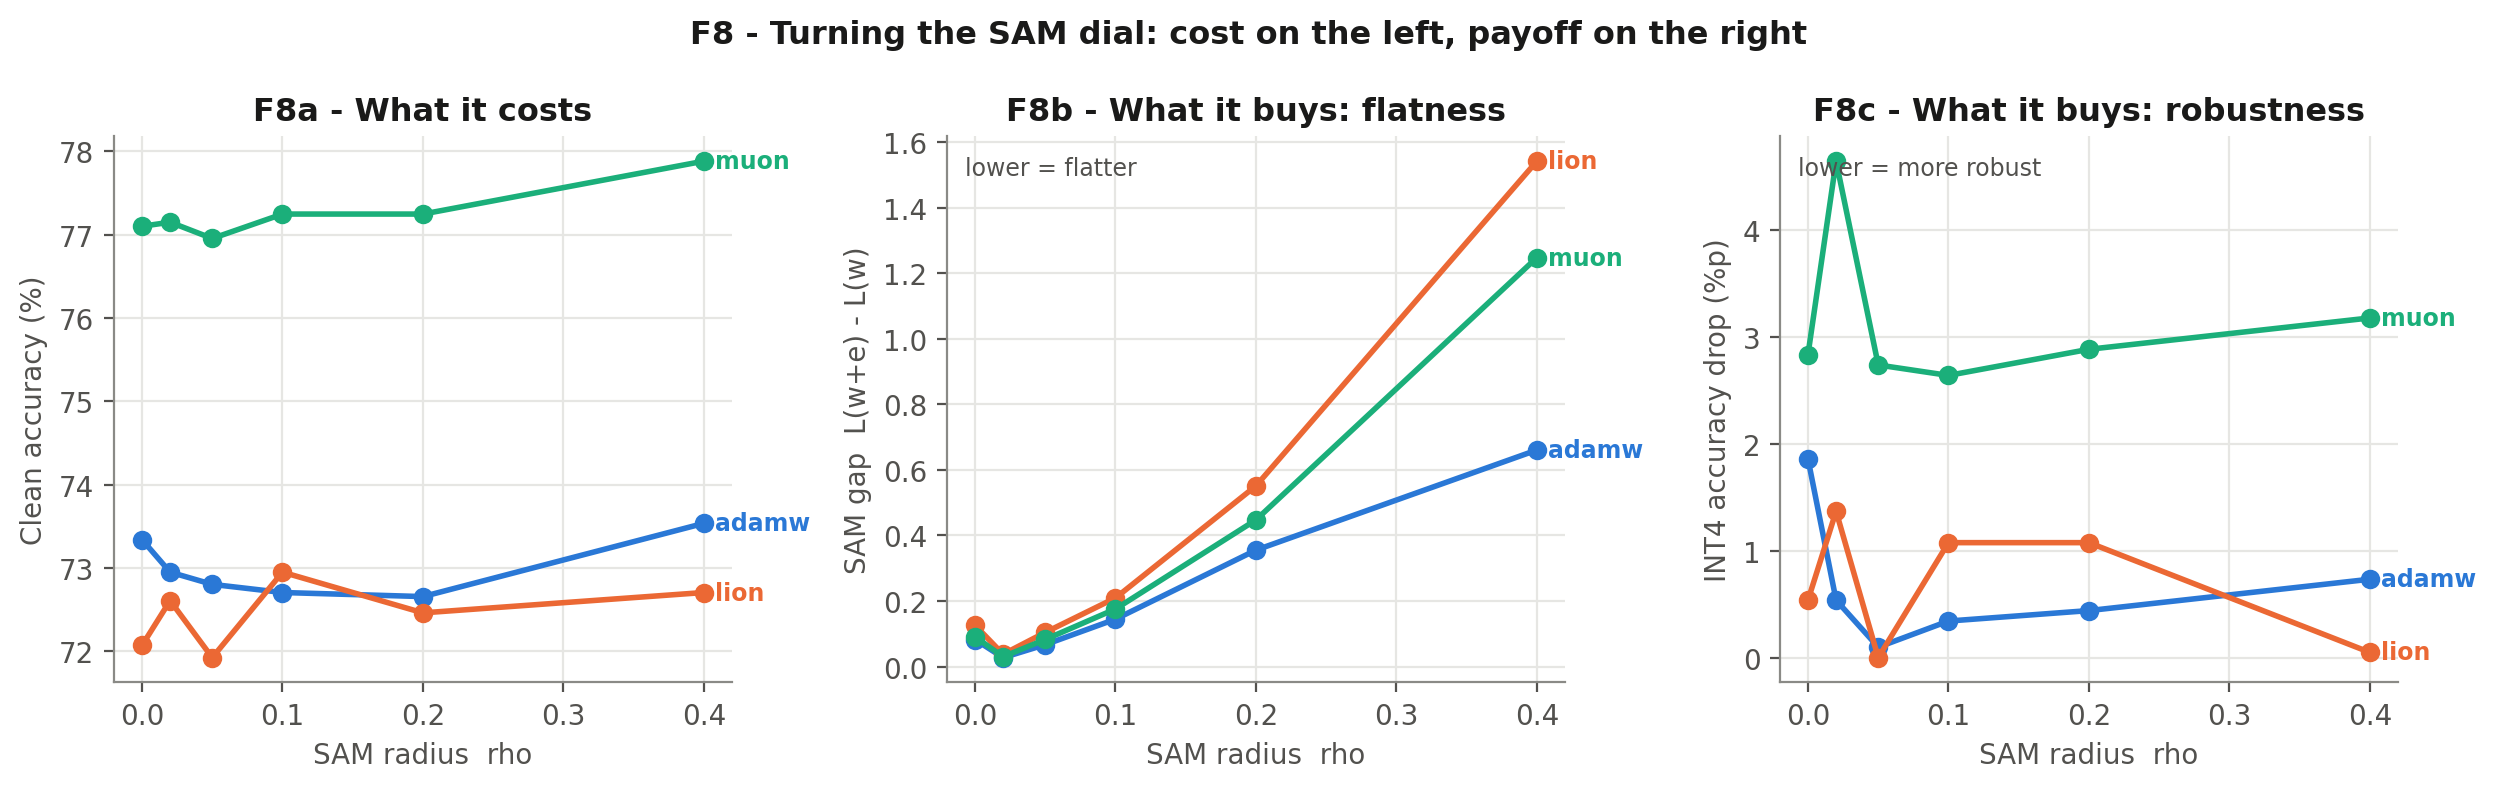


F10_degradation


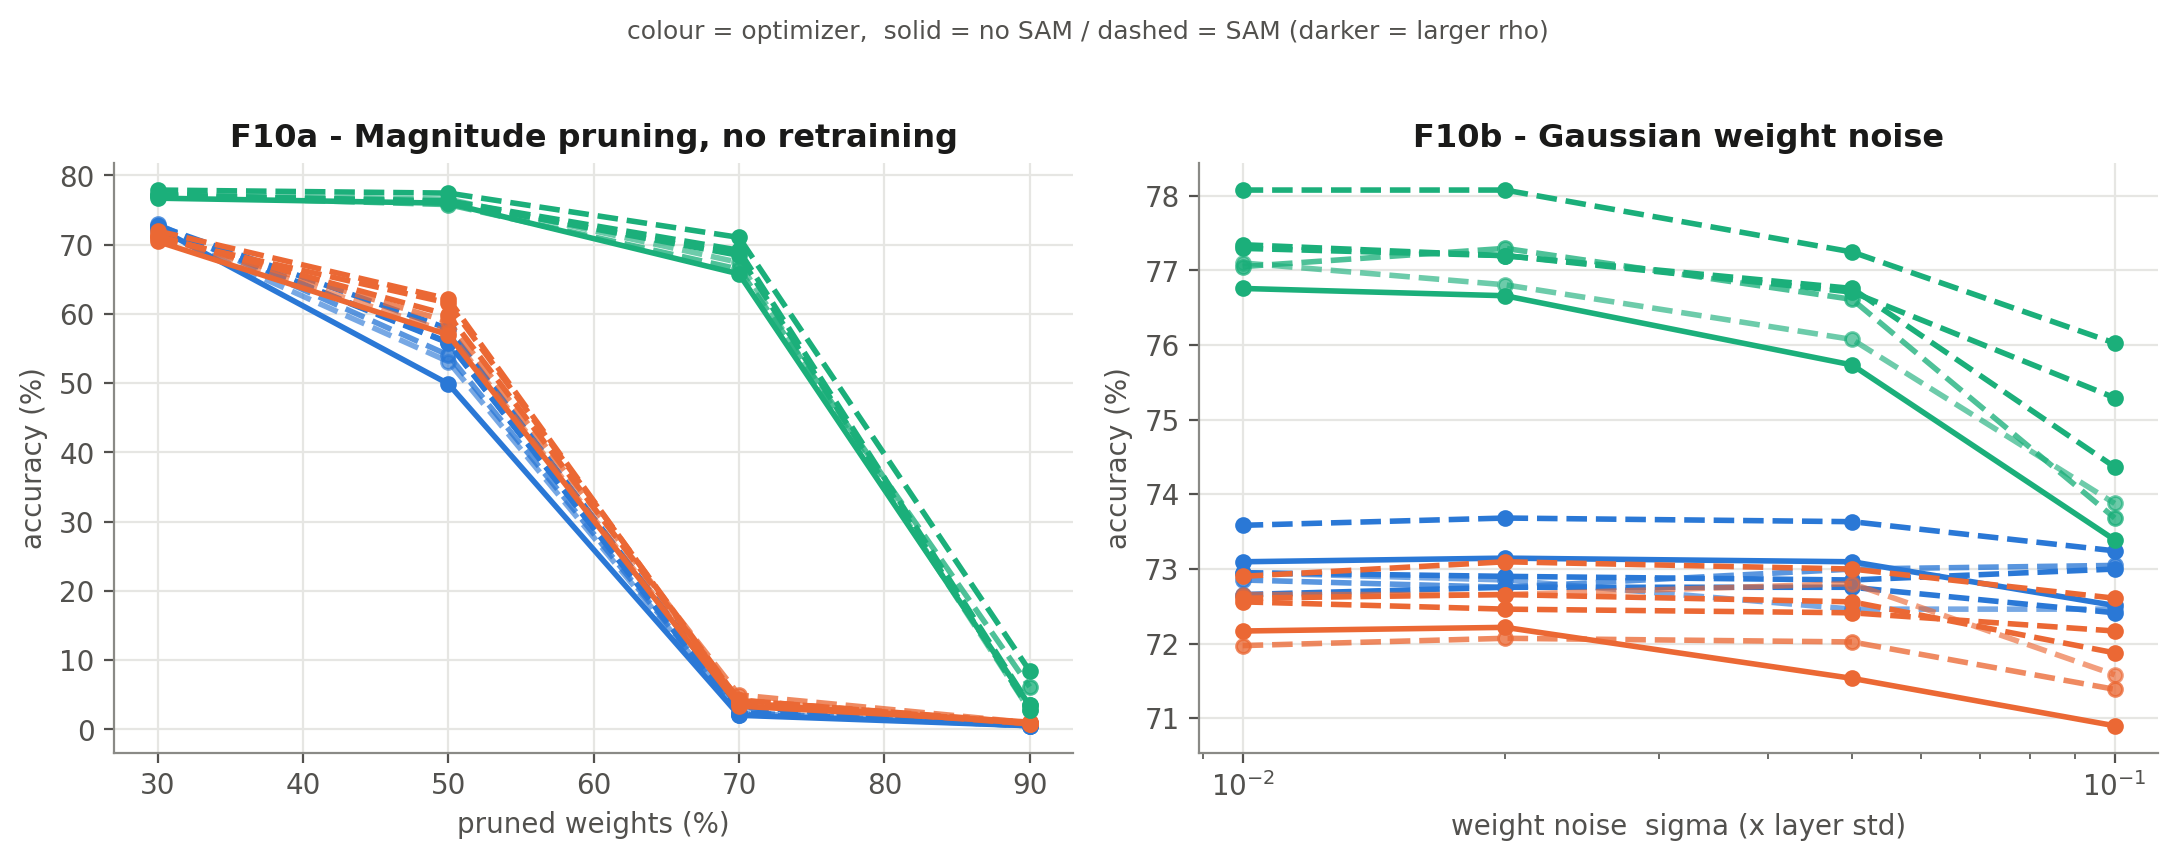


F5_landscape


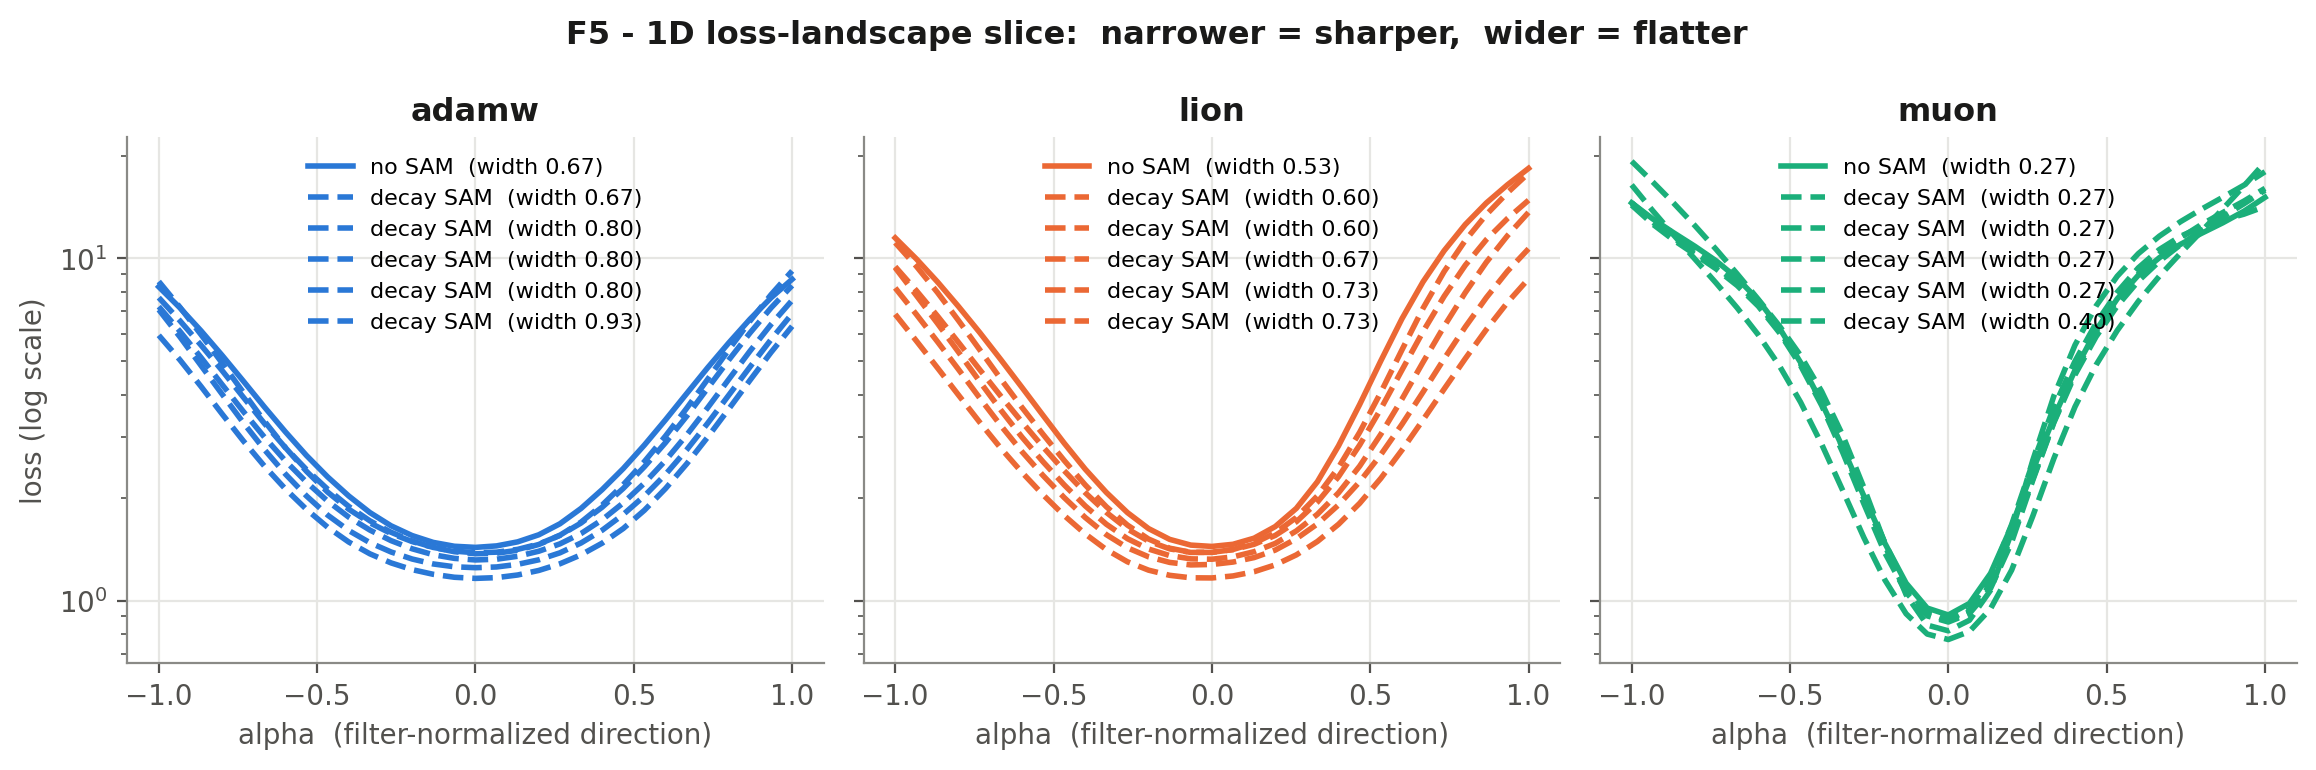


F6_sharpness


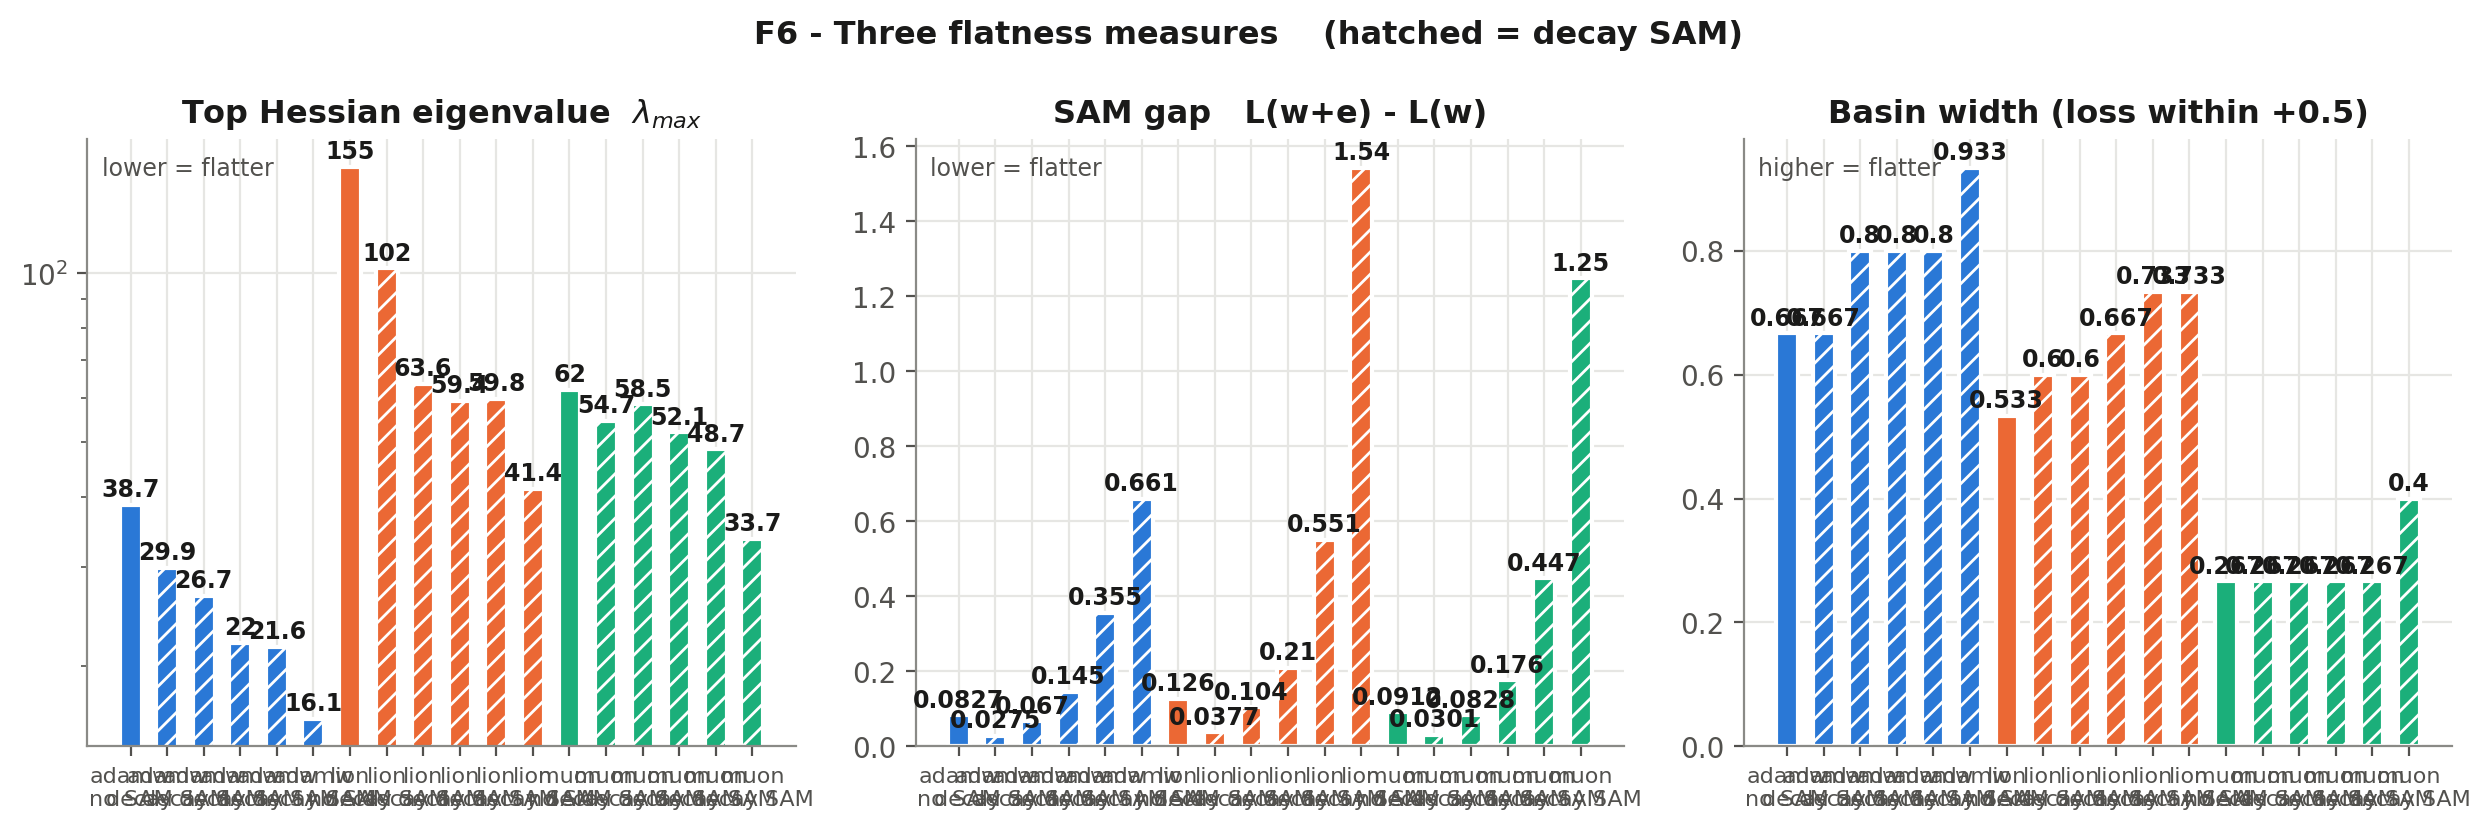


F2_curves


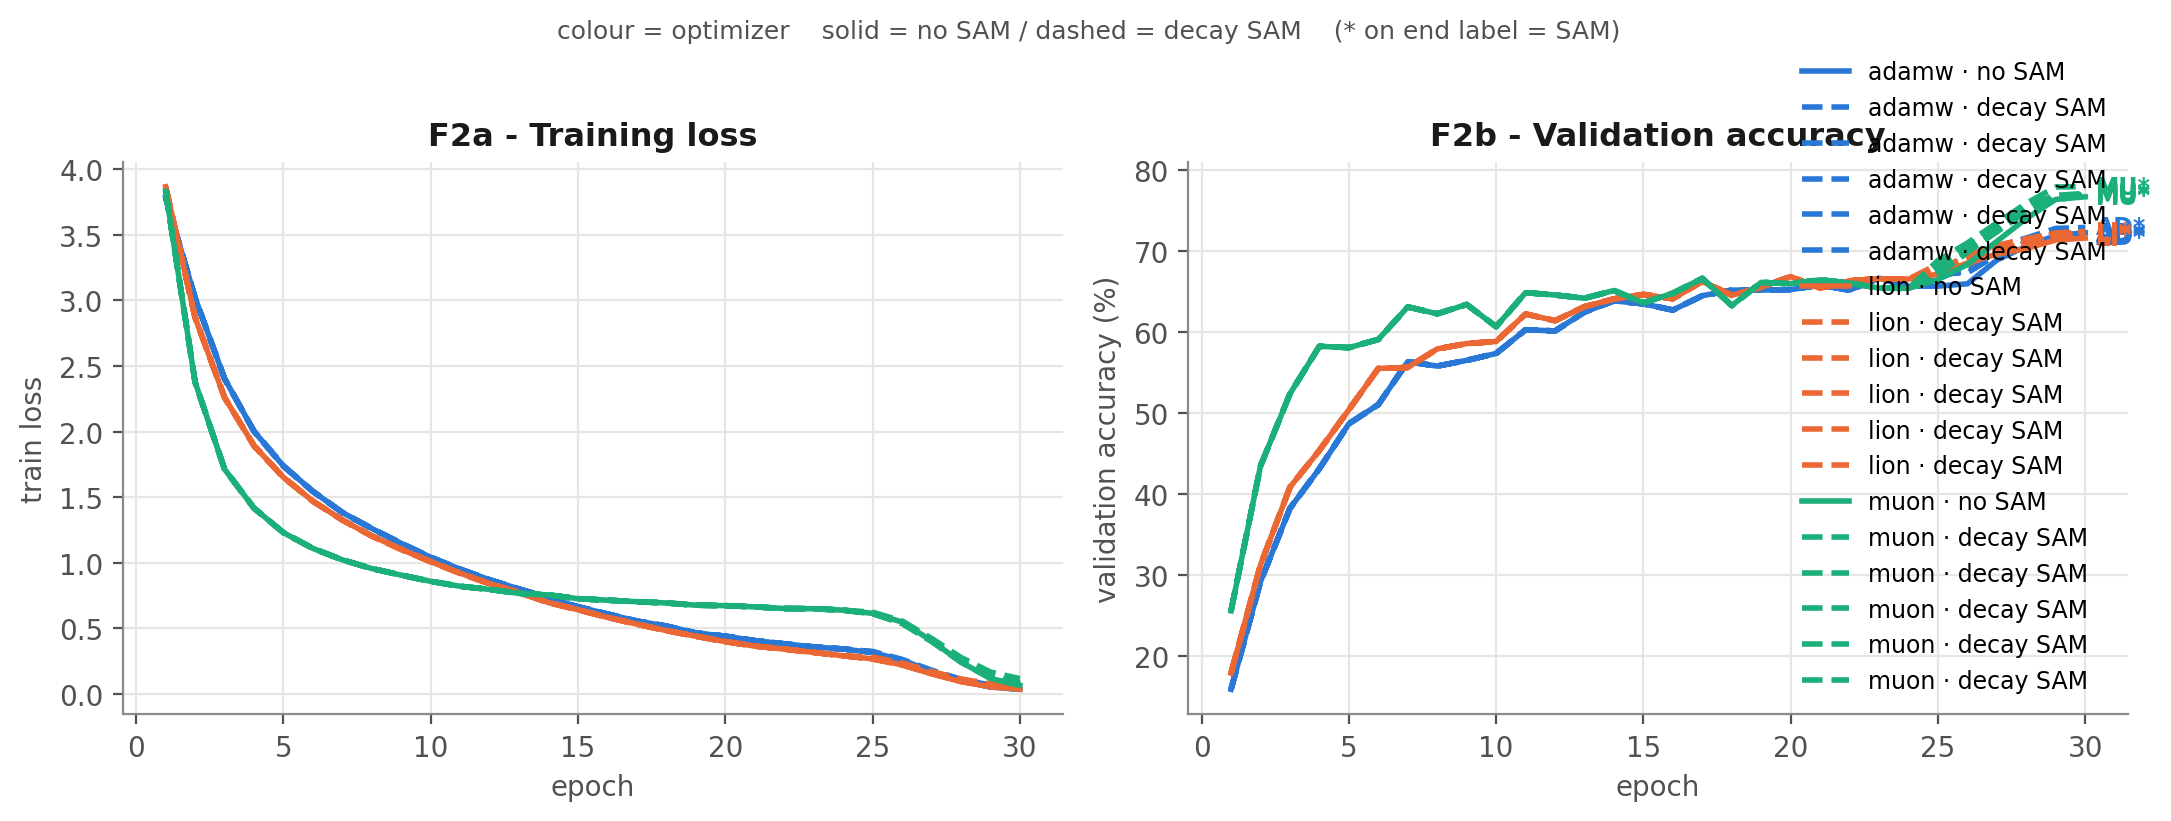


F3_gen_gap


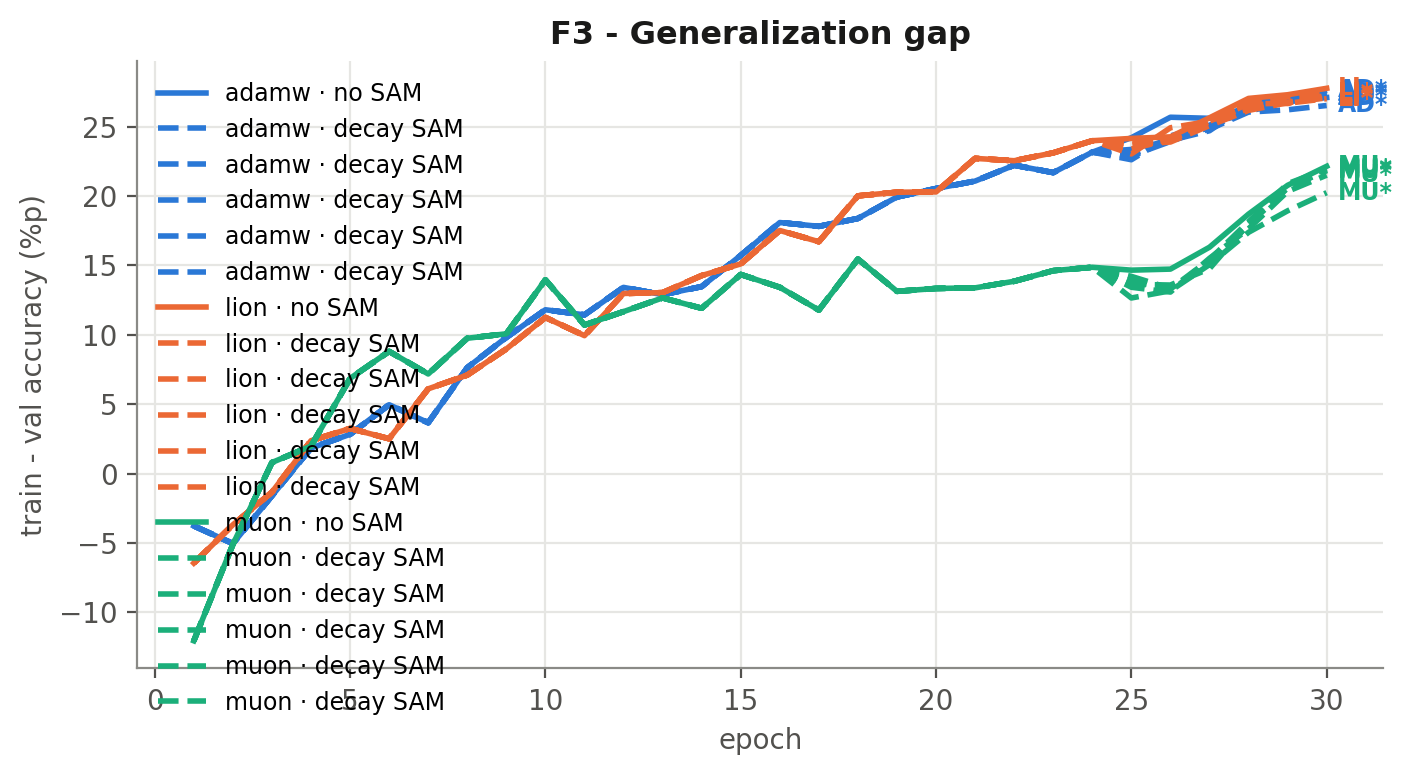


F4_time


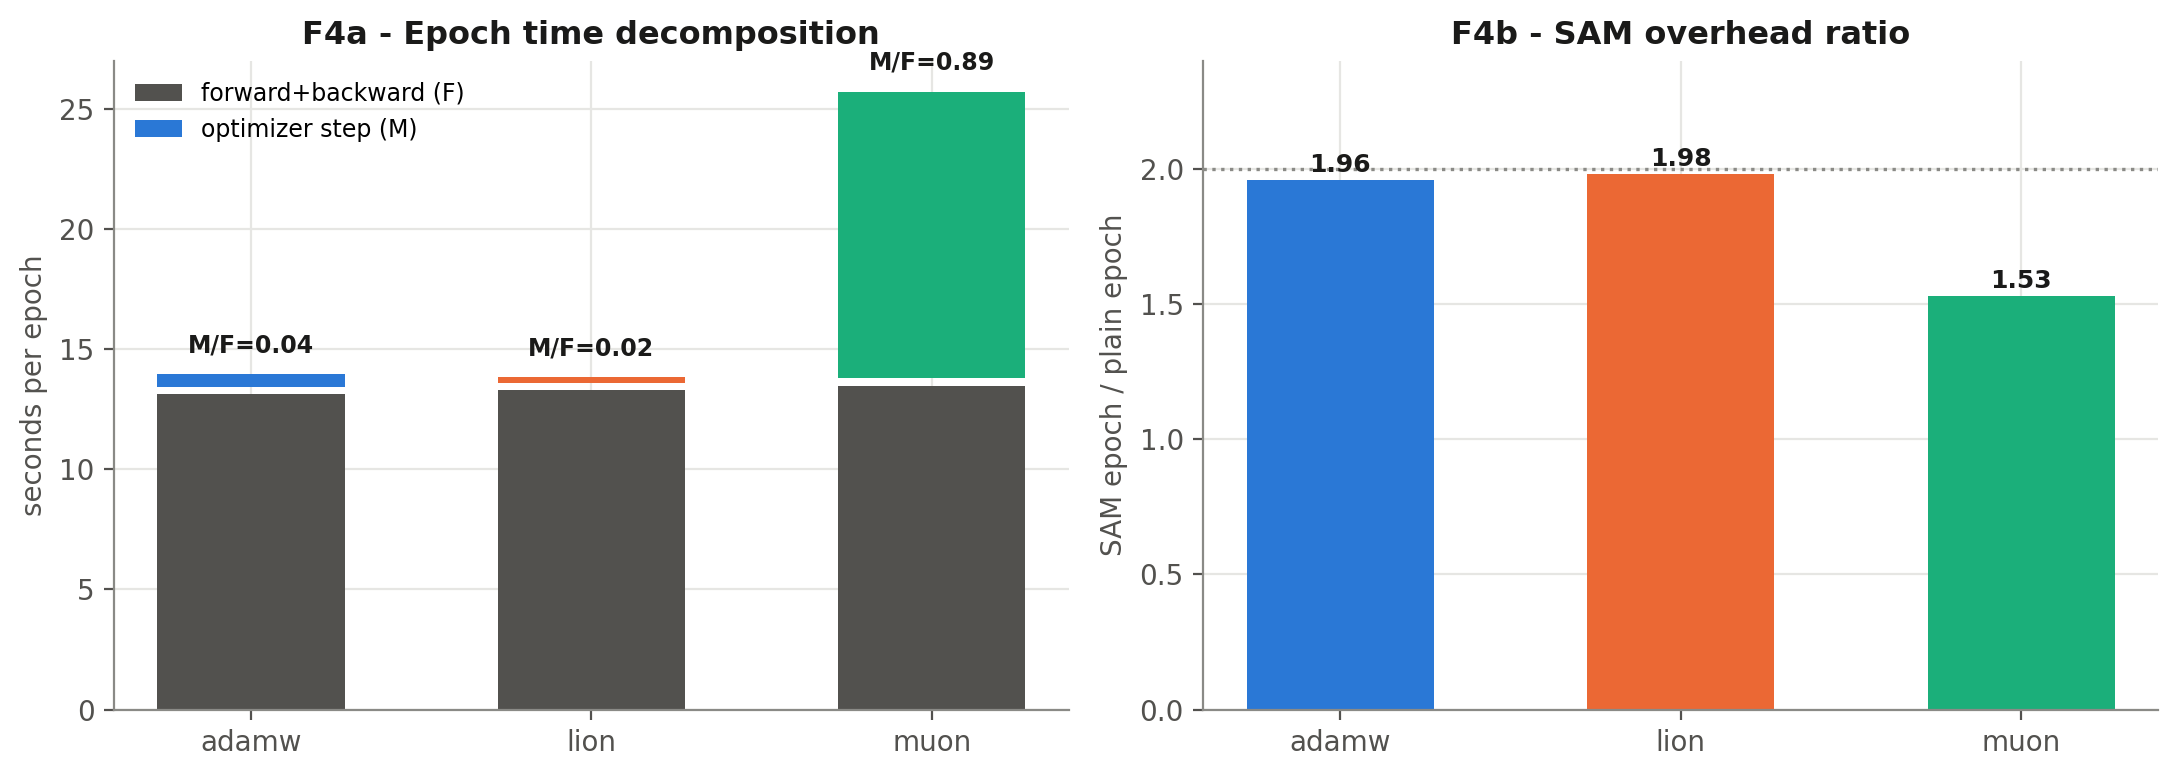


F7_lr_sweep


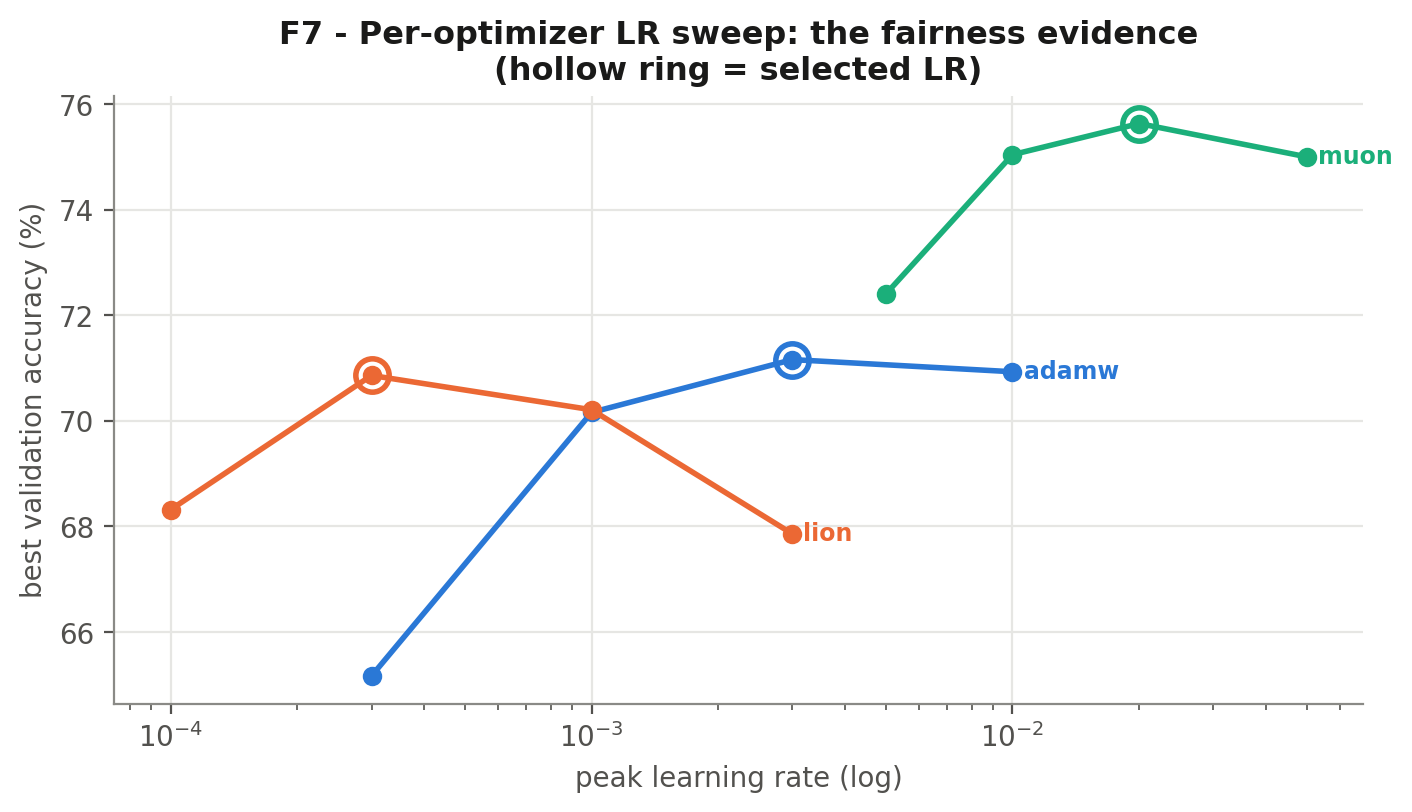


F1_schedule


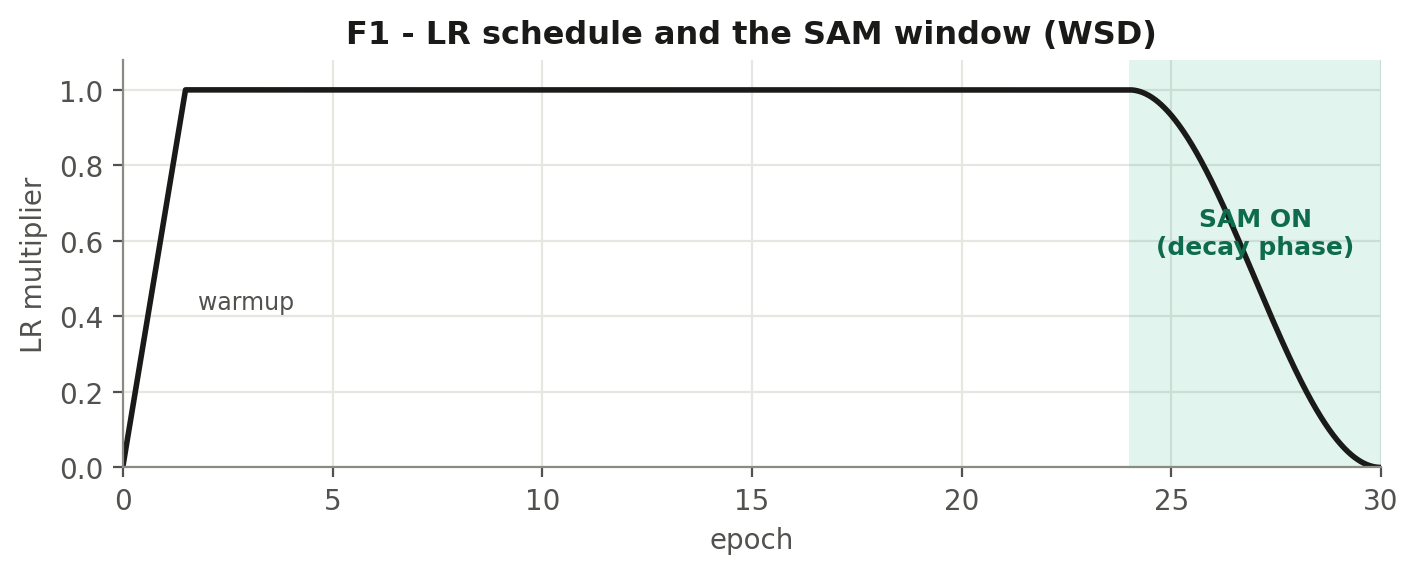


발표용 우선순위:  F9 (교환 곡선) > F12 (전체) > F11 (예측력) > F8

요약표:
optimizer   sam  rho   acc   gap  sam_gap  lam_max  basin  int8  int4  pr50  pr70  nz05  min
    adamw   off 0.00 72.22 27.10   0.0827  38.6866  0.667  0.00  1.86 23.44 71.29  0.24  6.8
    adamw decay 0.02 71.93 27.41   0.0275  29.8743  0.667  0.05  0.54 19.82 70.61  0.49  8.1
    adamw decay 0.05 72.16 27.15   0.0670  26.6719  0.800 -0.24  0.10 18.75 70.36 -0.20  8.1
    adamw decay 0.10 72.02 27.63   0.1447  22.0034  0.800 -0.05  0.34 16.80 70.56 -0.15  8.1
    adamw decay 0.20 72.07 27.35   0.3553  21.6480  0.800 -0.10  0.44 16.85 70.21 -0.10  8.1
    adamw decay 0.40 72.88 26.53   0.6606  16.1010  0.933  0.05  0.73 15.67 70.31 -0.10  8.1
     lion   off 0.00 71.57 27.77   0.1262 154.9359  0.533 -0.20  0.54 15.09 68.70  0.54  6.8
     lion decay 0.02 72.14 27.25   0.0377 102.1006  0.600  0.00  1.37 15.23 68.95 -0.20  8.1
     lion decay 0.05 72.12 27.28   0.1044  63.6105  0.600  0.05  0.00 13.04 66.94 -0.10  8.1
     lion dec

In [25]:
# --------------------------------------------------------------------------
# 9. 종합 평가 — 모든 지표를 한 번에
# --------------------------------------------------------------------------
# 7단계까지 끝난 뒤 실행한다. probes.json만 읽으므로 GPU도 재학습도 필요 없다.
#
#   F11  평탄도 지표의 예측력
#        싼 지표(사전학습 시점)가 비싼 지표(배포 변형 후)를 얼마나 예측하는가.
#        상관계수만 내놓지 않고 점을 같이 그린다 — 점이 18개뿐이라 숫자만으로는
#        오해하기 쉽기 때문이다.
#   F12  전체 지표 대시보드 — rho 축에 9개 지표를 한 화면에
# --------------------------------------------------------------------------

import json, os
import numpy as np
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

from sam_lab import plots
from sam_lab.plots import OPT_COLOR, OPT_ORDER, INK, use_house_style

RUNS = '/kaggle/working/runs'
FIGS = '/kaggle/working/figures'

probes = json.load(open(f"{RUNS}/probes.json"))
probes = {k: v for k, v in probes.items() if v.get("optimizer") in OPT_ORDER}
print(f"{len(probes)}개 모델 로드")

def rho_of(p):
    return 0.0 if p.get("sam_mode") == "off" else float(p.get("rho", 0.0))

def by_opt(probes):
    g = {}
    for p in probes.values():
        g.setdefault(p["optimizer"], []).append((rho_of(p), p))
    for o in g:
        g[o].sort(key=lambda t: t[0])
    return {o: g[o] for o in OPT_ORDER if o in g}

def spearman(x, y):
    """순위상관. 점이 적어 타이가 거의 없으므로 단순 순위로 충분하다."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    m = np.isfinite(x) & np.isfinite(y)
    if m.sum() < 3:
        return np.nan
    rx = np.argsort(np.argsort(x[m])).astype(float)
    ry = np.argsort(np.argsort(y[m])).astype(float)
    rx -= rx.mean(); ry -= ry.mean()
    d = np.sqrt((rx ** 2).sum() * (ry ** 2).sum())
    return float((rx * ry).sum() / d) if d > 0 else np.nan

# ---------------------------------------------------------------- F11
FLAT = [("sam_gap", "SAM gap", 1.0),
        ("lambda_max", "Hessian lambda_max", 1.0),
        ("basin_width", "basin width", 1.0)]
ROBUST = [("int4_drop", "INT4 drop (%p)", 100.0),
          ("prune70_drop", "70% prune drop (%p)", 100.0),
          ("noise0.05_drop", "noise 0.05 drop (%p)", 100.0)]

use_house_style()
fig, axes = plt.subplots(len(ROBUST), len(FLAT), figsize=(12.0, 10.2))

for i, (rk, rlabel, rmult) in enumerate(ROBUST):
    for j, (fk, flabel, fmult) in enumerate(FLAT):
        ax = axes[i][j]
        xs_all, ys_all = [], []
        for opt, items in by_opt(probes).items():
            xs = [p.get(fk, np.nan) * fmult for _, p in items]
            ys = [p.get(rk, np.nan) * rmult for _, p in items]
            ax.plot(xs, ys, color=OPT_COLOR[opt], marker="o", markersize=6,
                    lw=1.6, alpha=.9, label=opt if (i == 0 and j == 0) else None)
            xs_all += xs; ys_all += ys

        rho_all = spearman(xs_all, ys_all)
        per_opt = [spearman([p.get(fk, np.nan) for _, p in items],
                            [p.get(rk, np.nan) for _, p in items])
                   for items in by_opt(probes).values()]
        ax.annotate(f"pooled $\\rho_s$ = {rho_all:+.2f}\n"
                    f"within-optimizer mean = {np.nanmean(per_opt):+.2f}",
                    xy=(0.04, 0.96), xycoords="axes fraction", va="top",
                    fontsize=8.5, color=INK,
                    bbox=dict(boxstyle="round,pad=0.35", fc="#ffffff",
                              ec="#d5dee4", lw=0.8, alpha=0.92))
        if i == len(ROBUST) - 1: ax.set_xlabel(flabel)
        if j == 0: ax.set_ylabel(rlabel)

axes[0][0].legend(loc="lower right", fontsize=9)
fig.suptitle("F11 - Does a cheap pretraining-time measure predict deployment robustness?\n"
             "rows = robustness (expensive),  columns = flatness (cheap),  "
             "one trajectory per optimizer (points are rho)",
             fontsize=11.5, fontweight="600", color=INK, y=1.0)
fig.tight_layout(); fig.savefig(f"{FIGS}/F11_predictive_power.png", bbox_inches="tight")
plt.close(fig)

# ---------------------------------------------------------------- F12
PANELS = [("clean_acc", "Clean accuracy (%)", 100.0),
          ("sam_gap", "SAM gap", 1.0),
          ("lambda_max", "Hessian lambda_max", 1.0),
          ("basin_width", "Basin width", 1.0),
          ("int8_drop", "INT8 drop (%p)", 100.0),
          ("int4_drop", "INT4 drop (%p)", 100.0),
          ("prune50_drop", "50% prune drop (%p)", 100.0),
          ("prune70_drop", "70% prune drop (%p)", 100.0),
          ("noise0.05_drop", "Noise 0.05 drop (%p)", 100.0)]

use_house_style()
fig, axes = plt.subplots(3, 3, figsize=(12.6, 10.0))
for ax, (key, label, mult) in zip(axes.ravel(), PANELS):
    for opt, items in by_opt(probes).items():
        ax.plot([r for r, _ in items],
                [p.get(key, np.nan) * mult for _, p in items],
                color=OPT_COLOR[opt], marker="o", markersize=5.5, label=opt)
    ax.set_title(label, fontsize=10.5); ax.set_xlabel("rho", fontsize=9)
axes[0][0].legend(loc="best", fontsize=9)
fig.suptitle("F12 - Every measured quantity against the SAM radius\n"
             "top row: what it costs and how flat it gets   |   "
             "bottom rows: how much it survives deployment",
             fontsize=11.5, fontweight="600", color=INK, y=1.0)
fig.tight_layout(); fig.savefig(f"{FIGS}/F12_dashboard.png", bbox_inches="tight")
plt.close(fig)

# ---------------------------------------------------------------- 전체 표시
ORDER = ["F12_dashboard", "F9_tradeoff", "F11_predictive_power", "F8_rho_sweep",
         "F10_degradation", "F5_landscape", "F6_sharpness",
         "F2_curves", "F3_gen_gap", "F4_time", "F7_lr_sweep", "F1_schedule"]
for name in ORDER:
    p = f"{FIGS}/{name}.png"
    if os.path.exists(p):
        print("\n" + "=" * 72 + f"\n{name}\n" + "=" * 72)
        display(Image(p))

print("\n" + "=" * 72)
print("발표용 우선순위:  F9 (교환 곡선) > F12 (전체) > F11 (예측력) > F8")
print("=" * 72)


# ↓ 여기부터 추가
import pandas as pd
print("\n요약표:")
print(pd.read_csv(f"{RUNS}/summary_rho.csv").to_string(index=False))

In [26]:
# --------------------------------------------------------------------------
# 9. 무엇을 봐야 하는가
# --------------------------------------------------------------------------
# F9  교환 곡선  [대표 그림]
#   평탄도 대 강건성, 옵티마이저당 궤적 하나.
#   세 궤적이 한 곡선에 겹치면  -> 평탄도가 충분통계량. 옵티마이저 무관
#   세 궤적이 갈라지면          -> 옵티마이저가 평탄도로 안 잡히는 걸 남긴다
#   어느 쪽이 나와도 결과다.
#
# F11 예측력  [F9와 같은 질문을 숫자로]
#   각 칸의 두 숫자를 비교한다.
#     pooled ~= within        -> 곡선 하나. 싼 지표로 비싼 지표를 갈음 가능
#     within은 높은데 pooled 낮음 -> 옵티마이저 안에서만 예측됨. 곡선이 따로
#   그리고 세 평탄도 지표 중 상관이 제일 높은 것이 권장 지표다.
#   SAM gap이 lambda_max만큼 예측한다면, 20배 싼 지표로 충분하다는 실무 결론.
#
# F12 전체 대시보드
#   rho가 커질 때 위 줄(정확도 = 비용)과 아래 줄(강건성 = 이득)이 반대로
#   움직이면 교환이 성립한다. 둘 다 나빠지면 그 rho는 그냥 과한 것.
#
# F8  rho 스윕 3패널
#   (a) 정확도가 얼마나 떨어지는가   = 비용
#   (b) 평탄도가 얼마나 좋아지는가   = 중간 변수
#   (c) 양자화 강건성이 얼마나 오르는가 = 이득
#   (a)와 (c)의 비율이 교환비이고, 옵티마이저마다 다른지가 핵심.
#
# F2  decay-SAM과 SAM 없음의 정확도가 거의 겹치는 것이 예상된 결과다.
#     CMU 논문(arXiv 2605.02105)도 SAM이 사전학습 손실을 나쁘게 만든다고 했다.
#     정확도에 차이가 없다는 건 실패가 아니라 효과가 다른 곳에 있다는 뜻이다.
#
# F4  F(forward+backward) 막대가 세 옵티마이저에서 같아야 한다.
#     SAM Overlay가 실제로 backward를 한 번 더 한다는 직접 증거.
#
# 다음 단계
#   교환 곡선이 나오면 모델을 ViT-Lite-7/4로 바꿔 같은 실험을 반복한다.
#   Muon은 원래 transformer용이라 conv reshape 꼼수가 없어져 더 깔끔해진다.
#   다만 ViT는 처음부터 학습하면 epoch이 30 -> 200으로 늘어난다.
# --------------------------------------------------------------------------

print("S0 파일럿 완료")

S0 파일럿 완료
